# Úprava dát

Predikcia priemernej hodinovej koncentrácie CO pomocou regresných modelov. Výstup `co` je v mg/m³; do vstupov modelov nevstupuje.

## Prostredie a reprodukovateľnosť

In [87]:
import copy
import os
import random
import time
from importlib.metadata import version

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
from joblib import parallel_backend
from threadpoolctl import threadpool_limits
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid, train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, silhouette_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
import torch
from torch import nn

SEED = 2026
N_JOBS = 2
CV_FOLDS = 3
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
sns.set_theme(style="whitegrid", palette="viridis", context="notebook")
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 100)
versions = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "xgboost", "torch"]}


## Načítanie a význam stĺpcov

`instant` je identifikátor, `date` označuje deň merania. Päť senzorov poskytuje odozvy bez fyzikálnej jednotky. Nejde o priamo zmerané koncentrácie jednotlivých plynov. `co` pochádza z referenčného analyzátora. Teplota je v °C a relatívna vlhkosť v %. Dátum nebudem kódovať stovkami one-hot stĺpcov: časové informácie už obsahujú mesiac, hodinu, deň v týždni a ročné obdobie.

In [88]:
data = pd.read_csv("air_quality.csv")
SENSORS = ["sensor_co", "sensor_nmhc", "sensor_nox", "sensor_no2", "sensor_o3"]
CONTINUOUS = SENSORS + ["temperature", "humidity"]
TARGET = "co"
assert set(["instant", "date", "month", "hour", "weekday", "season", *CONTINUOUS, TARGET]) == set(data.columns)
display(data.head())
display(data.describe().T.round(3))


,instant,date,month,hour,weekday,season,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity,co
0,1,2004-03-10,3,18,3,spring,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,2.6
1,2,2004-03-10,3,19,3,spring,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,2.0
2,3,2004-03-10,3,20,3,spring,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,2.2
3,4,2004-03-10,3,21,3,spring,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,2.2
4,5,2004-03-10,3,22,3,spring,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,1.6


,count,mean,std,min,25%,50%,75%,max
instant,9507.0,4681.998,2700.183,1.0,2345.5,4683.0,7016.5,9357.0
month,9507.0,6.317,3.439,1.0,3.0,6.0,9.0,12.0
hour,9507.0,11.505,6.926,0.0,5.5,12.0,18.0,23.0
weekday,9507.0,3.004,2.003,0.0,1.0,3.0,5.0,6.0
sensor_co,9139.0,1099.538,217.088,647.0,936.0,1063.0,1231.0,2040.0
sensor_nmhc,9139.0,938.890,266.843,383.0,734.0,909.0,1117.0,2214.0
sensor_nox,9139.0,835.881,257.021,322.0,658.0,806.0,969.5,2683.0
sensor_no2,9139.0,1455.835,346.719,551.0,1224.5,1463.0,1674.0,2775.0
sensor_o3,9139.0,1022.488,398.597,221.0,731.0,962.0,1274.0,2523.0
temperature,9139.0,18.325,8.842,-1.9,11.8,17.8,24.4,44.6


Načítal som **9,507 riadkov a 14 stĺpcov**. Merania pokrývajú obdobie **2004-03-10 až 2005-04-04**. Minimum, maximum a kvartily pomáhajú odlíšiť bežnú variabilitu od možnej chyby. Samotná vysoká koncentrácia CO ešte nie je chybný záznam.

## Kvalita dát
### Chýbajúce hodnoty, duplicity a platnosť

Odstraňujem riadky s NA, a nerobím imputáciu. Duplicity skontrolujem ešte pred rozdelením, aby rovnaké meranie neskončilo v tréningu aj teste. Pri dátume overím parsovanie a súlad s mesiacom a dňom v týždni. Uvedené rozsahy senzorov v PDF sú približné, preto ich nepoužívam ako tvrdé limity.

,Typ,NA,Unikátne
instant,int64,0,9357
date,str,0,391
month,int64,0,12
hour,int64,0,24
weekday,int64,0,7
season,str,0,4
sensor_co,float64,368,1041
sensor_nmhc,float64,368,1245
sensor_nox,float64,368,1221
sensor_no2,float64,368,1603


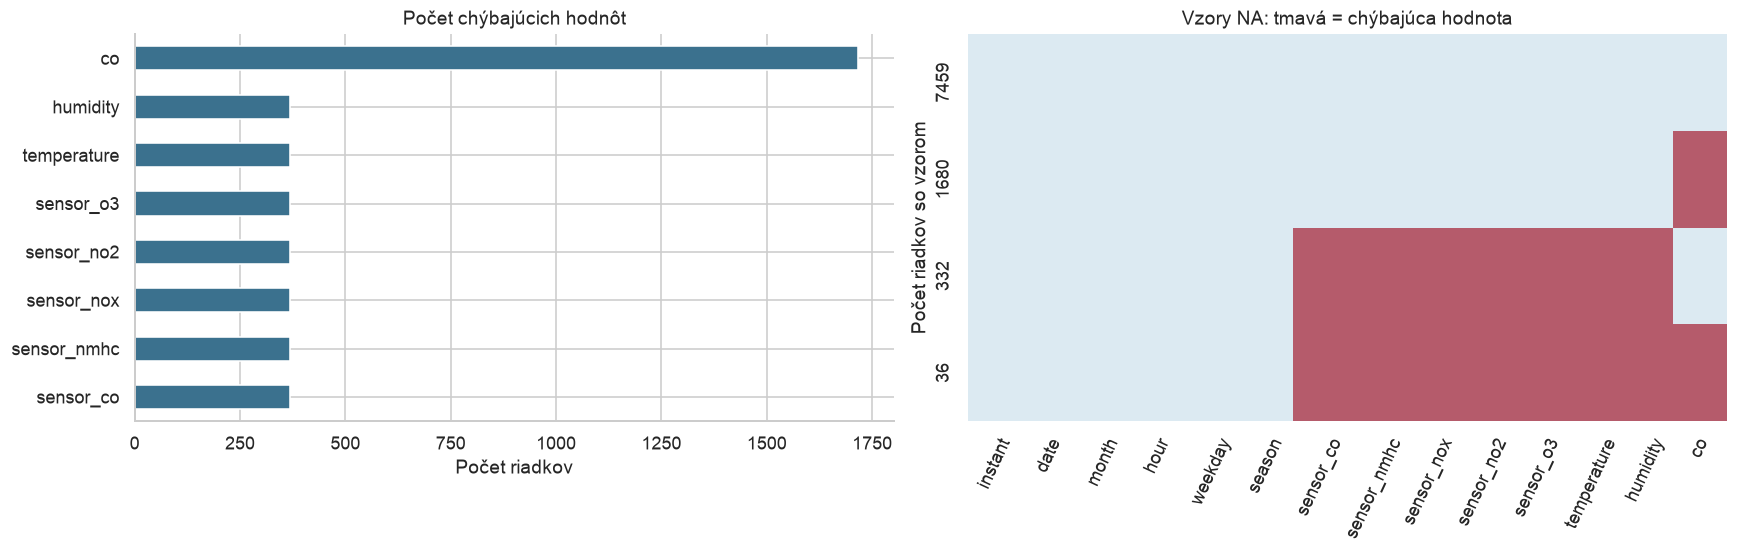

In [89]:
missing = data.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({"Typ": data.dtypes.astype(str), "NA": data.isna().sum(), "Unikátne": data.nunique()})
display(quality)
patterns = data.isna().value_counts().rename("Počet").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.7), constrained_layout=True)
missing[missing > 0].sort_values().plot.barh(ax=axes[0], color="#3b718e")
axes[0].set(title="Počet chýbajúcich hodnôt", xlabel="Počet riadkov")
sns.heatmap(patterns[data.columns].astype(int), cmap=["#dceaf2", "#b55b6b"], cbar=False,
            yticklabels=patterns["Počet"], ax=axes[1])
axes[1].set(title="Vzory NA: tmavá = chýbajúca hodnota", ylabel="Počet riadkov so vzorom")
axes[1].tick_params(axis="x", rotation=65)
plt.show()
duplicate_count = int(data.duplicated().sum())
without_id_dups = int(data.drop(columns="instant").duplicated().sum())


Dataset obsahuje **150 úplných duplicít**, bez identifikátora je ich 150. Cieľ chýba v **1716 riadkoch**. Spoločné vzory chýbania senzorov naznačujú výpadky merania.

In [90]:
unique_data = data.drop_duplicates().copy()
complete_data = unique_data.dropna().copy()
dates = pd.to_datetime(complete_data.date, errors="coerce")
valid = (
    dates.notna()
    & complete_data.month.between(1, 12)
    & complete_data.hour.between(0, 23)
    & complete_data.weekday.between(0, 6)
    & complete_data.season.isin(["winter", "spring", "summer", "autumn"])
    & complete_data.humidity.between(0, 100)
    & complete_data.temperature.between(-30, 60)
    & complete_data.co.ge(0)
    & complete_data[SENSORS].gt(0).all(axis=1)
    & complete_data[CONTINUOUS + [TARGET]].apply(np.isfinite).all(axis=1)
    & complete_data.month.eq(dates.dt.month)
    & complete_data.weekday.eq((dates.dt.dayofweek + 1) % 7)
)
data_clean = complete_data.loc[valid].copy()
cleaning = pd.DataFrame([
    ["Pôvodné údaje", len(data), 0],
    ["Po odstránení duplicít", len(unique_data), len(data) - len(unique_data)],
    ["Po odstránení NA", len(complete_data), len(unique_data) - len(complete_data)],
    ["Po kontrole platnosti", len(data_clean), int((~valid).sum())],
], columns=["Krok", "Zostáva", "Odstránené v kroku"])
display(cleaning)
assert not data_clean.isna().any().any() and not data_clean.duplicated().any()


,Krok,Zostáva,Odstránené v kroku
0,Pôvodné údaje,9507,0
1,Po odstránení duplicít,9357,150
2,Po odstránení NA,7344,2013
3,Po kontrole platnosti,7344,0


Po čistení zostalo **7,344 úplných a platných meraní** (77.2% pôvodných riadkov). Teploty nad približných 40 °C automaticky nemažem: stále môžu byť reálnym meraním. Štatistické outliery odstránim až z tréningových dát pomocou hraníc naučených výhradne na danom tréningu.

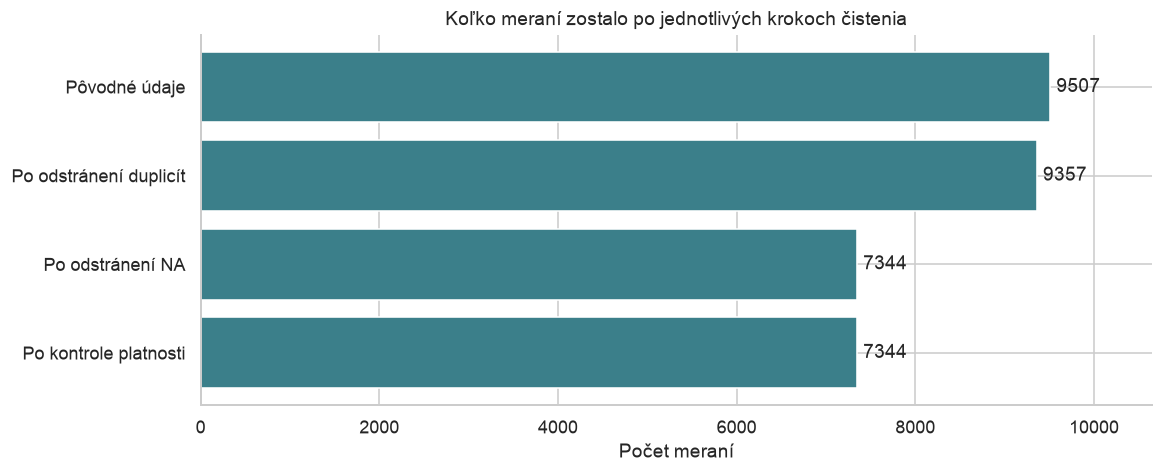

In [91]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
bars = ax.barh(cleaning['Krok'], cleaning['Zostáva'], color='#3b7f8a')
ax.bar_label(bars, padding=4, fmt='%d')
ax.invert_yaxis()
ax.set(title='Koľko meraní zostalo po jednotlivých krokoch čistenia', xlabel='Počet meraní', xlim=(0, len(data)*1.12))
plt.show()

Čistenie znížilo počet meraní z **9 507 na 7 344**. Jednotlivé kroky odstraňujú prekrývajúce sa problémy postupne, preto počty chýbajúcich hodnôt v stĺpcoch nemožno jednoducho sčítať. Hranice štatistických outlierov sa budú učiť až na tréningu a osobitne v každom CV folde.

# EDA – bonus

EDA opisuje vyčistené dáta. Jej závery nemenia rozdelenie dát ani vopred zvolené hyperparametrické mriežky.

## Rozdelenia senzorov a koncentrácie
### Histogramy a boxploty

Histogram ukazuje tvar rozdelenia a boxplot medián, kvartily a odľahlé body. Boxplot používa bežné fúzy $1{,}5 \times \mathrm{IQR}$ len na vizualizáciu. Pravidlo pre odstránenie tréningových outlierov bude konzervatívnejšie, $3 \times \mathrm{IQR}$. CO do tohto odstraňovania nezahrniem, aby som hodnotenie nezjednodušil vymazaním vysokých cieľových hodnôt.

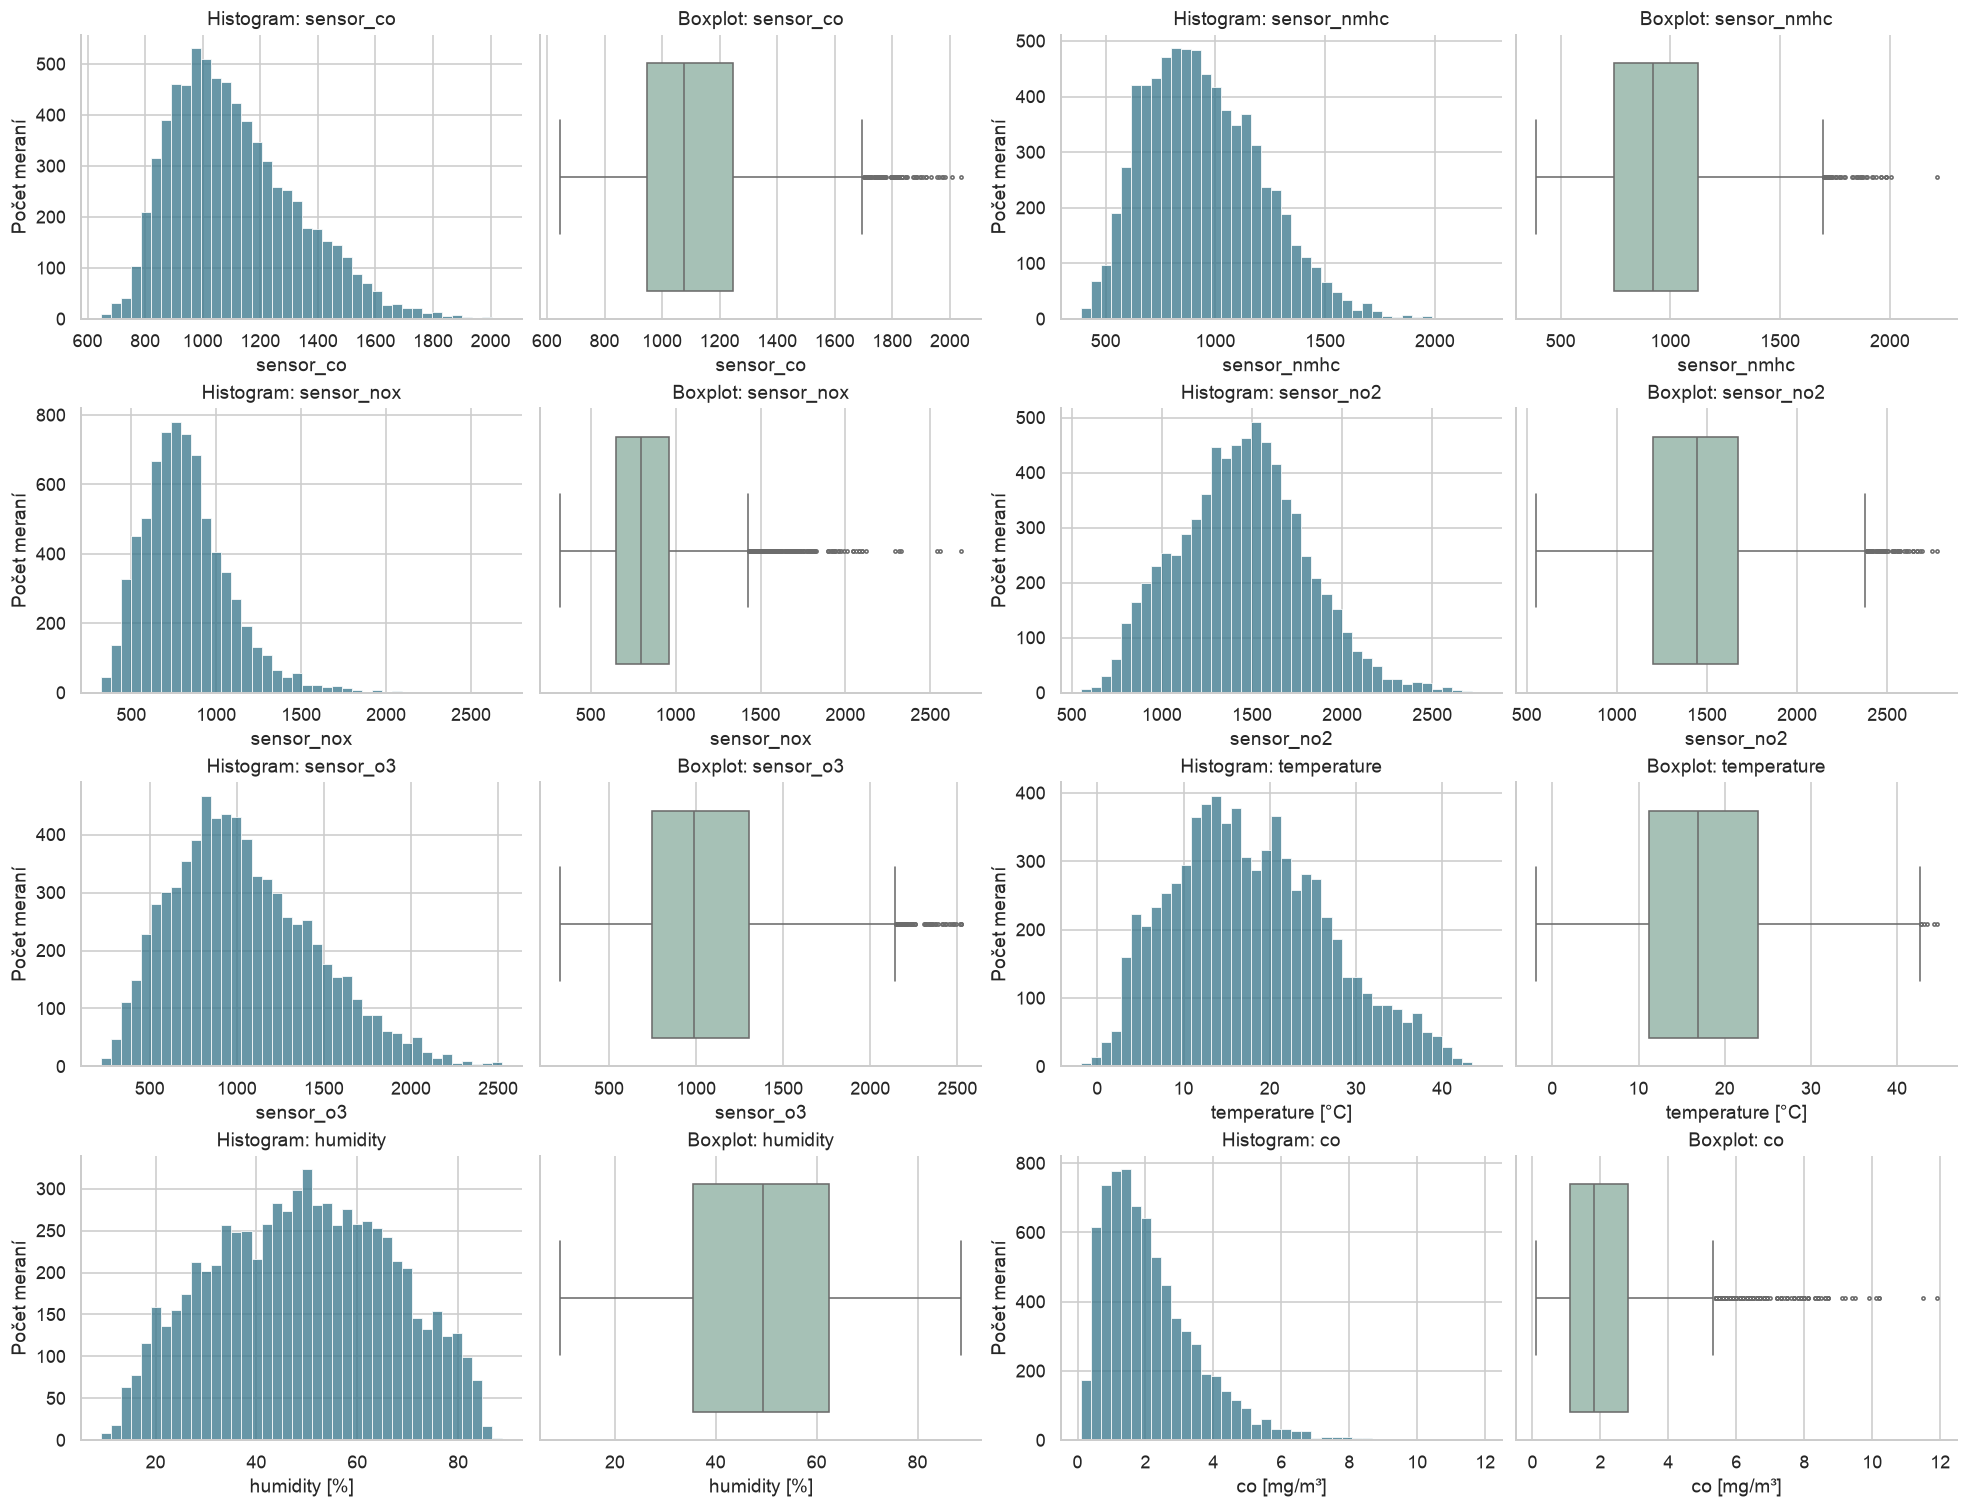

In [92]:
fig, axes = plt.subplots(4, 4, figsize=(17, 13), constrained_layout=True)
for row, column in enumerate(CONTINUOUS + [TARGET]):
    ax_hist, ax_box = axes.reshape(8, 2)[row]
    sns.histplot(data_clean[column], bins=40, ax=ax_hist, color="#36758a")
    sns.boxplot(x=data_clean[column], ax=ax_box, color="#a1c6b7", fliersize=2)
    unit = " [mg/m³]" if column == TARGET else " [°C]" if column == "temperature" else " [%]" if column == "humidity" else ""
    ax_hist.set(title=f"Histogram: {column}", xlabel=column + unit, ylabel="Počet meraní")
    ax_box.set(title=f"Boxplot: {column}", xlabel=column + unit)
plt.show()
co_skew = data_clean.co.skew()


CO má medián **1.80 $\mathrm{mg}/\mathrm{m}^3$**, priemer 2.13 $\mathrm{mg}/\mathrm{m}^3$ a výberovú šikmosť **1.36**. Dlhší pravý chvost znamená menej časté vysoké koncentrácie. MSE tieto veľké chyby silno penalizuje. Senzor NOx dosahuje maximum 2683. Odľahlosť v grafe sama nepreukazuje poruchu.

## Súvislosti a časový priebeh
### Korelácie a závislosť od hodiny

Pearsonova korelácia zachytáva lineárny vzťah, Spearmanova monotónne usporiadanie.

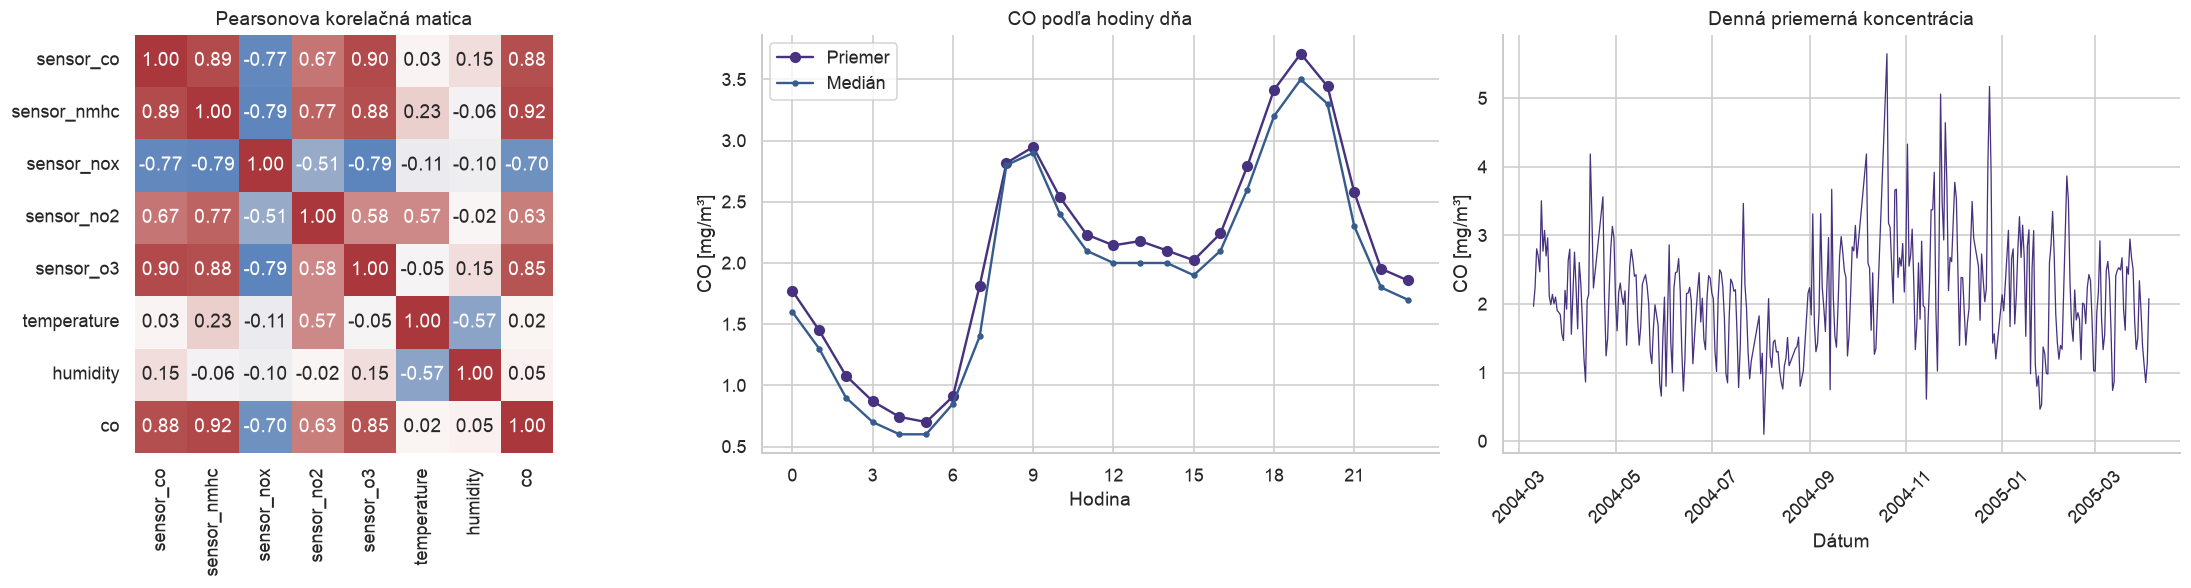

In [93]:
eda_corr = data_clean[CONTINUOUS + [TARGET]].corr()
hourly = data_clean.groupby("hour").co.agg(["mean", "median", "count"])
daily = data_clean.assign(date=pd.to_datetime(data_clean.date)).groupby("date").co.mean()
fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)
sns.heatmap(eda_corr, annot=True, fmt=".2f", center=0, cmap="vlag", square=True, cbar=False, ax=axes[0])
axes[0].set_title("Pearsonova korelačná matica")
axes[1].plot(hourly.index, hourly["mean"], marker="o", label="Priemer")
axes[1].plot(hourly.index, hourly["median"], marker=".", label="Medián")
axes[1].set(title="CO podľa hodiny dňa", xlabel="Hodina", ylabel="CO [mg/m³]", xticks=range(0,24,3))
axes[1].legend()
axes[2].plot(daily.index, daily.values, linewidth=.8)
axes[2].set(title="Denná priemerná koncentrácia", xlabel="Dátum", ylabel="CO [mg/m³]")
axes[2].tick_params(axis="x", rotation=45)
plt.show()
strongest = eda_corr.co.drop(TARGET).abs().idxmax()
spearman = data_clean[CONTINUOUS + [TARGET]].corr(method="spearman").loc[strongest, TARGET]


Najsilnejšiu absolútnu Pearsonovu koreláciu s CO má **sensor_nmhc**, $r = 0.92$, a **sensor_o3** voči **sensor_co** $r = 0.90$. Najvyšší hodinový priemer je o **19:00** (3.71 $\mathrm{mg}/\mathrm{m}^3$), najnižší o 5:00 (0.70 $\mathrm{mg}/\mathrm{m}^3$). Rozdiely sú zlučiteľné s denným cyklom emisií, ale bez údajov o doprave a počasí z grafu nemožno potvrdiť jeho príčinu. Denný priebeh ukazuje aj časovú závislosť, ktorú obyčajné náhodné rozdelenie úplne neodstraňuje.

## Hodinový priebeh CO v pracovných dňoch a cez víkend

Porovnám denný profil oboch skupín a zobrazím priemerné CO pre kombinácie hodiny a dňa týždňa. V dátach znamená `weekday=0` nedeľu a `weekday=6` sobotu. Rozdiely opisujú súvislosť s kalendárom, nie preukázaný vplyv dopravy.

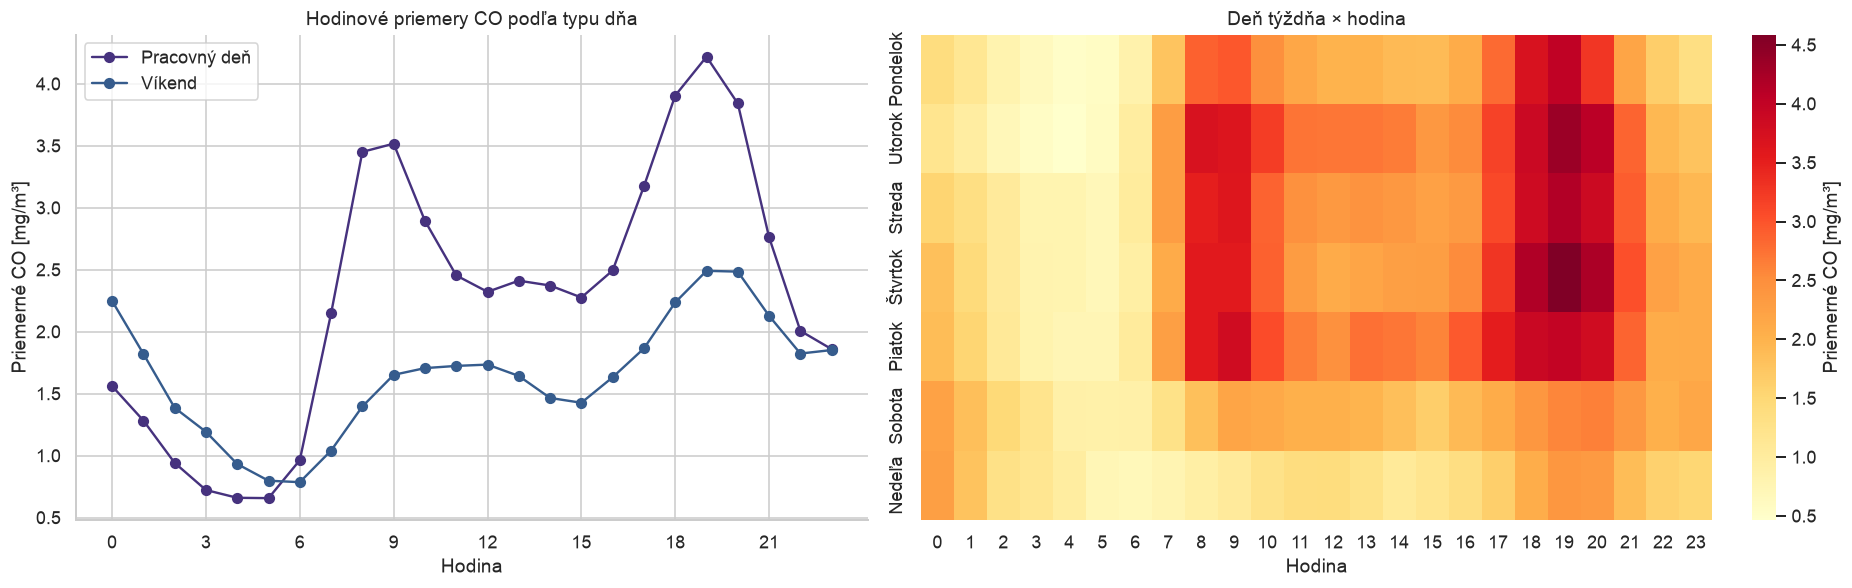

mean  median  count
typ_dna      hour                      
Pracovný deň 0     1.561    1.45    218
             1     1.284    1.20    214
             2     0.942    0.80    212
             3     0.723    0.60    206
             4     0.660    0.60    120
             5     0.657    0.60    213
             6     0.964    0.90    214
             7     2.148    1.85    216
             8     3.451    3.50    213
             9     3.517    3.50    219
             10    2.895    2.70    220
             11    2.454    2.20    217
             12    2.322    2.10    219
             13    2.412    2.20    219
             14    2.373    2.20    218
             15    2.276    2.10    218
             16    2.494    2.30    222
             17    3.174    2.90    221
             18    3.906    3.60    223
             19    4.219    4.00    223
             20    3.842    3.50    224
             21    2.762    2.50    224
             22    2.007    1.90    222
             23    1.859    1.70    221
Víkend       0     2.249    2.20     96
             1     1.822    1.60     95
             2     1.386    1.30     95
             3     1.193    1.05     94
             4     0.933    0.80     52
             5     0.798    0.70     93
             6     0.786    0.70     94
             7     1.041    1.00     93
             8     1.397    1.20     95
             9     1.652    1.55     96
             10    1.706    1.60     95
             11    1.724    1.60     95
             12    1.735    1.50     95
             13    1.643    1.40     95
             14    1.466    1.10     93
             15    1.427    1.10     93
             16    1.633    1.40     92
             17    1.865    1.65     92
             18    2.237    1.90     93
             19    2.491    2.20     93
             20    2.485    2.20     93
             21    2.128    1.80     92
             22    1.824    1.70     92
             23    1.852    1.70     92

In [94]:
weekend_data = data_clean.assign(typ_dna=np.where(data_clean.weekday.isin([0, 6]), 'Víkend', 'Pracovný deň'))
weekend_hourly = weekend_data.groupby(['typ_dna', 'hour']).co.agg(['mean', 'median', 'count'])
weekday_hourly = data_clean.pivot_table(index='weekday', columns='hour', values=TARGET, aggfunc='mean').reindex([1, 2, 3, 4, 5, 6, 0])
weekday_hourly.index = ['Pondelok', 'Utorok', 'Streda', 'Štvrtok', 'Piatok', 'Sobota', 'Nedeľa']
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for label in ['Pracovný deň', 'Víkend']:
    profile = weekend_hourly.loc[label]
    axes[0].plot(profile.index, profile['mean'], marker='o', label=label)
axes[0].set(title='Hodinové priemery CO podľa typu dňa', xlabel='Hodina', ylabel='Priemerné CO [mg/m³]', xticks=range(0, 24, 3))
axes[0].legend()
sns.heatmap(weekday_hourly, cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Priemerné CO [mg/m³]'})
axes[1].set(title='Deň týždňa × hodina', xlabel='Hodina', ylabel='')
plt.show()
display(weekend_hourly.round(3))
day_means = weekend_data.groupby('typ_dna').co.mean()
weekday_peak = int(weekend_hourly.loc['Pracovný deň', 'mean'].idxmax())
weekend_peak = int(weekend_hourly.loc['Víkend', 'mean'].idxmax())

Pracovné dni majú priemerné CO **2.333 mg/m³**, víkend **1.658 mg/m³**. Najvyšší hodinový priemer nastáva v pracovných dňoch o **19:00**, cez víkend o **19:00**. Krivky a heatmapa umožňujú rozlíšiť denný rytmus od rozdielov medzi dňami. Priemery sú ovplyvnené aj zastúpením ročných období a počasia; samy nepotvrdzujú príčinný vplyv dopravy.

## Teplota, vlhkosť a koncentrácia CO

Scatter plot ukáže jednotlivé merania; farba predstavuje CO. Druhý graf agreguje priemerné CO do intervalov teploty a vlhkosti. Prázdne alebo málo zastúpené kombinácie nemožno interpretovať rovnako spoľahlivo ako časté podmienky.

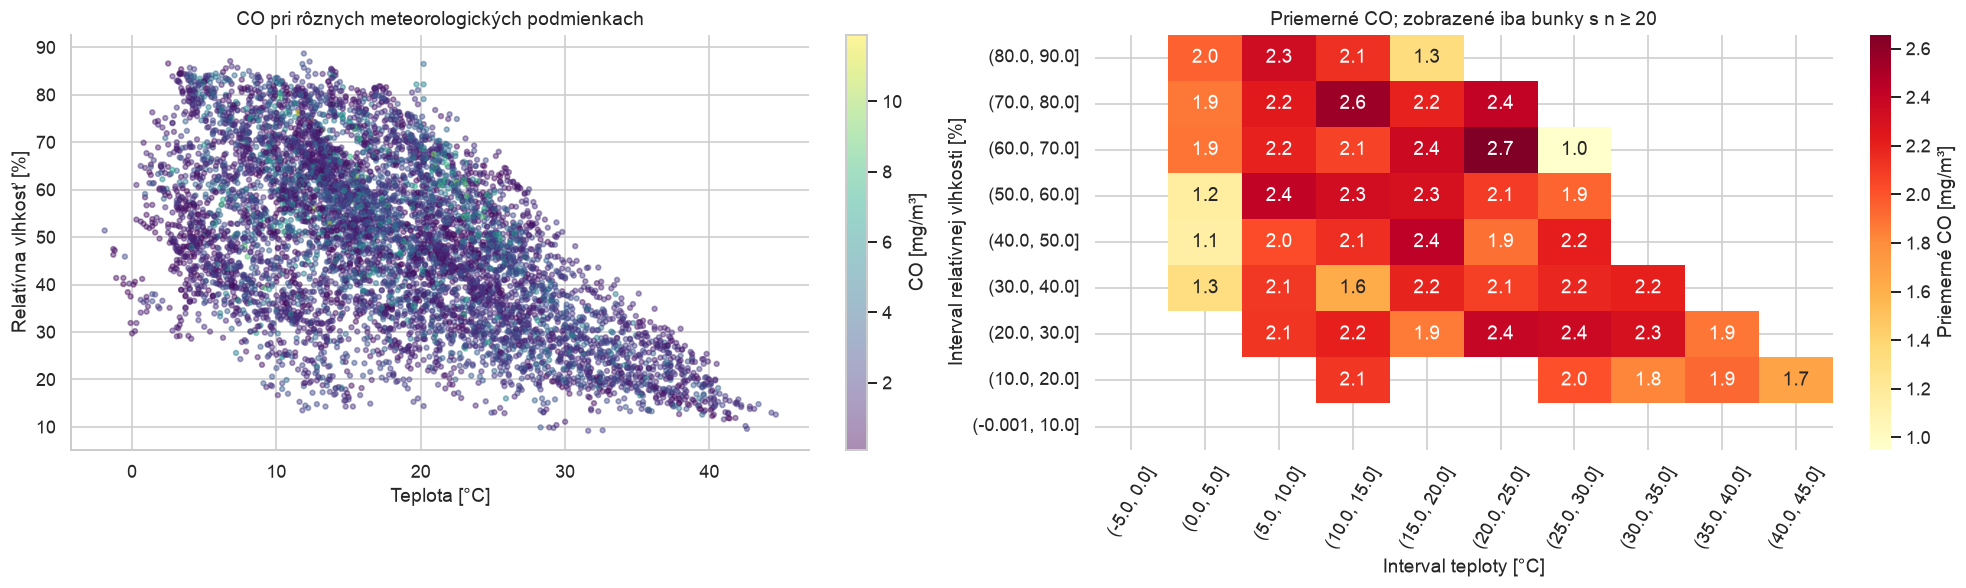

,temperature,humidity,co
temperature,1.000,-0.532,0.069
humidity,-0.532,1.000,-0.006
co,0.069,-0.006,1.000


teplota_interval,"(-5.0, 0.0]","(0.0, 5.0]","(5.0, 10.0]","(10.0, 15.0]","(15.0, 20.0]","(20.0, 25.0]","(25.0, 30.0]","(30.0, 35.0]","(35.0, 40.0]","(40.0, 45.0]"
vlhkost_interval,,,,,,,,,,
"(-0.001, 10.0]",0,0,0,0,0,0,3,2,0,1
"(10.0, 20.0]",0,0,4,40,15,14,42,76,114,45
"(20.0, 30.0]",1,4,23,83,77,117,199,208,138,1
"(30.0, 40.0]",3,53,133,178,190,269,246,110,14,0
"(40.0, 50.0]",8,104,198,175,301,369,216,16,0,0
"(50.0, 60.0]",1,116,186,351,385,276,98,0,0,0
"(60.0, 70.0]",0,92,196,435,232,198,28,0,0,0
"(70.0, 80.0]",0,53,215,242,189,27,0,0,0,0
"(80.0, 90.0]",0,55,81,75,21,2,0,0,0,0


In [95]:
temperature_bins = np.arange(-10, 56, 5)
humidity_bins = np.arange(0, 101, 10)
weather_data = data_clean.assign(
    teplota_interval=pd.cut(data_clean.temperature, temperature_bins, include_lowest=True),
    vlhkost_interval=pd.cut(data_clean.humidity, humidity_bins, include_lowest=True))
weather_means = weather_data.pivot_table(index='vlhkost_interval', columns='teplota_interval', values=TARGET, aggfunc='mean', observed=True)
weather_counts = weather_data.pivot_table(index='vlhkost_interval', columns='teplota_interval', values=TARGET, aggfunc='count', observed=True)
weather_visible = weather_means.where(weather_counts >= 20)
fig, axes = plt.subplots(1, 2, figsize=(17, 5), constrained_layout=True)
scatter = axes[0].scatter(data_clean.temperature, data_clean.humidity, c=data_clean.co, cmap='viridis', s=9, alpha=.45)
fig.colorbar(scatter, ax=axes[0], label='CO [mg/m³]')
axes[0].set(title='CO pri rôznych meteorologických podmienkach', xlabel='Teplota [°C]', ylabel='Relatívna vlhkosť [%]')
sns.heatmap(weather_visible.sort_index(ascending=False), annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Priemerné CO [mg/m³]'})
axes[1].set(title='Priemerné CO; zobrazené iba bunky s n ≥ 20', xlabel='Interval teploty [°C]', ylabel='Interval relatívnej vlhkosti [%]')
axes[1].tick_params(axis='x', rotation=60)
plt.show()
display(data_clean[['temperature', 'humidity', TARGET]].corr(method='spearman').round(3))
display(weather_counts.fillna(0).astype(int))
weather_spearman = data_clean[['temperature', 'humidity', TARGET]].corr(method='spearman')[TARGET]
weather_extremes = weather_visible.stack().dropna().sort_values()

Spearmanova korelácia CO s teplotou je **0.069**, s vlhkosťou **-0.006**. Zo zobrazených buniek s aspoň 20 meraniami má najvyššie priemerné CO kombinácia teploty **(20.0, 25.0] °C** a vlhkosti **(60.0, 70.0] %** (**2.658 mg/m³**); najnižší priemer je **0.950 mg/m³**. Agregovaný graf ukazuje spoločný vzťah dvoch premenných, ale nenahrádza kontrolu sezónnosti ani dôkaz príčiny. Biele bunky nemajú dosť meraní na zobrazenie.

# Rozdelenie dát
## Rozdelenie vstupov a výstupu

Použijem jedno rozdelenie **80 % tréning / 20 % test**. Tréning zahŕňa aj vnútorné CV foldy, preto samostatnú vonkajšiu validačnú množinu nepotrebujem. Seed 2026 je stanovený pred týmto experimentom. `instant` a `date` sa do modelov nedostanú. Rovnaké testovacie riadky zachovám aj pri redukcii príznakov a zhlukovaní.

In [96]:
train_data, test_data = train_test_split(data_clean, test_size=0.20, random_state=SEED)
FEATURES = [c for c in data_clean if c not in ["instant", "date", TARGET]]
X_train = train_data[FEATURES].copy()
X_test = test_data[FEATURES].copy()
y_train = train_data[TARGET].copy()
y_test = test_data[TARGET].copy()
assert set(train_data.instant).isdisjoint(set(test_data.instant))
assert TARGET not in X_train and "instant" not in X_train and "date" not in X_train
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
display(pd.DataFrame({"Počet": [len(y_train),len(y_test)],
                      "Priemer CO": [y_train.mean(),y_test.mean()],
                      "SD CO": [y_train.std(),y_test.std()]}, index=["Tréning", "Test"]).round(4))


,Počet,Priemer CO,SD CO
Tréning,5875,2.1212,1.4356
Test,1469,2.1636,1.4398


Tréning obsahuje **5875** a test **1469** meraní. Rozdelenie je náhodné bez stratifikácie regresného cieľa. Porovnanie priemerov je opisné. Nerozhodujem podľa neho o zmene seedu ani pomeru. Testovacie outliery ponechávam, aby sa náročné merania nestratili zo záverečného hodnotenia.

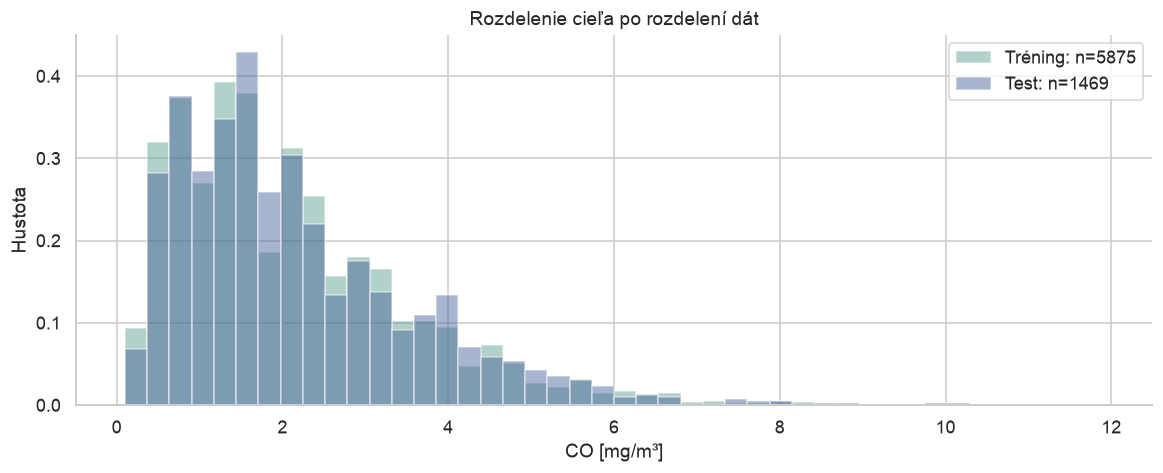

In [97]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
co_bins = np.linspace(data_clean.co.min(), data_clean.co.max(), 45)
for values, label, color in [(y_train, 'Tréning', '#539b8a'), (y_test, 'Test', '#3f5c96')]:
    ax.hist(values, bins=co_bins, density=True, alpha=.45, label=f'{label}: n={len(values)}', color=color)
ax.set(title='Rozdelenie cieľa po rozdelení dát', xlabel='CO [mg/m³]', ylabel='Hustota')
ax.legend()
plt.show()

Rovnaké intervaly a hustoty umožňujú porovnať tvar rozdelenia napriek odlišným počtom meraní. Graf je kontrola už vytvoreného rozdelenia; podľa jeho vzhľadu nemením seed. Testovacie extrémy zostávajú zachované.

## Kódovanie a normalizácia
### Cyklické kalendárne premenné

Mesiac, hodinu a deň v týždni prevediem na sínus a kosínus. Susedné hodnoty 23 a 0 hodín tak zostanú blízko aj v kódovaní. Sezóna má iba štyri kategórie, preto použijem one-hot kódovanie. Dátum nepridáva stovky stĺpcov. Po kódovaní štandardizujem **všetky vstupy**, vrátane one-hot stĺpcov, aby PCA a vzdialenostné modely neovládla pôvodná mierka senzorov. Cieľ `co` nemením.

$$
\begin{aligned}
\mathrm{sin}_t &= \sin\left(\frac{2\pi t}{T}\right), \quad \mathrm{cos}_t = \cos\left(\frac{2\pi t}{T}\right) \\
z &= \frac{x - \mu_{\text{tréning}}}{\sigma_{\text{tréning}}}
\end{aligned}
$$

### Odstránenie odľahlých tréningových záznamov

Pre sedem spojitých vstupov použijem hranice $[Q_1 - 3 \times \mathrm{IQR}, Q_3 + 3 \times \mathrm{IQR}]$, kde $\mathrm{IQR} = Q_3 - Q_1$. Záznam odstránim, ak mimo nich leží aspoň jeden vstup. Kvartily sa učia pri každom `fit` iba z príslušného tréningového foldu. CO ani diskrétne časové stĺpce nefiltrované podľa IQR. Pri `predict` sa neodstraňuje žiadny riadok.

In [98]:
class CalendarEncoder(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        out = X.copy()
        for column, period in [("month", 12), ("hour", 24), ("weekday", 7)]:
            out[column + "_sin"] = np.sin(2 * np.pi * out[column] / period)
            out[column + "_cos"] = np.cos(2 * np.pi * out[column] / period)
            out = out.drop(columns=column)
        return out

CYCLIC = [f"{c}_{suffix}" for c in ["month", "hour", "weekday"] for suffix in ["sin", "cos"]]
NUMERIC = CONTINUOUS + CYCLIC
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC),
    ("season", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["season"]),
], verbose_feature_names_out=False)

class OutlierFilteredRegressor(RegressorMixin, BaseEstimator):
    """Odstráni iba tréningové outliery; pri predikcii zachová všetky riadky."""
    def __init__(self, estimator, factor=3.0):
        self.estimator = estimator
        self.factor = factor

    def fit(self, X, y):
        q1 = X[CONTINUOUS].quantile(.25)
        q3 = X[CONTINUOUS].quantile(.75)
        iqr = q3 - q1
        self.bounds_ = pd.DataFrame({"Dolná hranica": q1-self.factor*iqr, "Horná hranica": q3+self.factor*iqr})
        keep = X[CONTINUOUS].ge(self.bounds_["Dolná hranica"]).all(axis=1) & X[CONTINUOUS].le(self.bounds_["Horná hranica"]).all(axis=1)
        self.inlier_mask_ = keep.to_numpy()
        self.n_removed_ = int((~keep).sum())
        self.removed_index_ = X.index[~keep]
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X.loc[keep], np.asarray(y)[self.inlier_mask_])
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

def make_pipeline(model, selector=None):
    return OutlierFilteredRegressor(Pipeline([
        ("calendar", CalendarEncoder()),
        ("preprocessing", clone(preprocessor)),
        ("scale", StandardScaler()),
        ("selection", "passthrough" if selector is None else selector),
        ("model", clone(model)),
    ]))

# Ukážka rovnakých IQR hraníc bez trénovania pomocného regresného modelu.
q1, q3 = X_train[CONTINUOUS].quantile(.25), X_train[CONTINUOUS].quantile(.75)
training_bounds = pd.DataFrame({"Dolná hranica": q1-3*(q3-q1), "Horná hranica": q3+3*(q3-q1)})
inliers = (X_train[CONTINUOUS].ge(training_bounds["Dolná hranica"]).all(axis=1)
           & X_train[CONTINUOUS].le(training_bounds["Horná hranica"]).all(axis=1)).to_numpy()
X_train_in = X_train.iloc[np.flatnonzero(inliers)]
y_train_in = y_train.iloc[np.flatnonzero(inliers)]
display(training_bounds.round(3))
encoding_demo = clone(preprocessor).fit(CalendarEncoder().fit_transform(X_train_in))
encoded_names = encoding_demo.get_feature_names_out()

,Dolná hranica,Horná hranica
sensor_co,43.0,2143.0
sensor_nmhc,-400.0,2267.0
sensor_nox,-288.0,1903.0
sensor_no2,-204.5,3082.0
sensor_o3,-944.0,2983.0
temperature,-26.2,61.3
humidity,-44.3,141.9


Na trénovacích dátach toto pravidlo odstraňuje **23 riadkov**, model sa učí na **5852 meraniach**. Test zostáva so všetkými 1469 riadkami. 

Kódovaním vzniká **17 vstupov**, 10 nových stĺpcov, ktoré nahradili 4 pôvodné.
- month (cyclic): `month_sin`, `month_cos`
- hour (cyclic): `hour_sin`, `hour_cos`
- weekday (cyclic): `weekday_sin`, `weekday_cos`
- season (one-hot): `season_autumn`, `season_spring`, `season_summer`, `season_winter`

# Trénovanie ML modelov
### Kritériá hodnotenia a porovnateľnosť

Reziduál definujem ako skutočná mínus predpovedaná. Kladný reziduál znamená podhodnotenie, záporný nadhodnotenie.

$$
\begin{aligned}
e_i &= y_i - \hat{y}_i \\
\mathrm{MSE} &= \frac{1}{n}\sum_i e_i^2 \\
\mathrm{RMSE} &= \sqrt{\mathrm{MSE}} \\
R^2 &= 1 - \frac{\sum_i e_i^2}{\sum_i (y_i - \bar{y})^2}
\end{aligned}
$$

MSE má jednotku $(\mathrm{mg}/\mathrm{m}^3)^2$, RMSE a MAE $\mathrm{mg}/\mathrm{m}^3$, $R^2$ je bezrozmerné a môže byť záporné. Neuvádzam ho v percentách. Model vyberiem podľa najnižšej priemernej **CV MSE**. CV smerodajná odchýlka je variabilita medzi foldmi, nie interval spoľahlivosti.

### GridSearchCV a parametre modelov

Pri strome ladím hĺbku a minimálny počet vzoriek v liste. Random Forest priemeruje bootstrapové stromy, ExtraTrees (Extremely Randomized Trees) navyše náhodne volí prahy. XGBoost a histogramový boosting pridávajú stromy postupne na opravu predchádzajúcich chýb. Pri SVR volím regresnú verziu SVM s RBF jadrom, penalizáciou C, šírkou jadra gamma a toleranciou epsilon. Uvádzam ladené aj dôležité pevné parametre. Žiadny ďalší model nemusí predchádzajúce prekonať. Rozhodnú namerané výsledky.

### Tréning, validácia a finálny test

Pri 3-fold CV sa každá konfigurácia trénuje trikrát na dvoch foldoch a hodnotí na zostávajúcom. `mean_train_r2` a `mean_test_r2` sú priemery tréningových a **validačných** skóre týchto fitov. Slovo `test` v `cv_results_` neoznačuje vonkajší test. Odchýlka medzi foldmi nie je interval spoľahlivosti.

Po výbere podľa CV MSE sa víťazná konfigurácia znovu natrénuje na celom tréningu. Jej tréningové a vonkajšie testovacie metriky sú preto ďalšie dve samostatné hodnotenia. `CV RMSE` v súhrne je odmocnina priemernej foldovej MSE. Test ani jeho feature importance sa nepoužijú na ladenie či výber príznakov.

In [99]:
model_configs = {
    "DecisionTree": (DecisionTreeRegressor(random_state=SEED), {
        "max_depth": [4, 8, 12, None], "min_samples_leaf": [2, 8, 20]}),
    "RandomForest": (RandomForestRegressor(n_estimators=200, n_jobs=1, random_state=SEED), {
        "max_depth": [12, None], "max_features": [.7, 1.0], "min_samples_leaf": [1, 3]}),
    "XGBoost": (XGBRegressor(objective="reg:squarederror", tree_method="hist", n_jobs=1,
                            subsample=.85, colsample_bytree=.9, random_state=SEED), {
        "n_estimators": [200, 400], "max_depth": [3, 5], "learning_rate": [.05, .1], "reg_lambda": [1., 5.]}),
    "SVR": (SVR(kernel="rbf", cache_size=400), {
        "C": [10., 100.], "gamma": ["scale", .01, .1], "epsilon": [.05, .1]}),
    "ExtraTrees": (ExtraTreesRegressor(n_estimators=200, n_jobs=1, random_state=SEED), {
        "max_features": [.7, 1.0], "min_samples_leaf": [1, 3]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=SEED), {
        "learning_rate": [.05, .1], "max_leaf_nodes": [15, 31], "l2_regularization": [0., 1.]}),
}

for name, (model, grid) in model_configs.items():
    print(f"{name}: {len(ParameterGrid(grid))} konfigurácií, {CV_FOLDS*len(ParameterGrid(grid))} CV tréningov")
    print("  Mriežka:", grid)
    fixed = {k: model.get_params()[k] for k in ["n_estimators", "kernel", "max_iter", "subsample", "colsample_bytree", "random_state"] if k in model.get_params()}
    print("  Dôležité pevné parametre:", fixed)

SCORING = {"mse": "neg_mean_squared_error", "r2": "r2"}
searches, trained_models, cv_rows = {}, {}, []
for name, (model, grid) in model_configs.items():
    start = time.perf_counter()
    search = GridSearchCV(make_pipeline(model),
        {"estimator__model__"+key: value for key, value in grid.items()},
        scoring=SCORING, refit="mse", cv=cv, n_jobs=N_JOBS,
        return_train_score=True, error_score="raise")
    with parallel_backend("threading"), threadpool_limits(limits=1):
        search.fit(X_train, y_train)
    searches[name] = search
    trained_models[name] = search.best_estimator_
    index = search.best_index_
    cv_rows.append({"Model": name,
                    "CV MSE": -search.best_score_,
                    "CV RMSE": np.sqrt(-search.best_score_),
                    "CV tréning R²": search.cv_results_["mean_train_r2"][index],
                    "CV tréning SD R²": search.cv_results_["std_train_r2"][index],
                    "CV R²": search.cv_results_["mean_test_r2"][index],
                    "CV SD R²": search.cv_results_["std_test_r2"][index],
                    "CV SD MSE": search.cv_results_["std_test_mse"][index],
                    "Čas [s]": time.perf_counter()-start})
    print(name, "hotovo; CV RMSE =", round(np.sqrt(-search.best_score_),4), flush=True)
cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV MSE")
BEST_NAME = cv_results.index[0]
best_model = trained_models[BEST_NAME]
best_base_estimator = clone(best_model.estimator_.named_steps["model"])
display(cv_results.round(4))

DecisionTree: 12 konfigurácií, 36 CV tréningov
  Mriežka: {'max_depth': [4, 8, 12, None], 'min_samples_leaf': [2, 8, 20]}
  Dôležité pevné parametre: {'random_state': 2026}
RandomForest: 8 konfigurácií, 24 CV tréningov
  Mriežka: {'max_depth': [12, None], 'max_features': [0.7, 1.0], 'min_samples_leaf': [1, 3]}
  Dôležité pevné parametre: {'n_estimators': 200, 'random_state': 2026}
XGBoost: 16 konfigurácií, 48 CV tréningov
  Mriežka: {'n_estimators': [200, 400], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'reg_lambda': [1.0, 5.0]}
  Dôležité pevné parametre: {'n_estimators': None, 'subsample': 0.85, 'colsample_bytree': 0.9, 'random_state': 2026}
SVR: 12 konfigurácií, 36 CV tréningov
  Mriežka: {'C': [10.0, 100.0], 'gamma': ['scale', 0.01, 0.1], 'epsilon': [0.05, 0.1]}
  Dôležité pevné parametre: {'kernel': 'rbf', 'max_iter': -1}
ExtraTrees: 4 konfigurácií, 12 CV tréningov
  Mriežka: {'max_features': [0.7, 1.0], 'min_samples_leaf': [1, 3]}
  Dôležité pevné parametre: {'n_estimator

,CV MSE,CV RMSE,CV tréning R²,CV tréning SD R²,CV R²,CV SD R²,CV SD MSE,Čas [s]
Model,,,,,,,,
SVR,0.1046,0.3234,0.9843,0.0006,0.9492,0.0028,0.0063,63.9066
HistGradientBoosting,0.1256,0.3544,0.9805,0.0010,0.9388,0.0046,0.0070,16.0998
XGBoost,0.1284,0.3583,0.9846,0.0009,0.9376,0.0040,0.0076,3.8503
ExtraTrees,0.1297,0.3602,1.0000,0.0000,0.9370,0.0034,0.0095,10.2897
RandomForest,0.1499,0.3872,0.9898,0.0004,0.9272,0.0022,0.0088,27.8976
DecisionTree,0.2346,0.4843,0.9364,0.0016,0.8860,0.0012,0.0099,0.7285


Pred otvorením testovacích výsledkov vyberám **SVR** podľa CV MSE 0.1046. Jeho CV RMSE je 0.3234 $\mathrm{mg}/\mathrm{m}^3$. Tento model a jeho hyperparametre ďalej nemením podľa testovacieho poradia.

In [100]:
def regression_metrics(y, prediction):
    return {"MSE": float(mean_squared_error(y, prediction)),
            "RMSE": float(np.sqrt(mean_squared_error(y, prediction))),
            "MAE": float(mean_absolute_error(y, prediction)),
            "R²": float(r2_score(y, prediction))}

def evaluate_model(name, model):
    return [{"Model": name, "Množina": label, **regression_metrics(y, model.predict(X))}
            for label, X, y in [("Tréning", X_train, y_train), ("Test", X_test, y_test)]]

metric_rows = []

In [101]:
def show_cv_diagnostics(name):
    search = searches[name]
    result, index = search.cv_results_, search.best_index_
    rows = []
    for fold in range(CV_FOLDS):
        row = {'Fold': fold+1}
        for split, label in [('train', 'Tréning'), ('test', 'Validácia')]:
            row[f'{label} R²'] = result[f'split{fold}_{split}_r2'][index]
            row[f'{label} MSE'] = -result[f'split{fold}_{split}_mse'][index]
            row[f'{label} RMSE'] = np.sqrt(row[f'{label} MSE'])
        rows.append(row)
    table = pd.DataFrame(rows).set_index('Fold')
    display(table.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
    positions = np.arange(CV_FOLDS)
    for offset, label, color in [(-.18, 'Tréning', '#539b8a'), (.18, 'Validácia', '#3f5c96')]:
        axes[0].bar(positions+offset, table[f'{label} R²'], width=.36, label=label, color=color)
        axes[1].bar(positions+offset, table[f'{label} RMSE'], width=.36, label=label, color=color)
    axes[0].set(title=f'{name}: R² vo foldoch', ylabel='R²')
    axes[1].set(title=f'{name}: RMSE vo foldoch', ylabel='RMSE [mg/m³]')
    for ax in axes:
        ax.set_xticks(positions, [f'Fold {i+1}' for i in positions])
        ax.legend()
    plt.show()
    return table


native_importance_tables, permutation_tables, top_importance_tables = {}, {}, {}


def get_native_importance_table(name):
    if name not in native_importance_tables:
        pipeline = trained_models[name].estimator_
        estimator = pipeline.named_steps['model']
        names = pipeline.named_steps['preprocessing'].get_feature_names_out()
        native_importance_tables[name] = pd.DataFrame({
            'Príznak': names, 'Dôležitosť': estimator.feature_importances_
        }).sort_values('Dôležitosť', ascending=False).set_index('Príznak')
    return native_importance_tables[name]


def get_permutation_importance_table(name):
    if name not in permutation_tables:
        with threadpool_limits(limits=1):
            result = permutation_importance(trained_models[name], X_test, y_test,
                scoring='r2', n_repeats=5, random_state=SEED, n_jobs=1)
        permutation_tables[name] = pd.DataFrame({
            'Pokles R²': result.importances_mean, 'SD': result.importances_std
        }, index=X_test.columns).sort_values('Pokles R²', ascending=False)
    return permutation_tables[name]


def show_top_feature_importance(name, top_n=10):
    estimator = trained_models[name].estimator_.named_steps['model']
    if hasattr(estimator, 'feature_importances_'):
        table = get_native_importance_table(name).rename(columns={'Dôležitosť': 'Feature importance'})
        method = 'normalizovaný gain' if name == 'XGBoost' else 'MDI – podiel zníženia MSE'
    else:
        table = get_permutation_importance_table(name).rename(columns={'Pokles R²': 'Feature importance'})
        method = 'testová permutácia – pokles R²; SD z piatich opakovaní'
    top = table.head(top_n).rename_axis('Príznak').reset_index()
    top.index = pd.RangeIndex(1, len(top)+1, name='Poradie')
    print(f'{name}: najdôležitejšie príznaky ({method})')
    display(top.round(5))
    return top


def show_native_importance(name):
    measure = 'Normalizovaný gain' if name == 'XGBoost' else 'MDI: podiel zníženia MSE'
    table = get_native_importance_table(name)
    fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
    table.head(12).sort_values('Dôležitosť').plot.barh(ax=ax, legend=False, color='#538f83')
    ax.set(title=f'{name}: najdôležitejšie kódované vstupy', xlabel=measure, ylabel='')
    plt.show()
    return table


def show_permutation_importance(name):
    table = get_permutation_importance_table(name)
    shown = table.head(12).sort_values('Pokles R²')
    fig, ax = plt.subplots(figsize=(9, 4.8), constrained_layout=True)
    ax.barh(shown.index, shown['Pokles R²'], xerr=shown.SD, color='#3e718f', capsize=3)
    ax.axvline(0, color='black', linewidth=.8)
    ax.set(title=f'{name}: permutačná dôležitosť na teste', xlabel='Pokles R² po premiešaní pôvodného stĺpca')
    plt.show()
    return table

### Ako čítať dôležitosť príznakov

Natívna dôležitosť stromov opisuje využitie **kódovaných** vstupov pri delení, pri XGBoost ide o normalizovaný gain. Permutácia meria pokles testovacieho R² po premiešaní **pôvodného** stĺpca cez celú pipeline; pri hodine sa preto spolu zmení sínus aj kosínus. Zobrazuje päť opakovaní a ich SD. Natívne hodnoty rôznych algoritmov nemajú rovnakú interpretáciu.

Vysoká dôležitosť nedokazuje príčinný vplyv a nehovorí o smere závislosti. Korelované senzory sa môžu nahrádzať. Permutačná dôležitosť môže byť záporná alebo vyššia než 1 a nie je normalizovaná na súčet 1. Testová permutácia slúži iba na záverečnú interpretáciu; výber podmnožín ďalej prebieha výhradne v tréningovej CV. [Dokumentácia](https://scikit-learn.org/stable/modules/permutation_importance.html).

Pri výsledkoch každého modelu uvádzam zoradenú tabuľku najviac **10 najdôležitejších príznakov** s poradím. DecisionTree, RandomForest, ExtraTrees a XGBoost používajú natívnu dôležitosť kódovaných vstupov; HistGradientBoosting a SVR používajú permutáciu pôvodných stĺpcov. Stĺpec `Feature importance` má preto jednotku a význam metódy uvedenej nad tabuľkou. Permutačnú tabuľku vypočítam raz a rovnaké hodnoty použijem aj v grafe.

## DecisionTree

In [102]:
name = 'DecisionTree'
search = searches[name]
params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
print("Najlepšie parametre:", params)
details = pd.DataFrame(search.cv_results_)
worst_i = details.mean_test_mse.idxmin()
print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_train_r2", "std_train_r2", "mean_test_r2", "std_test_r2", "rank_test_mse"]].copy()
table["mean_train_mse"] *= -1
table["mean_test_mse"] *= -1
display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
model = trained_models[name]
rows = evaluate_model(name, model)
metric_rows.extend(rows)
display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
train_m, test_m = rows

top_importance_tables[name] = show_top_feature_importance(name)


Najlepšie parametre: {'max_depth': 8, 'min_samples_leaf': 8}
Najhoršie CV parametre: {'estimator__model__max_depth': None, 'estimator__model__min_samples_leaf': 2}
Najhoršia CV MSE: 0.292


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,rank_test_mse
0,"{'estimator__model__max_depth': 8, 'estimator__model__min_samples_leaf': 8}",0.1310,0.2346,0.0099,0.9364,0.0016,0.8860,0.0012,1
1,"{'estimator__model__max_depth': 8, 'estimator__model__min_samples_leaf': 20}",0.1592,0.2352,0.0133,0.9227,0.0016,0.8857,0.0051,2
2,"{'estimator__model__max_depth': 12, 'estimator__model__min_samples_leaf': 20}",0.1538,0.2353,0.0139,0.9253,0.0016,0.8857,0.0050,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.1404,0.3747,0.2509,0.9319
Test,0.2007,0.4480,0.3004,0.9031


DecisionTree: najdôležitejšie príznaky (MDI – podiel zníženia MSE)


,Príznak,Feature importance
Poradie,,
1,sensor_nmhc,0.93027
2,temperature,0.02870
3,sensor_co,0.01004
4,sensor_nox,0.00710
5,hour_sin,0.00547
6,hour_cos,0.00507
7,sensor_o3,0.00402
8,humidity,0.00213
9,month_sin,0.00191


**DecisionTree** má tréningové $R^2$ **0.9319** a testovacie $R^2$ **0.9031**. Testovacia RMSE je **0.4480 $\mathrm{mg}/\mathrm{m}^3$**, MAE 0.3004 $\mathrm{mg}/\mathrm{m}^3$. Rozdiel tréningového a testovacieho $R^2$ je 0.0288. Rozdiel je menší než pri výrazne preučených ensemble modeloch.

,Tréning R²,Tréning MSE,Tréning RMSE,Validácia R²,Validácia MSE,Validácia RMSE
Fold,,,,,,
1,0.9357,0.1283,0.3581,0.8878,0.2456,0.4956
2,0.9385,0.1306,0.3614,0.8851,0.2216,0.4707
3,0.9349,0.1342,0.3663,0.8852,0.2364,0.4863


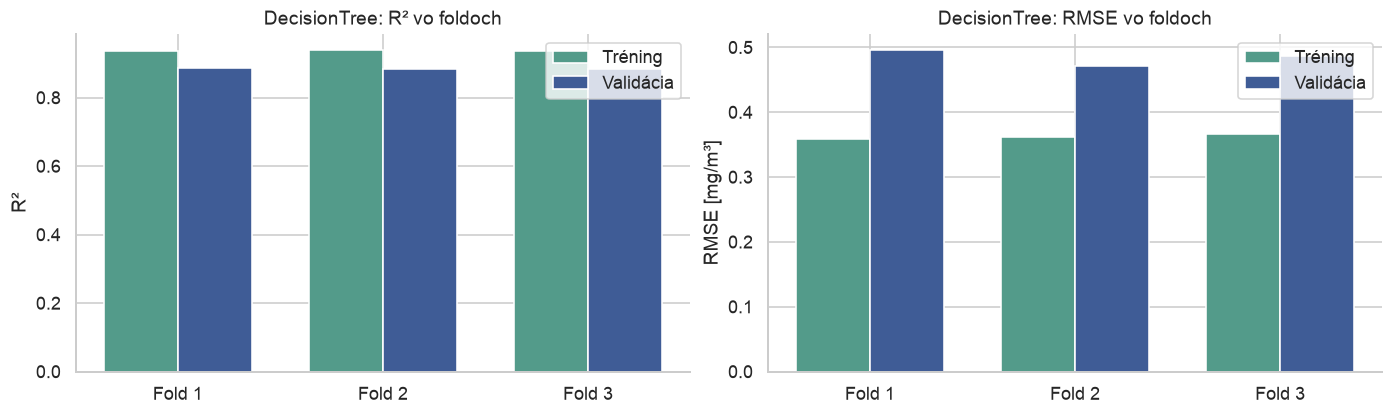

In [103]:
cv_folds_DecisionTree = show_cv_diagnostics("DecisionTree")

**DecisionTree:** CV tréningové R² je **0.9364 ± 0.0016**, CV validačné R² **0.8860 ± 0.0012**. Rozdiel priemerov je **0.0504**. Hodnoty pochádzajú z troch samostatných foldových fitov. Finálne tréningové a testovacie výsledky vyššie patria refitu na celom tréningu, preto sa s týmito priemermi nemusia rovnať.

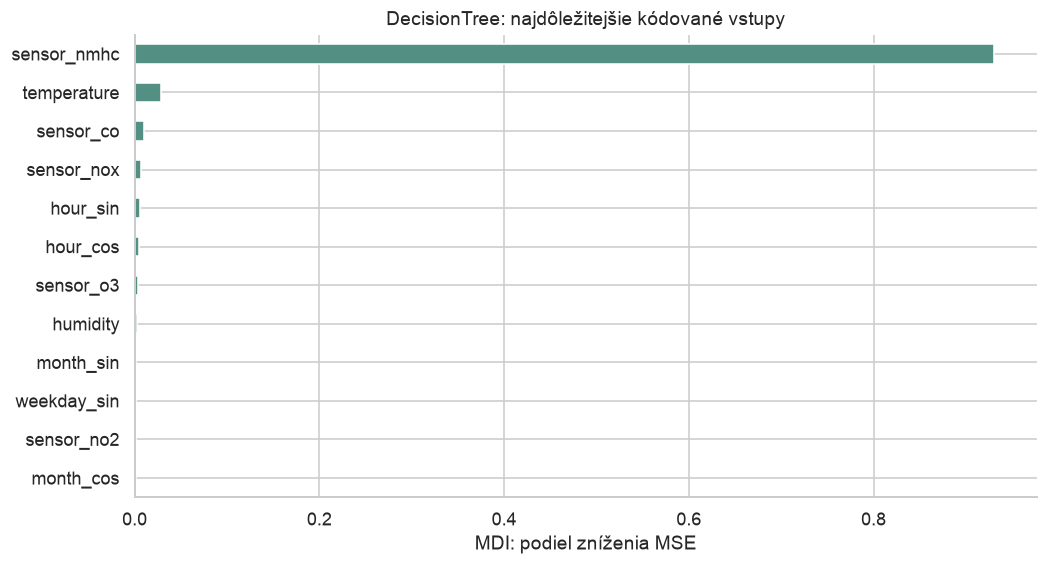

In [104]:
native_DecisionTree = show_native_importance("DecisionTree")

Najvyššiu natívnu dôležitosť modelu **DecisionTree** má **sensor_nmhc**, MDI **0.93027**. Prvé tri vstupy spolu získali **96.90%** relatívnej dôležitosti. Ide o využitie vstupov konkrétnym natrénovaným modelom, nie o podiel vysvetleného CO alebo príčinný vplyv. Tabuľka pri výsledkoch tréningu zobrazuje najviac 10 najdôležitejších kódovaných vstupov; graf zobrazuje prvých 12.

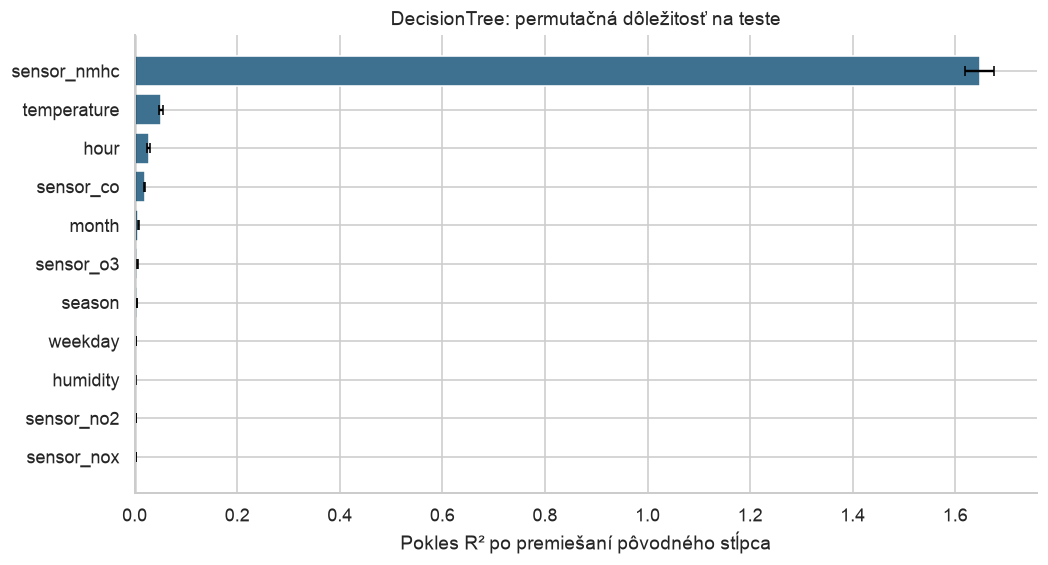

In [105]:
permutation_DecisionTree = show_permutation_importance("DecisionTree")

Po premiešaní **sensor_nmhc** klesne testovacie R² modelu **DecisionTree** v priemere o **1.6473 ± 0.0281**. Táto hodnota je rozdiel R², nie percento. Chybové úsečky opisujú päť náhodných premiešaní pri nezmenenom modeli. Korelované vstupy môžu časť informácie navzájom nahrádzať; testový rebríček nepoužívam na výber príznakov.

### Vizualizácia malého rozhodovacieho stromu

Pre čitateľnosť natrénujem samostatný ilustračný strom s hĺbkou 3 a minimálne 30 meraniami v liste. Použijem sedem pôvodných spojitých vstupov bez škálovania, aby prahy mali zrozumiteľné jednotky. Jeho parametre a výsledok sú odlíšené od ladeného stromu. V liste `value` znamená priemerné CO a `squared_error` priemernú štvorcovú odchýlku cieľa v danom uzle.

Ilustračný strom: dôležitosť pôvodných vstupov (MDI)


,Príznak,Feature importance
Poradie,,
1,sensor_nmhc,1.0
2,sensor_co,0.0
3,sensor_nox,0.0
4,sensor_no2,0.0
5,sensor_o3,0.0
6,temperature,0.0
7,humidity,0.0


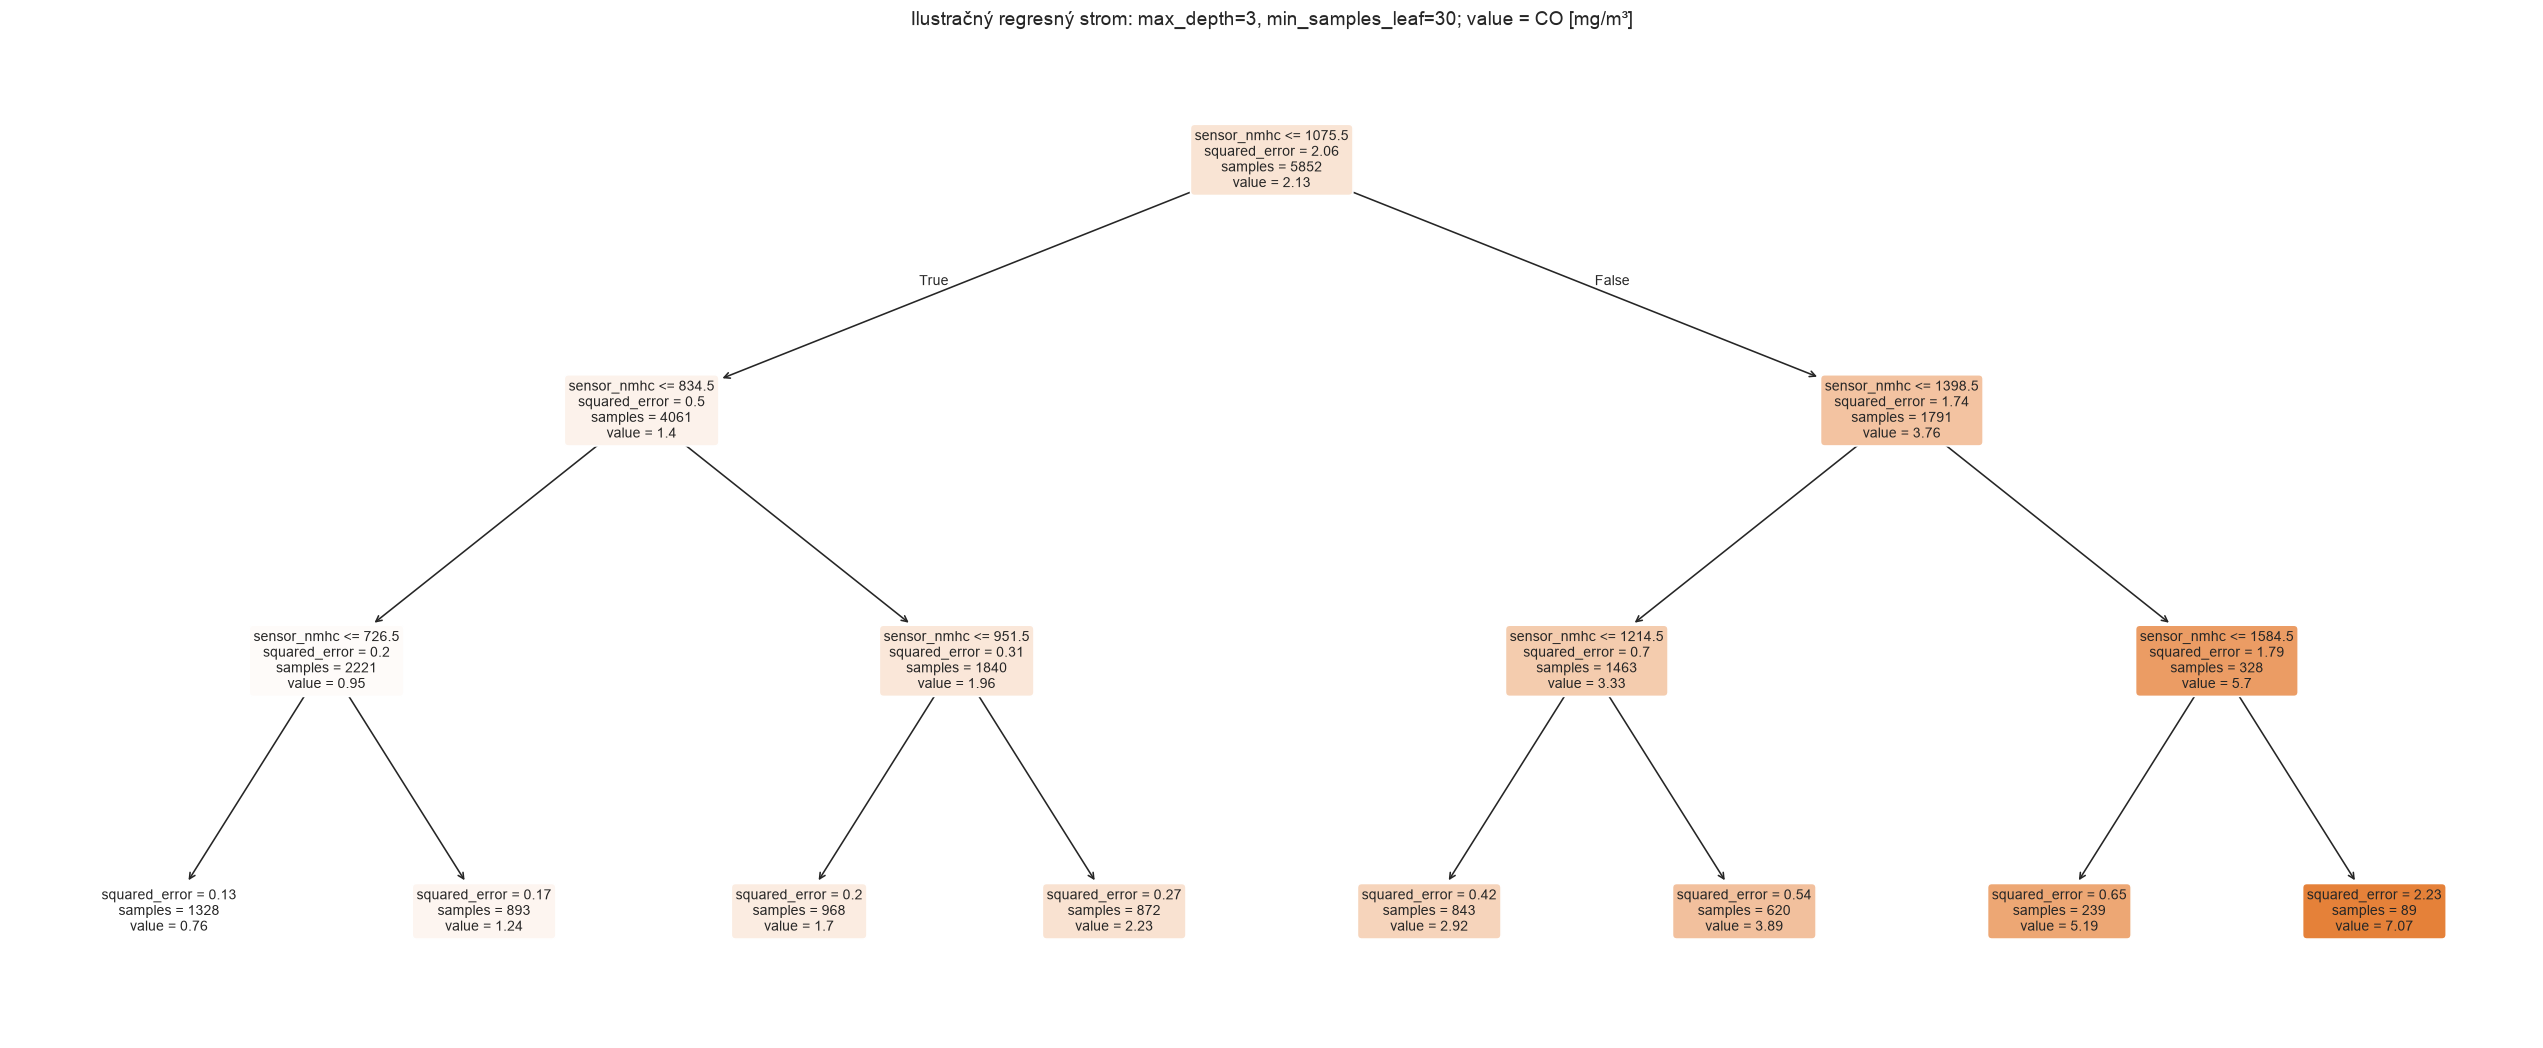

In [106]:
small_tree = DecisionTreeRegressor(max_depth=3,min_samples_leaf=30,random_state=SEED)
small_tree.fit(X_train_in[CONTINUOUS],y_train_in)
small_tree_importance = pd.DataFrame({
    'Príznak': CONTINUOUS, 'Feature importance': small_tree.feature_importances_
}).sort_values('Feature importance', ascending=False).reset_index(drop=True)
small_tree_importance.index = pd.RangeIndex(1, len(small_tree_importance)+1, name='Poradie')
print('Ilustračný strom: dôležitosť pôvodných vstupov (MDI)')
display(small_tree_importance.round(5))
fig,ax=plt.subplots(figsize=(22,9),constrained_layout=True)
plot_tree(small_tree,feature_names=CONTINUOUS,filled=True,rounded=True,precision=2,fontsize=9,ax=ax)
ax.set_title("Ilustračný regresný strom: max_depth=3, min_samples_leaf=30; value = CO [mg/m³]")
plt.show()
small_tree_metrics=regression_metrics(y_test,small_tree.predict(X_test[CONTINUOUS]))
root_feature=CONTINUOUS[small_tree.tree_.feature[0]]
root_threshold=small_tree.tree_.threshold[0]


Koreň delí podľa **$\mathrm{sensor\_nmhc} \le 1075.50$**. Ľavá vetva zodpovedá splneniu podmienky, pravá jej nesplneniu. Ilustračný strom dosahuje testovacie $R^2$ **0.8394** a RMSE 0.5769 $\mathrm{mg}/\mathrm{m}^3$. Je plytký, preto ukazuje hlavné pravidlá, ale nezachytáva všetky jemné interakcie.

Tabuľka pri výsledkoch ladeného **DecisionTree** opisuje ladený model. Samostatná tabuľka pri obrázku patrí **malému ilustračnému stromu**, ktorý používa pôvodné spojité vstupy. Tieto modely majú odlišnú hĺbku aj výsledky, preto ich dôležitosti rozlišujem.

## Ensemble

Súborové modely kombinujú viac stromov. Random Forest a ExtraTrees ich predikcie priemerujú; XGBoost a HistGradientBoosting vytvárajú postupnosť korekcií.

### RandomForest

In [107]:
name = 'RandomForest'
search = searches[name]
params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
print("Najlepšie parametre:", params)
details = pd.DataFrame(search.cv_results_)
worst_i = details.mean_test_mse.idxmin()
print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_train_r2", "std_train_r2", "mean_test_r2", "std_test_r2", "rank_test_mse"]].copy()
table["mean_train_mse"] *= -1
table["mean_test_mse"] *= -1
display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
model = trained_models[name]
rows = evaluate_model(name, model)
metric_rows.extend(rows)
display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
train_m, test_m = rows

top_importance_tables[name] = show_top_feature_importance(name)


Najlepšie parametre: {'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 1}
Najhoršie CV parametre: {'estimator__model__max_depth': 12, 'estimator__model__max_features': 1.0, 'estimator__model__min_samples_leaf': 3}
Najhoršia CV MSE: 0.1614


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,rank_test_mse
0,"{'estimator__model__max_depth': None, 'estimator__model__max_features': 0.7, 'estimator__model__...",0.0210,0.1499,0.0088,0.9898,0.0004,0.9272,0.0022,1
1,"{'estimator__model__max_depth': 12, 'estimator__model__max_features': 0.7, 'estimator__model__mi...",0.0306,0.1517,0.0074,0.9852,0.0006,0.9263,0.0018,2
2,"{'estimator__model__max_depth': None, 'estimator__model__max_features': 1.0, 'estimator__model__...",0.0221,0.1556,0.0066,0.9893,0.0004,0.9244,0.0013,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0190,0.1380,0.0855,0.9908
Test,0.1402,0.3744,0.2354,0.9323


RandomForest: najdôležitejšie príznaky (MDI – podiel zníženia MSE)


,Príznak,Feature importance
Poradie,,
1,sensor_nmhc,0.61618
2,sensor_co,0.13985
3,sensor_o3,0.13340
4,sensor_nox,0.03025
5,temperature,0.02226
6,sensor_no2,0.01479
7,hour_sin,0.01011
8,humidity,0.00875
9,hour_cos,0.00654


**RandomForest** má tréningové $R^2$ **0.9908** a testovacie $R^2$ **0.9323**. Testovacia RMSE je **0.3744 $\mathrm{mg}/\mathrm{m}^3$**, MAE 0.2354 $\mathrm{mg}/\mathrm{m}^3$. Rozdiel tréningového a testovacieho $R^2$ je 0.0584. Rozdiel upozorňuje na preučenie oproti prispôsobeniu tréningu.

,Tréning R²,Tréning MSE,Tréning RMSE,Validácia R²,Validácia MSE,Validácia RMSE
Fold,,,,,,
1,0.9895,0.0210,0.1448,0.9258,0.1624,0.4030
2,0.9903,0.0205,0.1432,0.9255,0.1438,0.3792
3,0.9896,0.0214,0.1464,0.9303,0.1436,0.3789


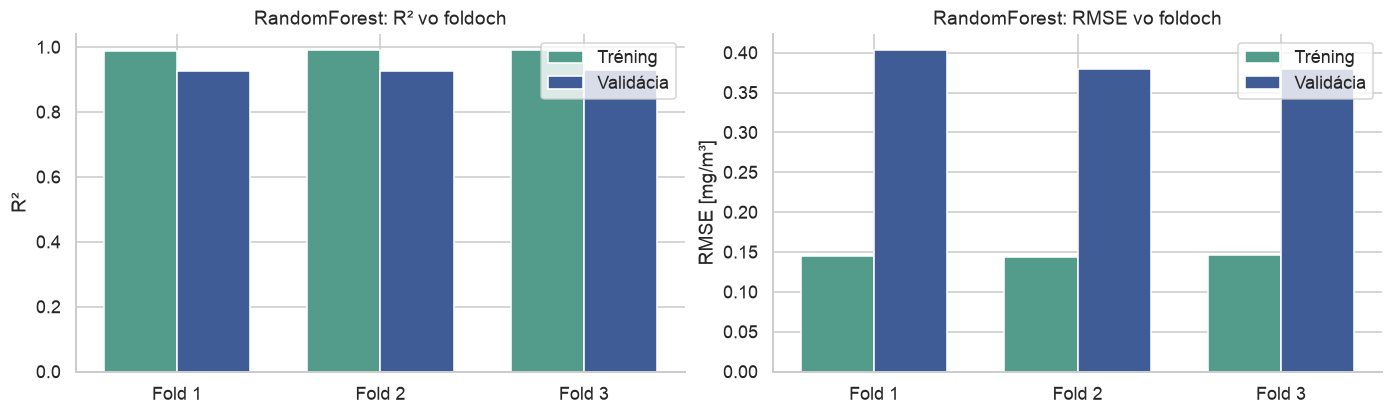

In [108]:
cv_folds_RandomForest = show_cv_diagnostics("RandomForest")

**RandomForest:** CV tréningové R² je **0.9898 ± 0.0004**, CV validačné R² **0.9272 ± 0.0022**. Rozdiel priemerov je **0.0626**. Hodnoty pochádzajú z troch samostatných foldových fitov. Finálne tréningové a testovacie výsledky vyššie patria refitu na celom tréningu, preto sa s týmito priemermi nemusia rovnať.

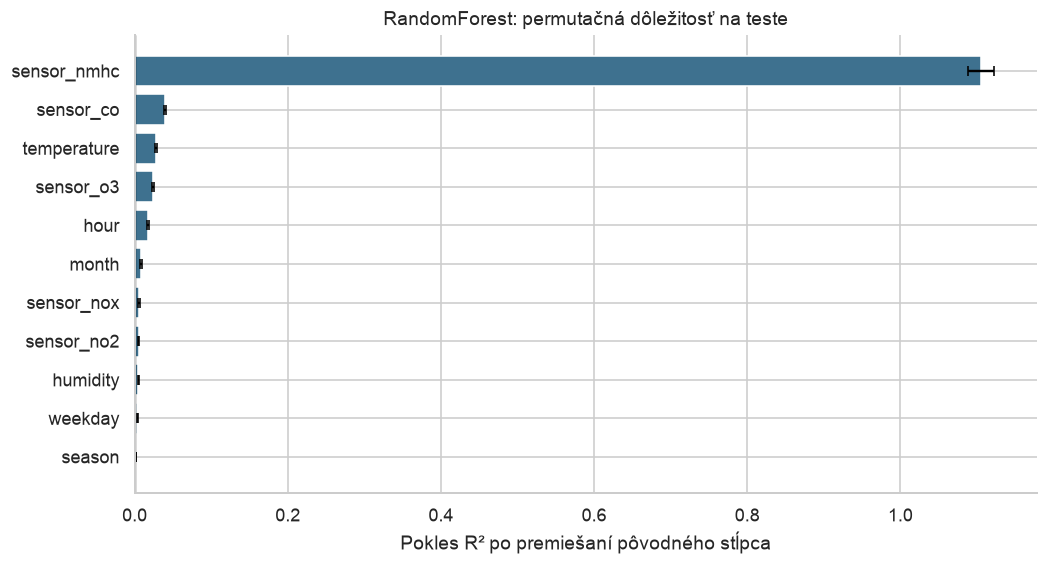

In [109]:
permutation_RandomForest = show_permutation_importance("RandomForest")

Po premiešaní **sensor_nmhc** klesne testovacie R² modelu **RandomForest** v priemere o **1.1055 ± 0.0166**. Táto hodnota je rozdiel R², nie percento. Chybové úsečky opisujú päť náhodných premiešaní pri nezmenenom modeli. Korelované vstupy môžu časť informácie navzájom nahrádzať; testový rebríček nepoužívam na výber príznakov.

#### Viacero stromov z ladeného Random Forestu

Zobrazím tri skutočné stromy lesa. Každý obrázok ukazuje výrez do hĺbky 3; `(...)` označuje pokračovanie. Prahy sú v štandardizovaných jednotkách z. Číslo stromu je jeho poradie v lese, nie poradie kvality. Predikcia lesa je priemer predikcií všetkých 200 stromov.

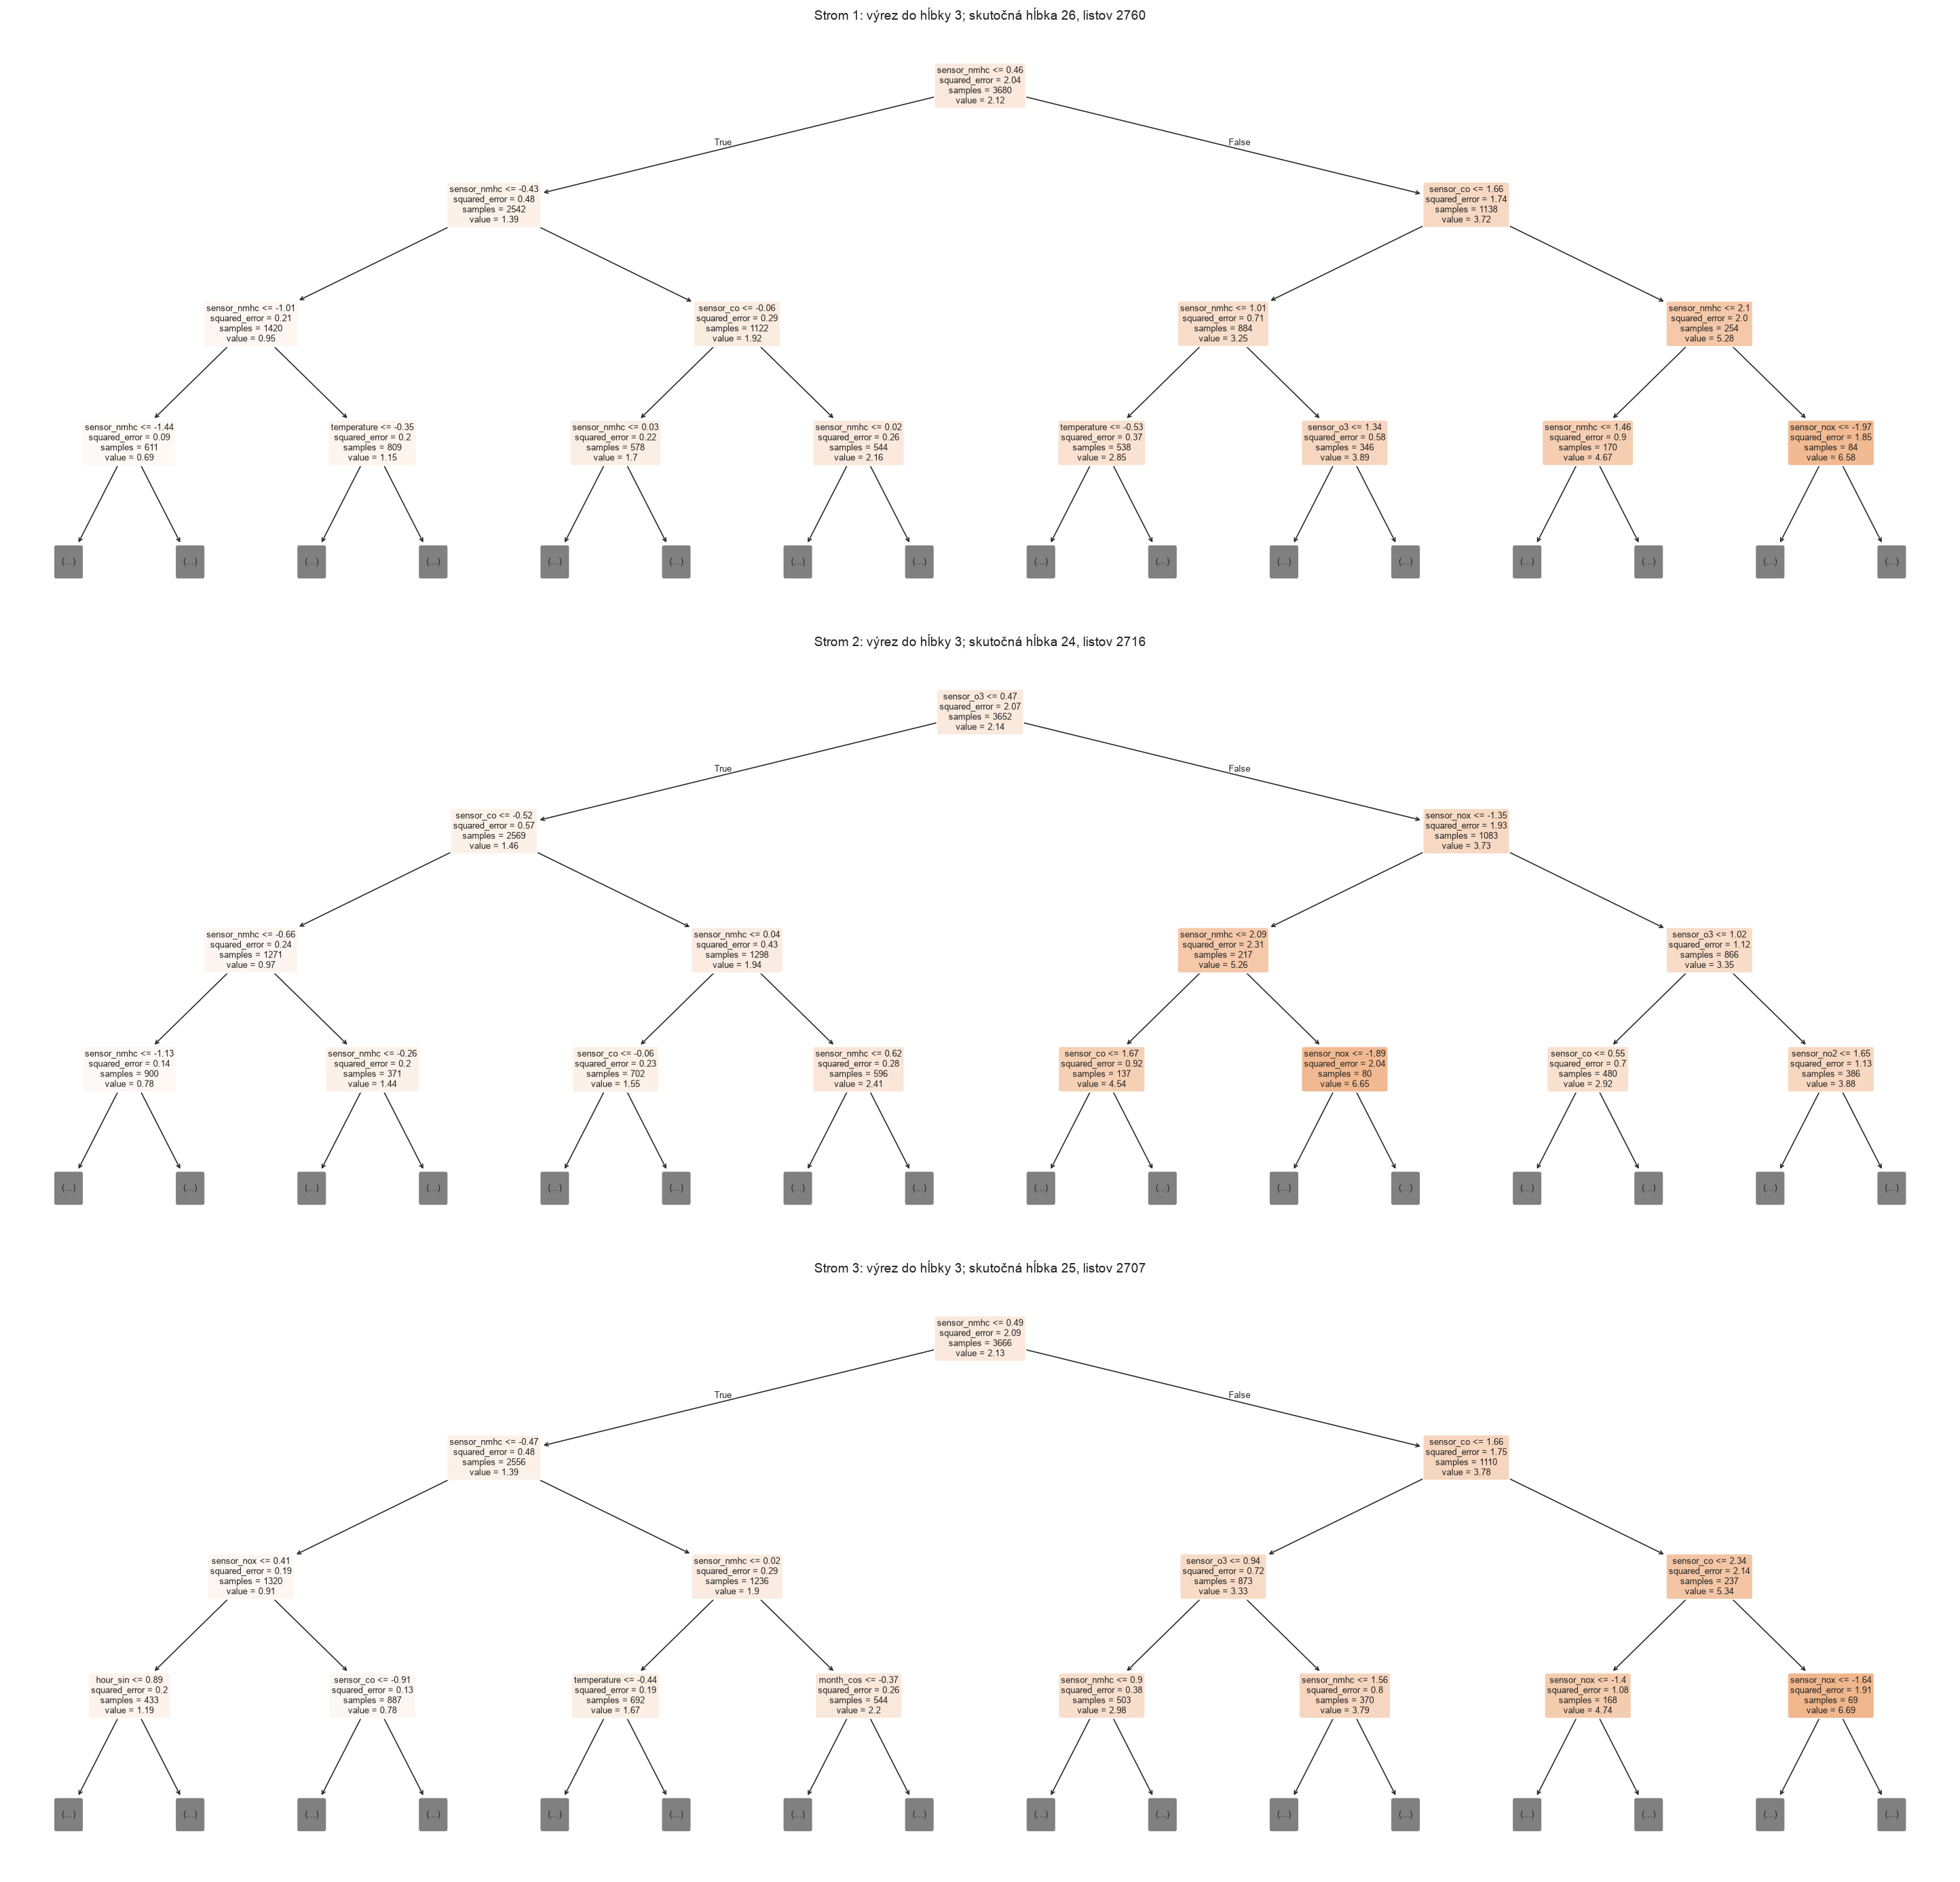

,Koreňový príznak,Prah koreňa [z],Hĺbka,Počet listov
Strom,,,,
1,sensor_nmhc,0.457,26,2760
2,sensor_o3,0.465,24,2716
3,sensor_nmhc,0.487,25,2707


Päť najdôležitejších príznakov v každom zobrazenom strome (MDI)


Príznak  Feature importance
Strom Poradie                                 
1     1        sensor_nmhc             0.75629
      2          sensor_co             0.13213
      3        temperature             0.02299
      4         sensor_nox             0.02046
      5          sensor_o3             0.01529
2     1          sensor_o3             0.56805
      2        sensor_nmhc             0.13582
      3          sensor_co             0.11203
      4         sensor_nox             0.09974
      5         sensor_no2             0.02640
3     1        sensor_nmhc             0.72613
      2          sensor_co             0.14648
      3          sensor_o3             0.03034
      4         sensor_nox             0.02801
      5        temperature             0.01652

In [110]:
rf_pipeline = trained_models['RandomForest'].estimator_
rf_model = rf_pipeline.named_steps['model']
feature_names = rf_pipeline.named_steps['preprocessing'].get_feature_names_out()
tree_indices = [0, 1, 2]
fig, axes = plt.subplots(3, 1, figsize=(25, 24), constrained_layout=True)
tree_comparison_rows = []
rf_tree_importance_rows = []
for ax, index in zip(axes, tree_indices):
    tree = rf_model.estimators_[index]
    plot_tree(tree, max_depth=3, feature_names=feature_names,
              filled=True, rounded=True, precision=2, fontsize=8, ax=ax)
    for rank, feature_index in enumerate(np.argsort(-tree.feature_importances_, kind='stable')[:5], start=1):
        rf_tree_importance_rows.append({'Strom': index+1, 'Poradie': rank,
            'Príznak': feature_names[feature_index], 'Feature importance': tree.feature_importances_[feature_index]})
    root = int(tree.tree_.feature[0])
    root_name = feature_names[root] if root >= 0 else 'List bez delenia'
    ax.set_title(f'Strom {index+1}: výrez do hĺbky 3; skutočná hĺbka {tree.get_depth()}, listov {tree.get_n_leaves()}')
    tree_comparison_rows.append({'Strom': index+1, 'Koreňový príznak': root_name,
        'Prah koreňa [z]': tree.tree_.threshold[0], 'Hĺbka': tree.get_depth(), 'Počet listov': tree.get_n_leaves()})
plt.show()
rf_tree_comparison = pd.DataFrame(tree_comparison_rows).set_index('Strom')
display(rf_tree_comparison.round(3))

rf_tree_importance = pd.DataFrame(rf_tree_importance_rows).set_index(['Strom', 'Poradie'])
print('Päť najdôležitejších príznakov v každom zobrazenom strome (MDI)')
display(rf_tree_importance.round(5))


Les obsahuje **200 stromov**. Zobrazené stromy majú skutočné hĺbky **26, 24, 25** a korene podľa **sensor_nmhc, sensor_o3, sensor_nmhc**. Tabuľka porovnáva aj prahy a počty listov. Rozdiely vznikajú bootstrapovými vzorkami a náhodným výberom príznakov; obrázky ukazujú iba začiatky stromov. Výslednú predikciu tvorí priemer celého lesa.

#### Natívna dôležitosť a pôvodná tréningová permutácia

Nasledujúci blok zachováva pôvodnú analýzu Random Forestu. Ľavý graf a tabuľka zobrazujú MDI kódovaných vstupov, pravý pôvodnú tréningovú permutáciu. Od testovej permutácie vyššie sa líši množinou hodnotených meraní.

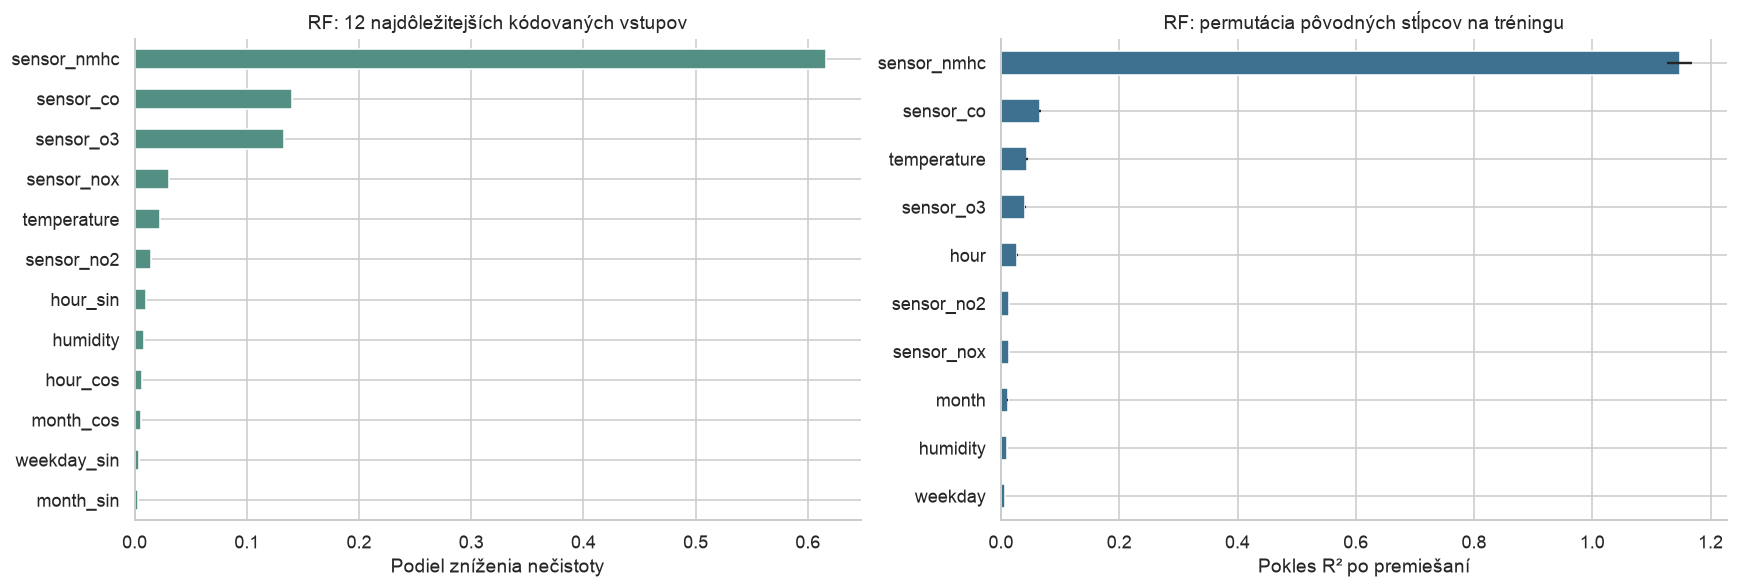

,Dôležitosť
sensor_nmhc,0.6162
sensor_co,0.1398
sensor_o3,0.1334
sensor_nox,0.0302
temperature,0.0223
sensor_no2,0.0148
hour_sin,0.0101
humidity,0.0087
hour_cos,0.0065
month_cos,0.0055


In [111]:
rf_importance = pd.Series(rf_model.feature_importances_,index=feature_names).sort_values(ascending=False)
with threadpool_limits(limits=1):
    perm = permutation_importance(trained_models["RandomForest"],X_train,y_train,
                                 scoring="r2",n_repeats=5,random_state=SEED,n_jobs=1)
perm_table = pd.DataFrame({"Priemer":perm.importances_mean,"SD":perm.importances_std},index=X_train.columns).sort_values("Priemer",ascending=False)
fig,axes=plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
rf_importance.head(12).sort_values().plot.barh(ax=axes[0],color="#538f83")
axes[0].set(title="RF: 12 najdôležitejších kódovaných vstupov",xlabel="Podiel zníženia nečistoty")
perm_table.head(10).sort_values("Priemer").plot.barh(y="Priemer",xerr="SD",ax=axes[1],legend=False,color="#3e718f")
axes[1].set(title="RF: permutácia pôvodných stĺpcov na tréningu",xlabel="Pokles R² po premiešaní")
plt.show()
display(rf_importance.rename("Dôležitosť").to_frame().round(4))


Najvyššiu uzlovú dôležitosť má **sensor_nmhc** (0.616), pri permutácii vedie **sensor_nmhc** s poklesom tréningového $R^2$ 1.148. Poradie nemusí byť totožné: jeden graf meria využívanie pri delení stromov, druhý citlivosť predikcií na porušenie daného vstupu. Korelovaný senzor môže časť informácie nahradiť.

#### Prečo má príznak vysokú dôležitosť

Pri regresnom strome je nečistota uzla vážená MSE cieľových hodnôt okolo priemeru. Príspevok delenia je zlepšenie voči potomkom, vážené podielom meraní v uzle:

$$
\Delta_t = \frac{w_t}{w_{root}}\left(I_t - \frac{w_L}{w_t}I_L - \frac{w_R}{w_t}I_R\right).
$$

Napríklad pri 100 meraniach, MSE rodiča 4 a potomkoch s 60 meraniami/MSE 1 a 40 meraniami/MSE 2 je zlepšenie koreňa $4-0{,}6\cdot1-0{,}4\cdot2=2{,}6$. Strom sčíta príspevky jednotlivých príznakov a normalizuje ich; les spriemeruje dôležitosti stromov. Bootstrapové váhy zahŕňajú aj opakované výbery rovnakého merania.

MDI 0,616 znamená približne 61,6 % relatívneho kreditu za delenia, nie 61,6 % vysvetlenej variability CO. MDI môže zvýhodňovať vstupy s mnohými možnými prahmi. Permutácia meria inú veličinu – pokles R² bez opätovného trénovania. Pri korelovaných senzoroch sa oba rebríčky môžu líšiť.

Nižšie zachovávam kontrolu desiatich najväčších príspevkov prvého stromu, ručnú rekonštrukciu dôležitostí celého lesa a zoskupenie MDI na pôvodné stĺpce. [Definícia MDI a jej obmedzenia](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html).

In [112]:
def reconstruct_tree_importance(estimator, names):
    tree = estimator.tree_
    rows = []
    total_by_feature = np.zeros(len(names))
    root_weight = tree.weighted_n_node_samples[0]
    for node in range(tree.node_count):
        left, right = tree.children_left[node], tree.children_right[node]
        if left < 0:
            continue
        weight = tree.weighted_n_node_samples[node]
        local_gain = (tree.impurity[node]
                      - tree.weighted_n_node_samples[left] / weight * tree.impurity[left]
                      - tree.weighted_n_node_samples[right] / weight * tree.impurity[right])
        weighted_gain = weight / root_weight * local_gain
        feature = tree.feature[node]
        total_by_feature[feature] += weighted_gain
        rows.append({"Uzol": node, "Príznak": names[feature],
                     "Váha uzla": weight, "I(uzol)": tree.impurity[node],
                     "I(ľavý)": tree.impurity[left], "I(pravý)": tree.impurity[right],
                     "Váha ľavého": tree.weighted_n_node_samples[left],
                     "Váha pravého": tree.weighted_n_node_samples[right],
                     "Vážené zlepšenie Δ": weighted_gain})
    if total_by_feature.sum() > 0:
        total_by_feature /= total_by_feature.sum()
    return total_by_feature, pd.DataFrame(rows)

manual_importances = []
for tree_number, estimator in enumerate(rf_model.estimators_):
    values, nodes = reconstruct_tree_importance(estimator, feature_names)
    manual_importances.append(values)
    if tree_number == 0:
        first_tree_nodes = nodes
manual_forest_importance = np.mean(manual_importances, axis=0)
manual_forest_importance /= manual_forest_importance.sum()
mdi_max_error = float(np.max(np.abs(manual_forest_importance-rf_model.feature_importances_)))
assert np.allclose(manual_forest_importance, rf_model.feature_importances_, atol=1e-12)
display(first_tree_nodes.nlargest(10, "Vážené zlepšenie Δ").round(5))

def original_feature(name):
    if name.startswith("season_"):
        return "season"
    if name.endswith("_sin") or name.endswith("_cos"):
        return name.rsplit("_", 1)[0]
    return name

mdi_grouped = rf_importance.groupby([original_feature(name) for name in rf_importance.index]).sum()
importance_comparison = (mdi_grouped.rename("MDI: podiel")
                         .to_frame().join(perm_table.rename(columns={"Priemer":"PI: pokles R²", "SD":"PI: SD"})))
importance_comparison = importance_comparison.sort_values("MDI: podiel", ascending=False)
rf_train_r2 = r2_score(y_train, trained_models["RandomForest"].predict(X_train))
importance_comparison["Priemerné R² po permutácii"] = rf_train_r2-importance_comparison["PI: pokles R²"]
display(importance_comparison.round(5))
first_root = first_tree_nodes.loc[first_tree_nodes.Uzol.eq(0)].iloc[0]
top_feature = importance_comparison.index[0]
top_info = importance_comparison.iloc[0]


,Uzol,Príznak,Váha uzla,I(uzol),I(ľavý),I(pravý),Váha ľavého,Váha pravého,Vážené zlepšenie Δ
0,0,sensor_nmhc,5852.0,2.04486,0.47651,1.73576,4009.0,1843.0,1.17177
1800,3600,sensor_co,1843.0,1.73576,0.70509,2.00252,1418.0,425.0,0.23037
1,1,sensor_nmhc,4009.0,0.47651,0.20658,0.28954,2218.0,1791.0,0.15953
1801,3601,sensor_nmhc,1418.0,0.70509,0.36837,0.57537,875.0,543.0,0.06238
2538,5076,sensor_nmhc,425.0,2.00252,0.90456,1.84522,289.0,136.0,0.05788
2,2,sensor_nmhc,2218.0,0.20658,0.09353,0.19755,953.0,1265.0,0.02036
918,1835,sensor_co,1791.0,0.28954,0.21520,0.25814,912.0,879.0,0.01630
2686,5372,sensor_nox,136.0,1.84522,2.45234,1.09215,8.0,128.0,0.01564
2539,5077,sensor_nmhc,289.0,0.90456,0.65246,0.61739,123.0,166.0,0.01344
1802,3602,temperature,875.0,0.36837,0.52258,0.24373,192.0,683.0,0.00949


,MDI: podiel,PI: pokles R²,PI: SD,Priemerné R² po permutácii
sensor_nmhc,0.61618,1.14820,0.02106,-0.15744
sensor_co,0.13985,0.06612,0.00124,0.92463
sensor_o3,0.13340,0.04118,0.00109,0.94958
sensor_nox,0.03025,0.01290,0.00022,0.97785
temperature,0.02226,0.04387,0.00100,0.94688
hour,0.01665,0.02735,0.00073,0.96340
sensor_no2,0.01479,0.01302,0.00017,0.97773
humidity,0.00875,0.00965,0.00011,0.98111
month,0.00845,0.01103,0.00009,0.97973
weekday,0.00620,0.00726,0.00014,0.98349


**Skutočný koreň prvého stromu:** delí podľa sensor_nmhc. Nečistota rodiča je 2.0449, potomkovia majú nečistoty 0.4765 a 1.7358, s bootstrapovými váhami 4009 a 1843. Ich odčítaním podľa vzorca získam **$\Delta = 1.1718$**. Maximálna odchýlka ručne rekonštruovanej dôležitosti celého lesa od knižnice je $1.11 \times 10^{-16}$.

**sensor_nmhc** získal MDI **0.6162**, teda 61.62 % relatívneho kreditu za delenia. Tréningové $R^2$ lesa pred permutáciou je 0.9908, po jeho premiešaní je v priemere **-0.1574**. Rozdiel **1.1482** je meraný v jednotkách $R^2$, nie v percentách. Ak skóre po premiešaní klesne pod nulu, narušený model je na týchto meraniach horší než konštantná predikcia ich priemeru. To vysvetľuje aj permutačnú dôležitosť väčšiu než 1. Výsledok svedčí o závislosti lesa od vstupu. Nehovorí, že daný senzor spôsobuje zmenu CO.

### ExtraTrees

In [113]:
name = 'ExtraTrees'
search = searches[name]
params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
print("Najlepšie parametre:", params)
details = pd.DataFrame(search.cv_results_)
worst_i = details.mean_test_mse.idxmin()
print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_train_r2", "std_train_r2", "mean_test_r2", "std_test_r2", "rank_test_mse"]].copy()
table["mean_train_mse"] *= -1
table["mean_test_mse"] *= -1
display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
model = trained_models[name]
rows = evaluate_model(name, model)
metric_rows.extend(rows)
display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
train_m, test_m = rows

top_importance_tables[name] = show_top_feature_importance(name)


Najlepšie parametre: {'max_features': 0.7, 'min_samples_leaf': 1}
Najhoršie CV parametre: {'estimator__model__max_features': 0.7, 'estimator__model__min_samples_leaf': 3}
Najhoršia CV MSE: 0.1437


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,rank_test_mse
0,"{'estimator__model__max_features': 0.7, 'estimator__model__min_samples_leaf': 1}",0.000,0.1297,0.0095,1.000,0.0000,0.9370,0.0034,1
1,"{'estimator__model__max_features': 1.0, 'estimator__model__min_samples_leaf': 1}",0.000,0.1319,0.0079,1.000,0.0000,0.9359,0.0027,2
2,"{'estimator__model__max_features': 1.0, 'estimator__model__min_samples_leaf': 3}",0.033,0.1430,0.0092,0.984,0.0007,0.9306,0.0018,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0000,0.0035,0.0002,1.0000
Test,0.1216,0.3486,0.2221,0.9413


ExtraTrees: najdôležitejšie príznaky (MDI – podiel zníženia MSE)


,Príznak,Feature importance
Poradie,,
1,sensor_nmhc,0.34091
2,sensor_o3,0.22274
3,sensor_co,0.20393
4,sensor_nox,0.09293
5,sensor_no2,0.03755
6,hour_sin,0.02440
7,temperature,0.01245
8,hour_cos,0.01125
9,month_cos,0.00882


**ExtraTrees** má tréningové $R^2$ **1.0000** a testovacie $R^2$ **0.9413**. Testovacia RMSE je **0.3486 $\mathrm{mg}/\mathrm{m}^3$**, MAE 0.2221 $\mathrm{mg}/\mathrm{m}^3$. Rozdiel tréningového a testovacieho $R^2$ je 0.0587. Takmer nulová tréningová chyba pri nenulovej testovacej ukazuje silné zapamätanie tréningových meraní.

,Tréning R²,Tréning MSE,Tréning RMSE,Validácia R²,Validácia MSE,Validácia RMSE
Fold,,,,,,
1,1.0,0.0,0.0056,0.9348,0.1426,0.3776
2,1.0,0.0,0.0059,0.9343,0.1268,0.3561
3,1.0,0.0,0.0032,0.9418,0.1198,0.3462


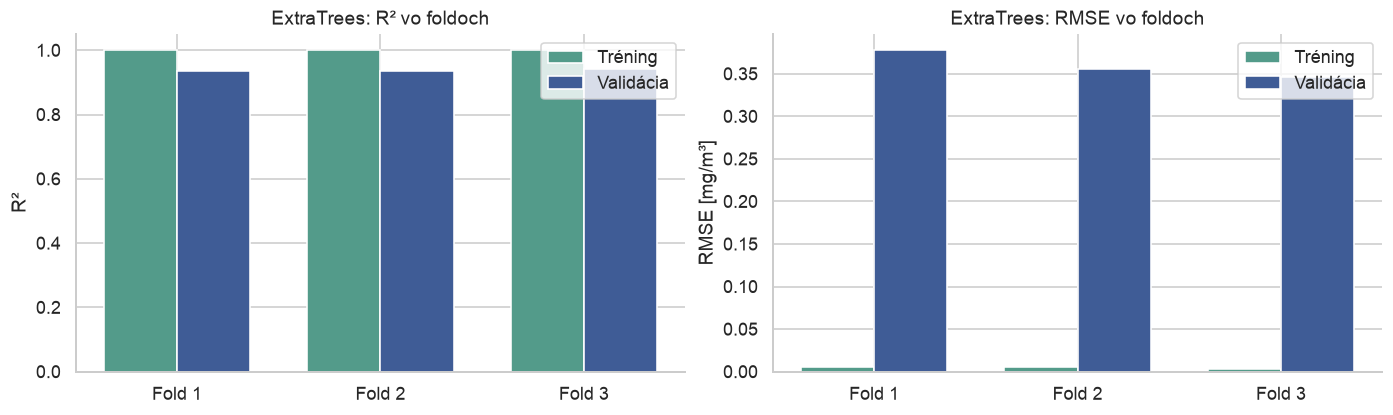

In [114]:
cv_folds_ExtraTrees = show_cv_diagnostics("ExtraTrees")

**ExtraTrees:** CV tréningové R² je **1.0000 ± 0.0000**, CV validačné R² **0.9370 ± 0.0034**. Rozdiel priemerov je **0.0630**. Hodnoty pochádzajú z troch samostatných foldových fitov. Finálne tréningové a testovacie výsledky vyššie patria refitu na celom tréningu, preto sa s týmito priemermi nemusia rovnať.

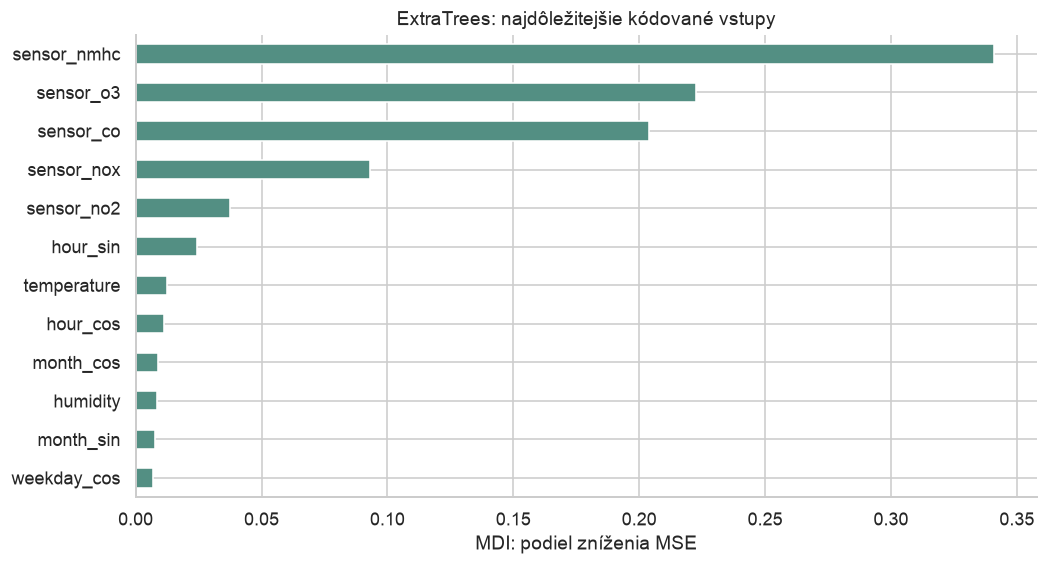

In [115]:
native_ExtraTrees = show_native_importance("ExtraTrees")

Najvyššiu natívnu dôležitosť modelu **ExtraTrees** má **sensor_nmhc**, MDI **0.34091**. Prvé tri vstupy spolu získali **76.76%** relatívnej dôležitosti. Ide o využitie vstupov konkrétnym natrénovaným modelom, nie o podiel vysvetleného CO alebo príčinný vplyv. Tabuľka pri výsledkoch tréningu zobrazuje najviac 10 najdôležitejších kódovaných vstupov; graf zobrazuje prvých 12.

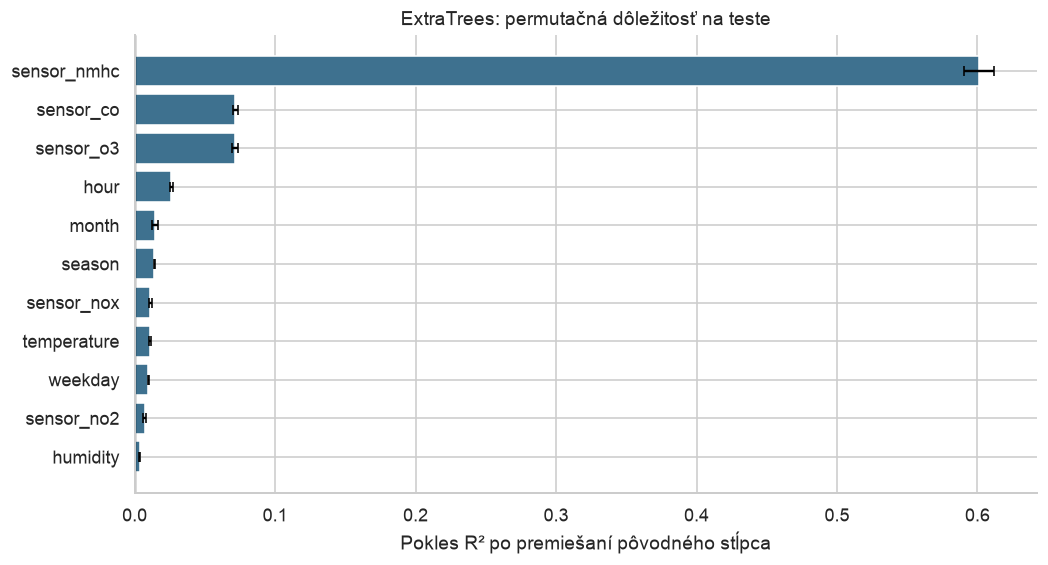

In [116]:
permutation_ExtraTrees = show_permutation_importance("ExtraTrees")

Po premiešaní **sensor_nmhc** klesne testovacie R² modelu **ExtraTrees** v priemere o **0.6010 ± 0.0107**. Táto hodnota je rozdiel R², nie percento. Chybové úsečky opisujú päť náhodných premiešaní pri nezmenenom modeli. Korelované vstupy môžu časť informácie navzájom nahrádzať; testový rebríček nepoužívam na výber príznakov.

### XGBoost

In [117]:
name = 'XGBoost'
search = searches[name]
params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
print("Najlepšie parametre:", params)
details = pd.DataFrame(search.cv_results_)
worst_i = details.mean_test_mse.idxmin()
print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_train_r2", "std_train_r2", "mean_test_r2", "std_test_r2", "rank_test_mse"]].copy()
table["mean_train_mse"] *= -1
table["mean_test_mse"] *= -1
display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
model = trained_models[name]
rows = evaluate_model(name, model)
metric_rows.extend(rows)
display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
train_m, test_m = rows

top_importance_tables[name] = show_top_feature_importance(name)


Najlepšie parametre: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 400, 'reg_lambda': 1.0}
Najhoršie CV parametre: {'estimator__model__learning_rate': 0.05, 'estimator__model__max_depth': 3, 'estimator__model__n_estimators': 200, 'estimator__model__reg_lambda': 5.0}
Najhoršia CV MSE: 0.157


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,rank_test_mse
0,"{'estimator__model__learning_rate': 0.05, 'estimator__model__max_depth': 5, 'estimator__model__n...",0.0317,0.1284,0.0076,0.9846,0.0009,0.9376,0.0040,1
1,"{'estimator__model__learning_rate': 0.1, 'estimator__model__max_depth': 5, 'estimator__model__n_...",0.0183,0.1290,0.0069,0.9911,0.0006,0.9373,0.0035,2
2,"{'estimator__model__learning_rate': 0.1, 'estimator__model__max_depth': 5, 'estimator__model__n_...",0.0127,0.1292,0.0083,0.9939,0.0003,0.9372,0.0038,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0429,0.2072,0.1453,0.9792
Test,0.1204,0.3470,0.2241,0.9419


XGBoost: najdôležitejšie príznaky (normalizovaný gain)


,Príznak,Feature importance
Poradie,,
1,sensor_nmhc,0.59537
2,sensor_o3,0.10499
3,sensor_co,0.09860
4,season_summer,0.03393
5,season_winter,0.02666
6,hour_sin,0.01987
7,temperature,0.01919
8,month_cos,0.01780
9,hour_cos,0.01371


**XGBoost** má tréningové $R^2$ **0.9792** a testovacie $R^2$ **0.9419**. Testovacia RMSE je **0.3470 $\mathrm{mg}/\mathrm{m}^3$**, MAE 0.2241 $\mathrm{mg}/\mathrm{m}^3$. Rozdiel tréningového a testovacieho $R^2$ je 0.0373. Rozdiel je menší než pri výrazne preučených súborových modeloch.

,Tréning R²,Tréning MSE,Tréning RMSE,Validácia R²,Validácia MSE,Validácia RMSE
Fold,,,,,,
1,0.9844,0.0311,0.1764,0.9374,0.1369,0.3700
2,0.9859,0.0300,0.1733,0.9327,0.1298,0.3602
3,0.9836,0.0338,0.1839,0.9425,0.1184,0.3441


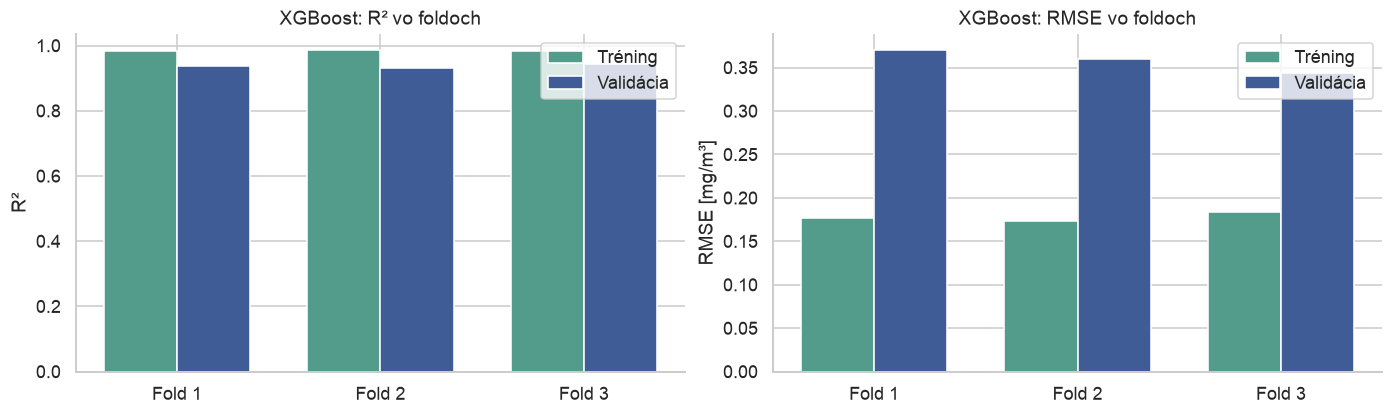

In [118]:
cv_folds_XGBoost = show_cv_diagnostics("XGBoost")

**XGBoost:** CV tréningové R² je **0.9846 ± 0.0009**, CV validačné R² **0.9376 ± 0.0040**. Rozdiel priemerov je **0.0471**. Hodnoty pochádzajú z troch samostatných foldových fitov. Finálne tréningové a testovacie výsledky vyššie patria refitu na celom tréningu, preto sa s týmito priemermi nemusia rovnať.

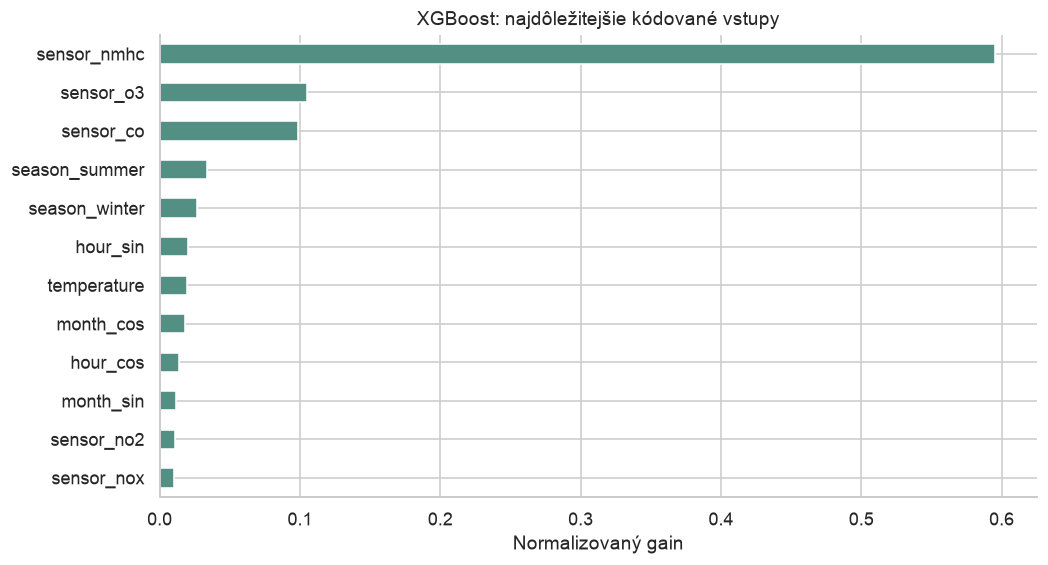

In [119]:
native_XGBoost = show_native_importance("XGBoost")

Najvyššiu natívnu dôležitosť modelu **XGBoost** má **sensor_nmhc**, normalizovaný gain **0.59537**. Prvé tri vstupy spolu získali **79.90%** relatívnej dôležitosti. Ide o využitie vstupov konkrétnym natrénovaným modelom, nie o podiel vysvetleného CO alebo príčinný vplyv. Tabuľka pri výsledkoch tréningu zobrazuje najviac 10 najdôležitejších kódovaných vstupov; graf zobrazuje prvých 12.

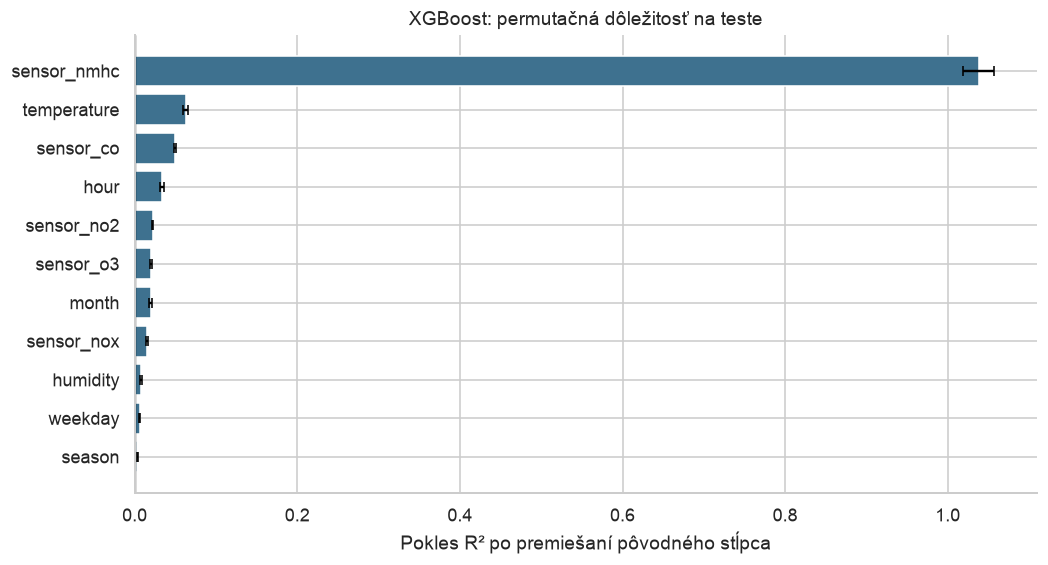

In [120]:
permutation_XGBoost = show_permutation_importance("XGBoost")

Po premiešaní **sensor_nmhc** klesne testovacie R² modelu **XGBoost** v priemere o **1.0381 ± 0.0187**. Táto hodnota je rozdiel R², nie percento. Chybové úsečky opisujú päť náhodných premiešaní pri nezmenenom modeli. Korelované vstupy môžu časť informácie navzájom nahrádzať; testový rebríček nepoužívam na výber príznakov.

### HistGradientBoosting

In [121]:
name = 'HistGradientBoosting'
search = searches[name]
params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
print("Najlepšie parametre:", params)
details = pd.DataFrame(search.cv_results_)
worst_i = details.mean_test_mse.idxmin()
print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_train_r2", "std_train_r2", "mean_test_r2", "std_test_r2", "rank_test_mse"]].copy()
table["mean_train_mse"] *= -1
table["mean_test_mse"] *= -1
display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
model = trained_models[name]
rows = evaluate_model(name, model)
metric_rows.extend(rows)
display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
train_m, test_m = rows

top_importance_tables[name] = show_top_feature_importance(name)


Najlepšie parametre: {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_leaf_nodes': 15}
Najhoršie CV parametre: {'estimator__model__l2_regularization': 1.0, 'estimator__model__learning_rate': 0.05, 'estimator__model__max_leaf_nodes': 15}
Najhoršia CV MSE: 0.131


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,rank_test_mse
0,"{'estimator__model__l2_regularization': 0.0, 'estimator__model__learning_rate': 0.1, 'estimator_...",0.0402,0.1256,0.0070,0.9805,0.0010,0.9388,0.0046,1
1,"{'estimator__model__l2_regularization': 1.0, 'estimator__model__learning_rate': 0.1, 'estimator_...",0.0411,0.1257,0.0065,0.9800,0.0012,0.9388,0.0038,2
2,"{'estimator__model__l2_regularization': 0.0, 'estimator__model__learning_rate': 0.1, 'estimator_...",0.0167,0.1282,0.0063,0.9919,0.0005,0.9377,0.0026,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0488,0.2208,0.1544,0.9763
Test,0.1210,0.3478,0.2283,0.9416


HistGradientBoosting: najdôležitejšie príznaky (testová permutácia – pokles R²; SD z piatich opakovaní)


,Príznak,Feature importance,SD
Poradie,,,
1,sensor_nmhc,1.25915,0.01659
2,temperature,0.06651,0.00349
3,hour,0.03505,0.00216
4,sensor_co,0.03456,0.00167
5,month,0.02931,0.00251
6,sensor_o3,0.01168,0.00027
7,humidity,0.00880,0.00154
8,weekday,0.00850,0.00069
9,sensor_no2,0.00758,0.00119


**HistGradientBoosting** má tréningové $R^2$ **0.9763** a testovacie $R^2$ **0.9416**. Testovacia RMSE je **0.3478 $\mathrm{mg}/\mathrm{m}^3$**, MAE 0.2283 $\mathrm{mg}/\mathrm{m}^3$. Rozdiel tréningového a testovacieho $R^2$ je 0.0347. Rozdiel je menší než pri výrazne preučených súborových modeloch.

,Tréning R²,Tréning MSE,Tréning RMSE,Validácia R²,Validácia MSE,Validácia RMSE
Fold,,,,,,
1,0.9794,0.0410,0.2025,0.9401,0.1312,0.3622
2,0.9818,0.0387,0.1968,0.9327,0.1298,0.3603
3,0.9802,0.0409,0.2022,0.9438,0.1158,0.3403


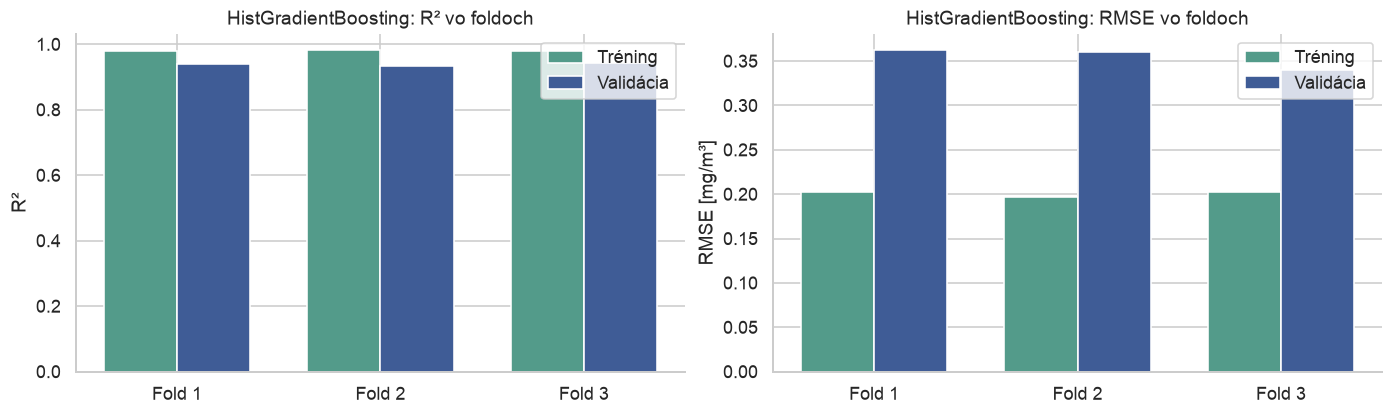

In [122]:
cv_folds_HistGradientBoosting = show_cv_diagnostics("HistGradientBoosting")

**HistGradientBoosting:** CV tréningové R² je **0.9805 ± 0.0010**, CV validačné R² **0.9388 ± 0.0046**. Rozdiel priemerov je **0.0416**. Hodnoty pochádzajú z troch samostatných foldových fitov. Finálne tréningové a testovacie výsledky vyššie patria refitu na celom tréningu, preto sa s týmito priemermi nemusia rovnať.

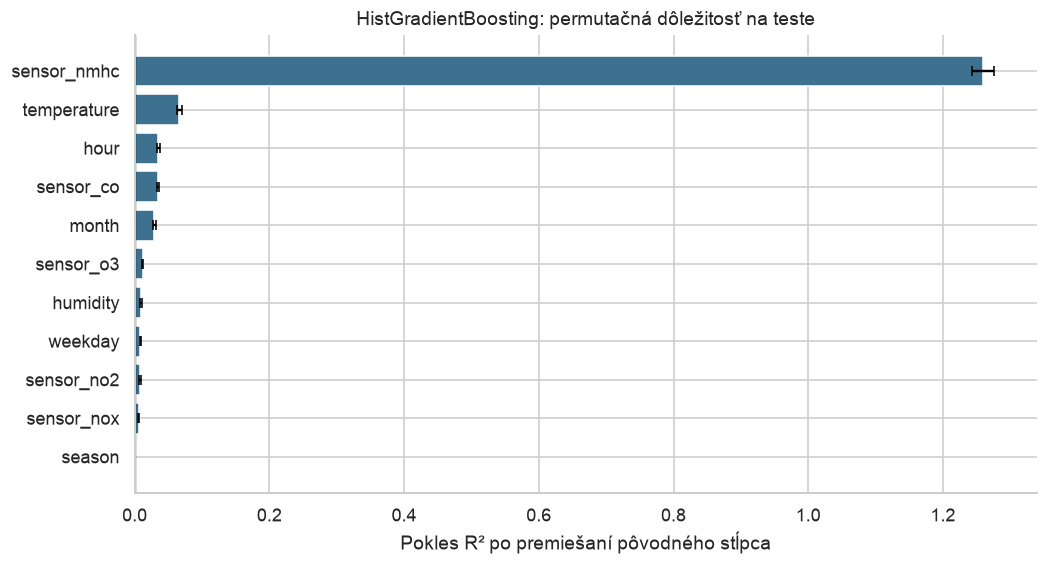

In [123]:
permutation_HistGradientBoosting = show_permutation_importance("HistGradientBoosting")

Po premiešaní **sensor_nmhc** klesne testovacie R² modelu **HistGradientBoosting** v priemere o **1.2591 ± 0.0166**. Táto hodnota je rozdiel R², nie percento. Chybové úsečky opisujú päť náhodných premiešaní pri nezmenenom modeli. Korelované vstupy môžu časť informácie navzájom nahrádzať; testový rebríček nepoužívam na výber príznakov.

## SVM teda SVR

In [124]:
name = 'SVR'
search = searches[name]
params = {k.replace("estimator__model__", ""): v for k,v in search.best_params_.items()}
print("Najlepšie parametre:", params)
details = pd.DataFrame(search.cv_results_)
worst_i = details.mean_test_mse.idxmin()
print("Najhoršie CV parametre:", details.loc[worst_i,"params"])
print("Najhoršia CV MSE:", round(-details.loc[worst_i,"mean_test_mse"],4))
table = details[["params", "mean_train_mse", "mean_test_mse", "std_test_mse", "mean_train_r2", "std_train_r2", "mean_test_r2", "std_test_r2", "rank_test_mse"]].copy()
table["mean_train_mse"] *= -1
table["mean_test_mse"] *= -1
display(table.sort_values("rank_test_mse").head(3).reset_index(drop=True).round(4))
model = trained_models[name]
rows = evaluate_model(name, model)
metric_rows.extend(rows)
display(pd.DataFrame(rows).drop(columns="Model").set_index("Množina").round(4))
train_m, test_m = rows

top_importance_tables[name] = show_top_feature_importance(name)


Najlepšie parametre: {'C': 100.0, 'epsilon': 0.1, 'gamma': 'scale'}
Najhoršie CV parametre: {'estimator__model__C': 10.0, 'estimator__model__epsilon': 0.05, 'estimator__model__gamma': 0.01}
Najhoršia CV MSE: 0.1503


,params,mean_train_mse,mean_test_mse,std_test_mse,mean_train_r2,std_train_r2,mean_test_r2,std_test_r2,rank_test_mse
0,"{'estimator__model__C': 100.0, 'estimator__model__epsilon': 0.1, 'estimator__model__gamma': 'sca...",0.0324,0.1046,0.0063,0.9843,0.0006,0.9492,0.0028,1
1,"{'estimator__model__C': 100.0, 'estimator__model__epsilon': 0.05, 'estimator__model__gamma': 'sc...",0.0320,0.1055,0.0049,0.9845,0.0006,0.9487,0.0029,2
2,"{'estimator__model__C': 10.0, 'estimator__model__epsilon': 0.1, 'estimator__model__gamma': 0.1}",0.0461,0.1071,0.0040,0.9776,0.0006,0.9479,0.0026,3


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0350,0.1870,0.1199,0.9830
Test,0.0947,0.3077,0.1994,0.9543


SVR: najdôležitejšie príznaky (testová permutácia – pokles R²; SD z piatich opakovaní)


,Príznak,Feature importance,SD
Poradie,,,
1,sensor_nmhc,1.04514,0.01663
2,month,0.44694,0.01783
3,sensor_no2,0.42665,0.00854
4,temperature,0.33007,0.01338
5,season,0.32260,0.01466
6,sensor_o3,0.27786,0.00831
7,sensor_co,0.24115,0.00678
8,humidity,0.14862,0.00538
9,sensor_nox,0.12299,0.00333


**SVR** má tréningové $R^2$ **0.9830** a testovacie $R^2$ **0.9543**. Testovacia RMSE je **0.3077 $\mathrm{mg}/\mathrm{m}^3$**, MAE 0.1994 $\mathrm{mg}/\mathrm{m}^3$. Rozdiel tréningového a testovacieho $R^2$ je 0.0287. Rozdiel je menší než pri výrazne preučených súborových modeloch.

,Tréning R²,Tréning MSE,Tréning RMSE,Validácia R²,Validácia MSE,Validácia RMSE
Fold,,,,,,
1,0.9851,0.0297,0.1724,0.9486,0.1126,0.3355
2,0.9838,0.0344,0.1855,0.9461,0.1040,0.3225
3,0.9839,0.0331,0.1819,0.9528,0.0972,0.3117


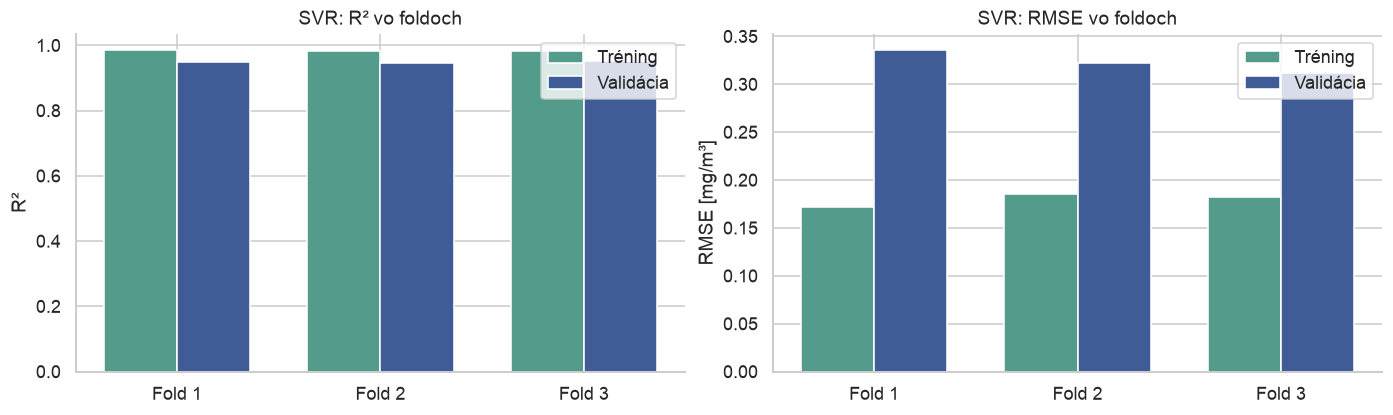

In [125]:
cv_folds_SVR = show_cv_diagnostics("SVR")

**SVR:** CV tréningové R² je **0.9843 ± 0.0006**, CV validačné R² **0.9492 ± 0.0028**. Rozdiel priemerov je **0.0351**. Hodnoty pochádzajú z troch samostatných foldových fitov. Finálne tréningové a testovacie výsledky vyššie patria refitu na celom tréningu, preto sa s týmito priemermi nemusia rovnať.

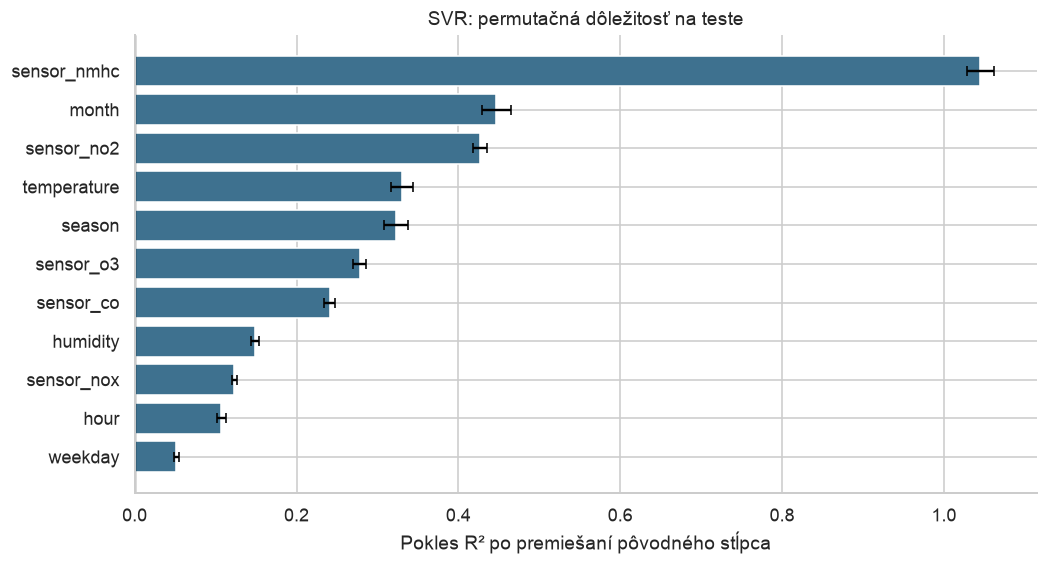

In [126]:
permutation_SVR = show_permutation_importance("SVR")

Po premiešaní **sensor_nmhc** klesne testovacie R² modelu **SVR** v priemere o **1.0451 ± 0.0166**. Táto hodnota je rozdiel R², nie percento. Chybové úsečky opisujú päť náhodných premiešaní pri nezmenenom modeli. Korelované vstupy môžu časť informácie navzájom nahrádzať; testový rebríček nepoužívam na výber príznakov.

## Porovnanie reziduálov

Najskôr porovnám finálne metriky a CV diagnostiku, potom samotné chyby jednotlivých meraní. Všetky modely predikujú rovnakých 1 469 testovacích meraní.

MSE            RMSE              R²        
Množina                 Test Tréning    Test Tréning    Test Tréning
Model                                                               
DecisionTree          0.2007  0.1404  0.4480  0.3747  0.9031  0.9319
ExtraTrees            0.1216  0.0000  0.3486  0.0035  0.9413  1.0000
HistGradientBoosting  0.1210  0.0488  0.3478  0.2208  0.9416  0.9763
RandomForest          0.1402  0.0190  0.3744  0.1380  0.9323  0.9908
SVR                   0.0947  0.0350  0.3077  0.1870  0.9543  0.9830
XGBoost               0.1204  0.0429  0.3470  0.2072  0.9419  0.9792

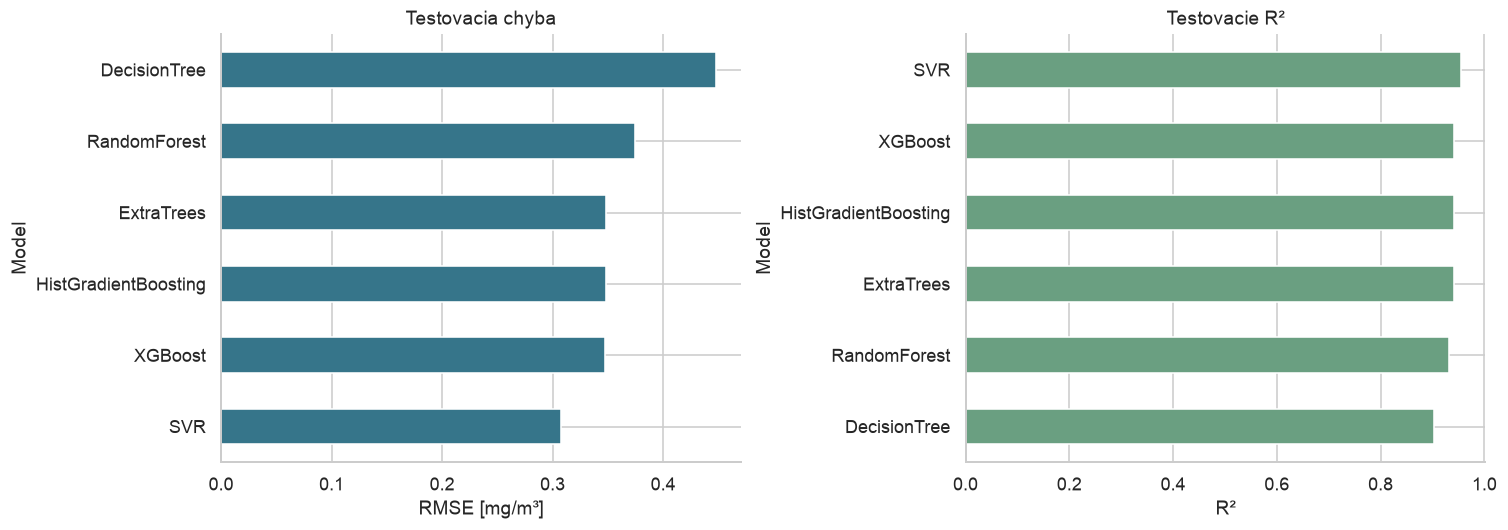

In [127]:
metrics = pd.DataFrame(metric_rows)
metric_table = metrics.pivot(index="Model", columns="Množina", values=["MSE", "RMSE", "R²"])
display(metric_table.round(4))
test_metrics = metrics[metrics.Množina.eq("Test")].set_index("Model")
fig, axes = plt.subplots(1, 2, figsize=(13,4.5), constrained_layout=True)
test_metrics.RMSE.sort_values().plot.barh(ax=axes[0], color="#36758a")
axes[0].set(title="Testovacia chyba", xlabel="RMSE [mg/m³]")
test_metrics["R²"].sort_values().plot.barh(ax=axes[1], color="#6a9f81")
axes[1].set(title="Testovacie R²", xlabel="R²")
plt.show()

CV víťaz **SVR** dosiahol na teste **$R^2 = 0.9543$**, $\mathrm{RMSE} = \boldsymbol{0.3077\,\mathrm{mg}/\mathrm{m}^3}$. Opisne najnižšiu testovaciu MSE má SVR. Týmto údajom výber nemením. Stĺpce ukazujú porovnanie na totožných riadkoch. Menšie RMSE a vyššie $R^2$ znamenajú lepší výsledok.

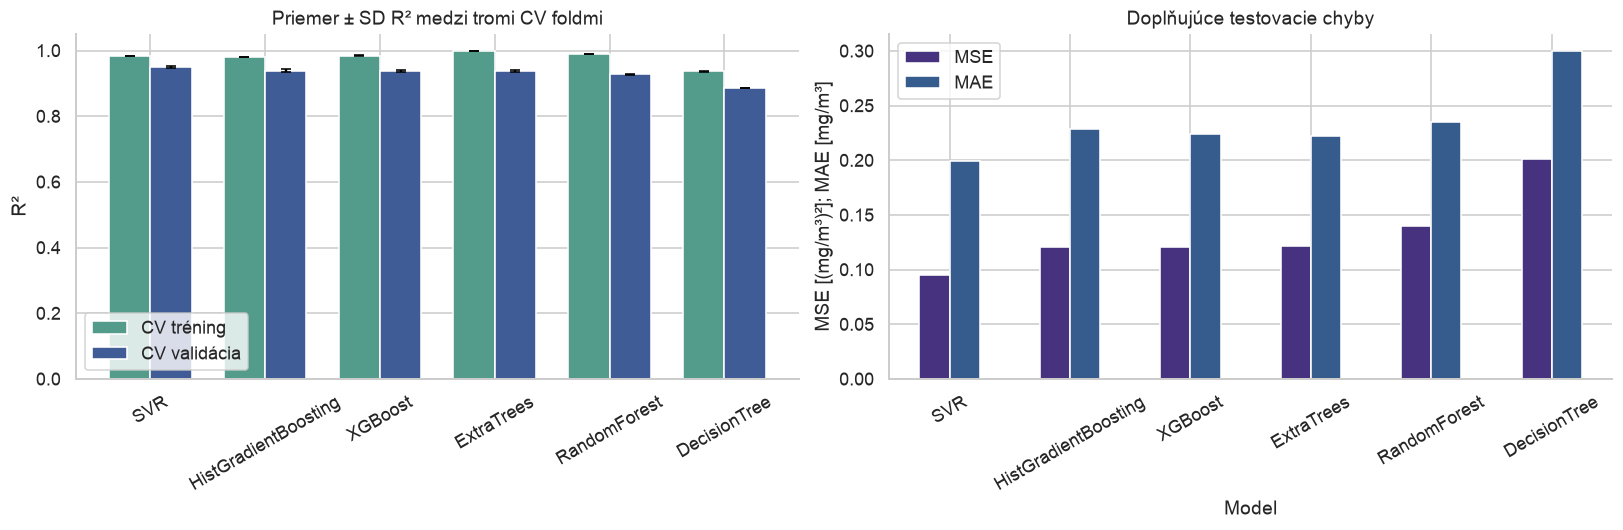

,CV tréning R²,CV tréning SD R²,CV R²,CV SD R²,CV MSE,CV RMSE
Model,,,,,,
SVR,0.9843,0.0006,0.9492,0.0028,0.1046,0.3234
HistGradientBoosting,0.9805,0.0010,0.9388,0.0046,0.1256,0.3544
XGBoost,0.9846,0.0009,0.9376,0.0040,0.1284,0.3583
ExtraTrees,1.0000,0.0000,0.9370,0.0034,0.1297,0.3602
RandomForest,0.9898,0.0004,0.9272,0.0022,0.1499,0.3872
DecisionTree,0.9364,0.0016,0.8860,0.0012,0.2346,0.4843


In [128]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
comparison_order = cv_results.index.tolist()
positions = np.arange(len(comparison_order))
for offset, column, sd_column, label, color in [
    (-.18, 'CV tréning R²', 'CV tréning SD R²', 'CV tréning', '#539b8a'),
    (.18, 'CV R²', 'CV SD R²', 'CV validácia', '#3f5c96')]:
    axes[0].bar(positions+offset, cv_results.loc[comparison_order, column], width=.36,
                yerr=cv_results.loc[comparison_order, sd_column], capsize=3, label=label, color=color)
axes[0].set(title='Priemer ± SD R² medzi tromi CV foldmi', ylabel='R²', xticks=positions, xticklabels=comparison_order)
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend()
test_metrics.loc[comparison_order, ['MSE', 'MAE']].plot.bar(ax=axes[1])
axes[1].set(title='Doplňujúce testovacie chyby', ylabel='MSE [(mg/m³)²]; MAE [mg/m³]', xlabel='Model')
axes[1].tick_params(axis='x', rotation=30)
plt.show()
display(cv_results[['CV tréning R²', 'CV tréning SD R²', 'CV R²', 'CV SD R²', 'CV MSE', 'CV RMSE']].round(4))

CV rozdiel medzi tréningom a validáciou ukazuje prispôsobenie modelu tréningovým foldom. Chybové úsečky opisujú iba tri konkrétne foldy. MSE a MAE majú rôzne jednotky; pri porovnaní modelov sledujem každú metriku samostatne.

### Citlivosť na ladené hyperparametre

Heatmapy zobrazujú CV RMSE. Nezobrazené hyperparametre sú fixované na hodnotách víťaznej konfigurácie daného modelu; jednotlivé bunky preto nevyberajú zakaždým iné skryté nastavenie.

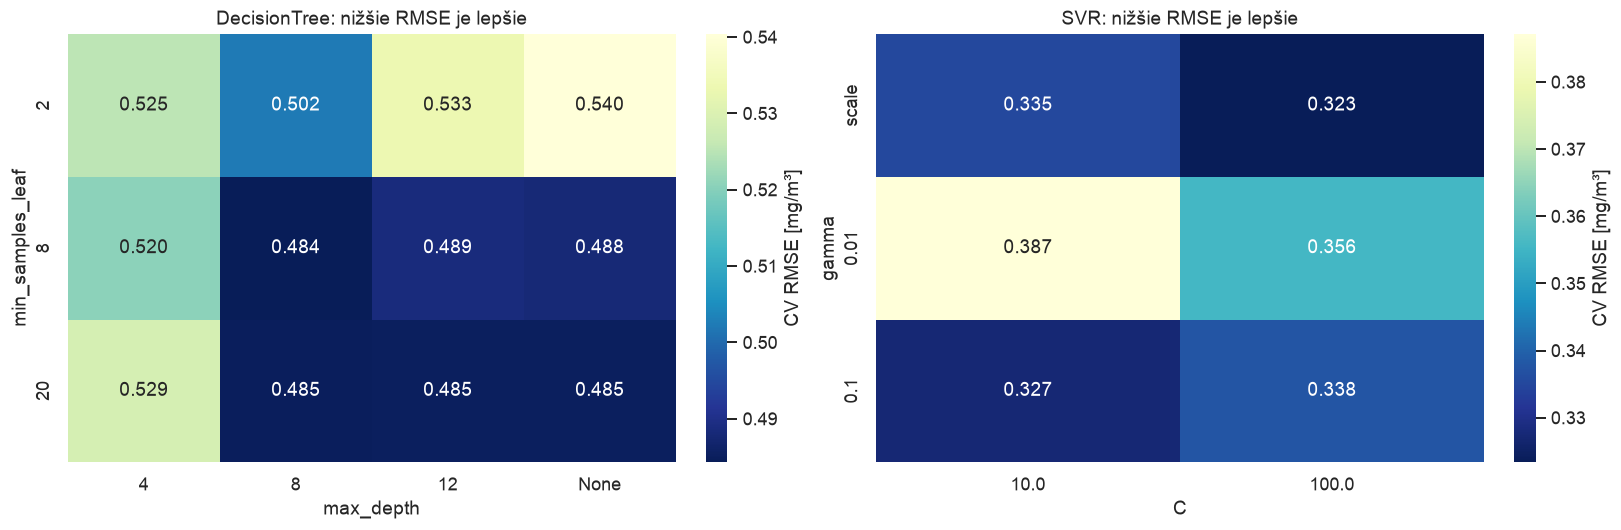

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for ax, name, xparam, yparam in [
    (axes[0], 'DecisionTree', 'max_depth', 'min_samples_leaf'),
    (axes[1], 'SVR', 'C', 'gamma')]:
    search = searches[name]
    heat_rows = []
    for params, score in zip(search.cv_results_['params'], search.cv_results_['mean_test_mse']):
        if all(value == search.best_params_[key] for key, value in params.items()
               if key not in [f'estimator__model__{xparam}', f'estimator__model__{yparam}']):
            heat_rows.append({xparam: str(params[f'estimator__model__{xparam}']),
                              yparam: str(params[f'estimator__model__{yparam}']), 'CV RMSE': np.sqrt(-score)})
    matrix = pd.DataFrame(heat_rows).pivot(index=yparam, columns=xparam, values='CV RMSE')
    xorder = [str(value) for value in model_configs[name][1][xparam]]
    yorder = [str(value) for value in model_configs[name][1][yparam]]
    sns.heatmap(matrix.reindex(index=yorder, columns=xorder), annot=True, fmt='.3f', cmap='YlGnBu_r', ax=ax, cbar_kws={'label': 'CV RMSE [mg/m³]'})
    ax.set_title(f'{name}: nižšie RMSE je lepšie')
plt.show()

Najlepší strom podľa CV má hĺbku **8** a aspoň **8** vzoriek v liste. SVR vybral **C=100.0**, **gamma=scale**, **epsilon=0.1**. Rozdiely farieb ukazujú citlivosť na parametre pri fixovaných ostatných nastaveniach. Tieto grafy používajú iba CV výsledky, nie testovú chybu.

### Reziduál oproti predikcii a rozdelenie chýb

Na zvislej osi bodových grafov je **reziduál** (skutočná hodnota - predikovaná hodnota), nie očakávaná koncentrácia. Ideálne body tvoria pás okolo nuly bez krivky či lievika. Histogram porovnáva chyby v tréningu a teste. Všetky modely kreslím s rovnakou mierkou reziduálov, aby porovnanie neskreslili osi.

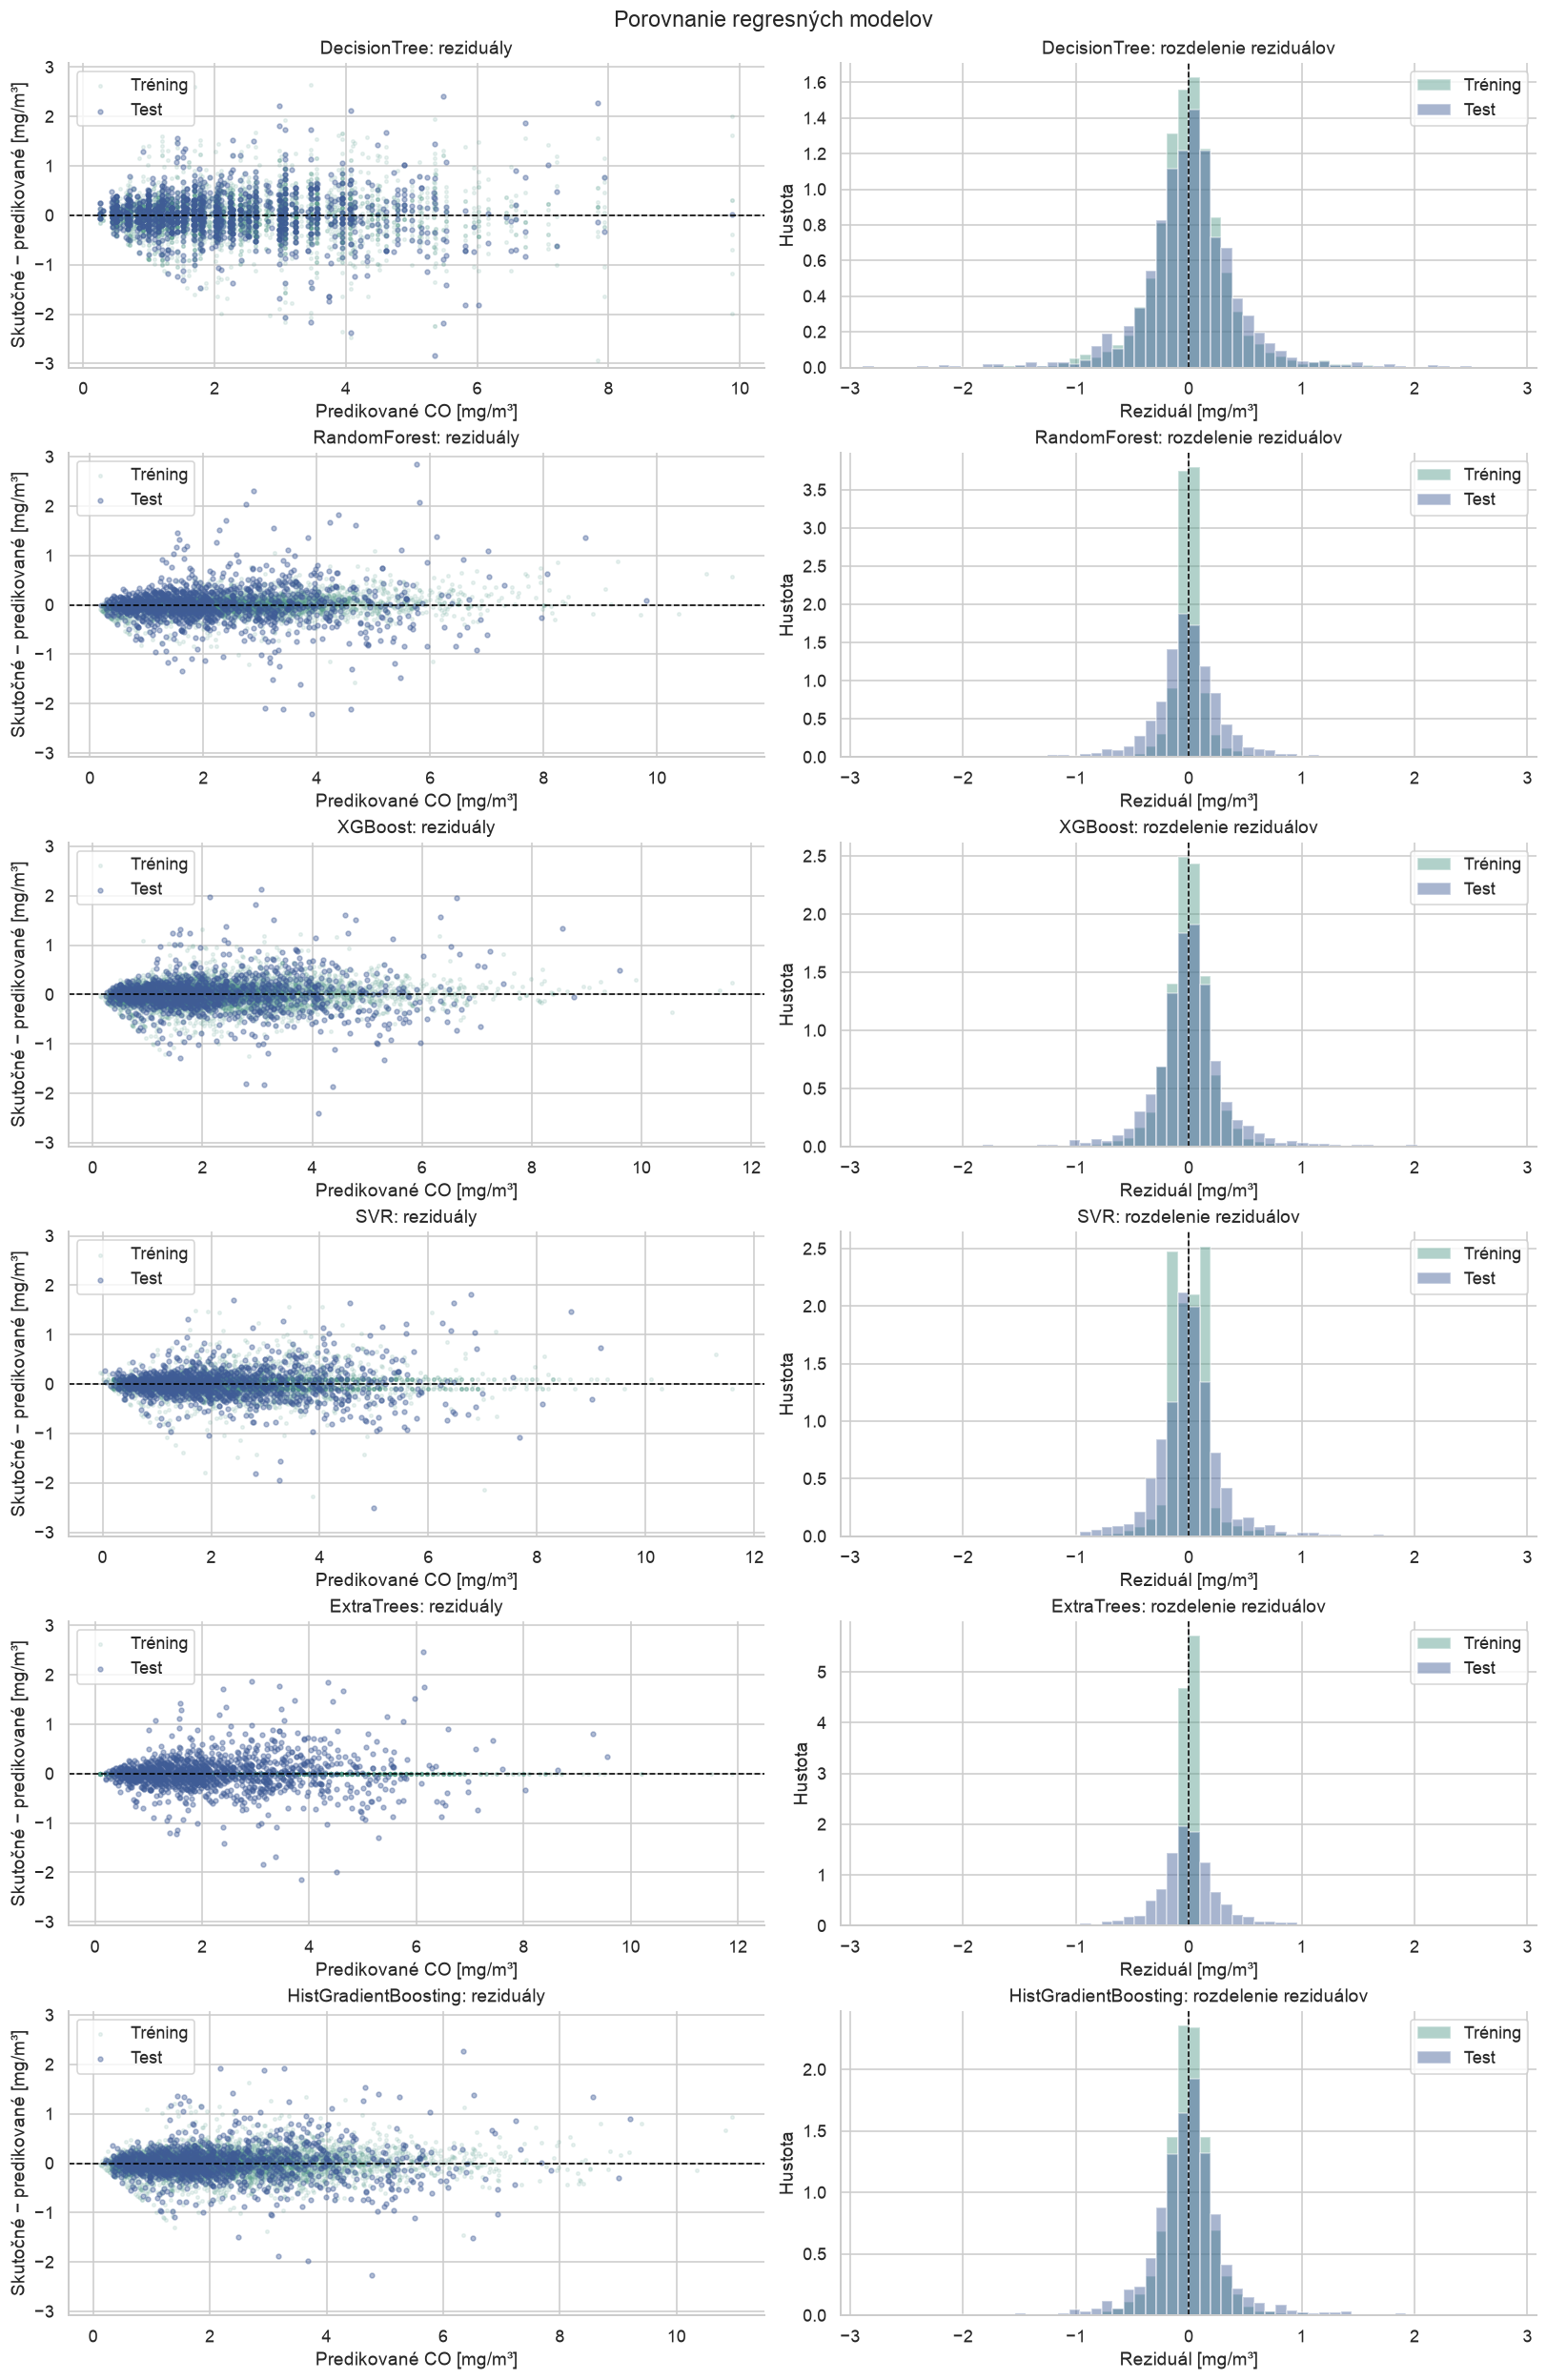

,Priemer reziduála,Medián reziduála,95. percentil |e|,Korelácia |e| a predikcie
Model,,,,
DecisionTree,0.0116,0.0125,0.8701,0.3486
RandomForest,0.0048,-0.0060,0.7453,0.3463
XGBoost,0.0059,0.0022,0.7190,0.3496
SVR,0.0019,-0.0040,0.6502,0.4270
ExtraTrees,0.0026,-0.0115,0.7079,0.3557
HistGradientBoosting,0.0033,0.0028,0.7279,0.3460


In [130]:
def residual_summary(name, y, prediction):
    e = np.asarray(y) - np.asarray(prediction)
    return {"Model": name, "Priemer reziduála": float(e.mean()),
            "Medián reziduála": float(np.median(e)), "95. percentil |e|": float(np.quantile(np.abs(e), .95)),
            "Korelácia |e| a predikcie": float(np.corrcoef(np.abs(e), prediction)[0,1])}

def plot_residuals(models, title):
    fig, axes = plt.subplots(len(models), 2, figsize=(14,3.6*len(models)), squeeze=False, constrained_layout=True)
    limit = max(np.max(np.abs(np.asarray(y)-model.predict(X))) for model in models.values() for X,y in [(X_train,y_train),(X_test,y_test)])*1.05
    summaries=[]
    for row,(name,model) in enumerate(models.items()):
        train_pred, test_pred = model.predict(X_train), model.predict(X_test)
        train_e, test_e = np.asarray(y_train)-train_pred, np.asarray(y_test)-test_pred
        axes[row,0].scatter(train_pred,train_e,s=5,alpha=.12,label="Tréning",color="#539b8a")
        axes[row,0].scatter(test_pred,test_e,s=9,alpha=.4,label="Test",color="#3f5c96")
        axes[row,0].axhline(0,color="black",linestyle="--",linewidth=1)
        axes[row,0].set(title=name+": reziduály",xlabel="Predikované CO [mg/m³]",ylabel="Skutočné − predikované [mg/m³]",ylim=(-limit,limit))
        axes[row,0].legend(loc="upper left")
        for e,label,color in [(train_e,"Tréning","#539b8a"),(test_e,"Test","#3f5c96")]:
            axes[row,1].hist(e,bins=np.linspace(-limit,limit,65),density=True,alpha=.45,label=label,color=color)
        axes[row,1].axvline(0,color="black",linestyle="--",linewidth=1)
        axes[row,1].set(title=name+": rozdelenie reziduálov",xlabel="Reziduál [mg/m³]",ylabel="Hustota",xlim=(-limit,limit))
        axes[row,1].legend()
        summaries.append(residual_summary(name,y_test,test_pred))
    fig.suptitle(title)
    plt.show()
    table=pd.DataFrame(summaries).set_index("Model")
    display(table.round(4))
    return table

residual_table = plot_residuals(trained_models,"Porovnanie regresných modelov")


**DecisionTree:** priemerný testovací reziduál 0.0116 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.870 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.349. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**RandomForest:** priemerný testovací reziduál 0.0048 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.745 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.346. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**XGBoost:** priemerný testovací reziduál 0.0059 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.719 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.350. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**SVR:** priemerný testovací reziduál 0.0019 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.650 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.427. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**ExtraTrees:** priemerný testovací reziduál 0.0026 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.708 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.356. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**HistGradientBoosting:** priemerný testovací reziduál 0.0033 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.728 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.346. Chyby majú tendenciu rásť s predikovanou koncentráciou.

### Rozptyl reziduálov a chyby podľa skutočného CO

Boxplot porovná rozdelenia testovacích reziduálov. Pásma CO určím podľa tréningových kvartilov; testové merania ich nemenia. Pri každom pásme uvediem počet testovacích bodov.

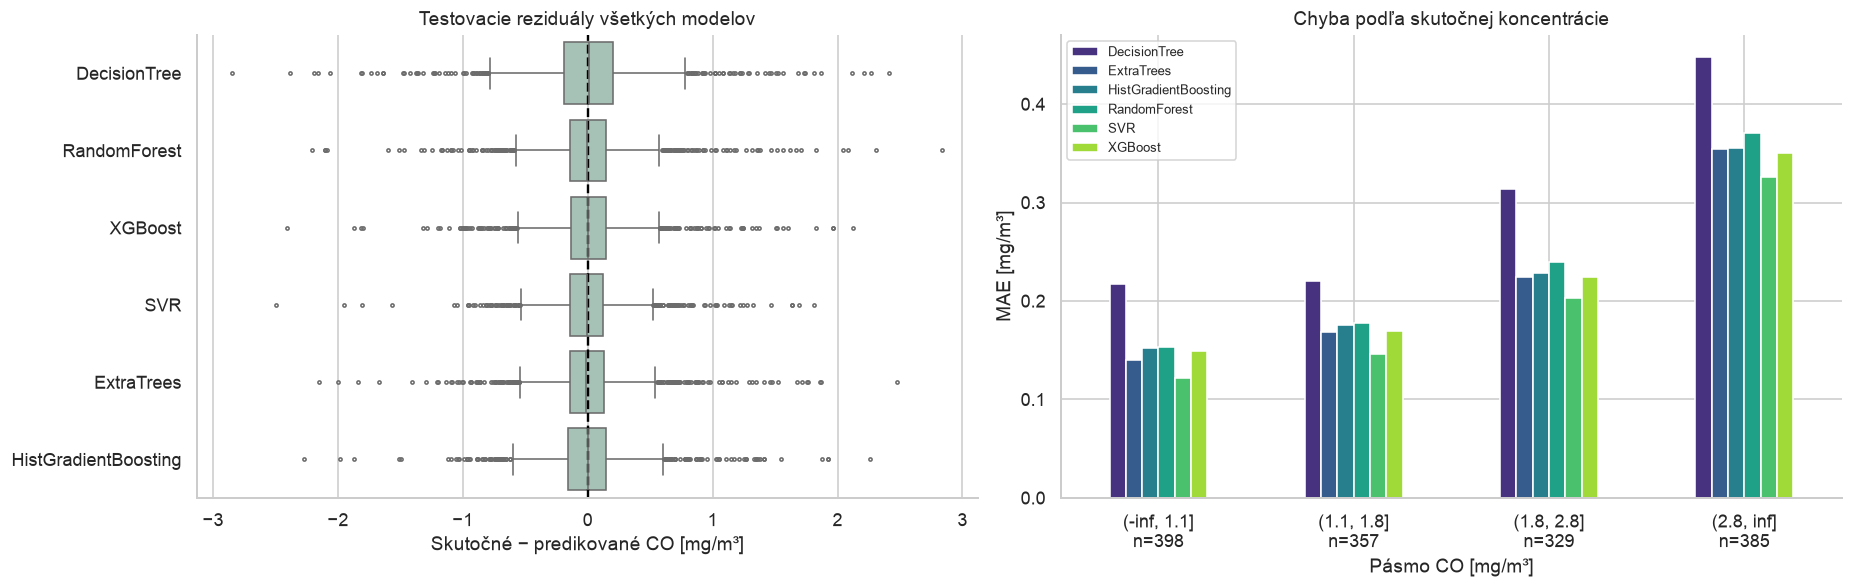

,Model,Pásmo CO,n,MAE,RMSE,Priemer reziduála
0,DecisionTree,"(-inf, 1.1]",398,0.2175,0.3342,-0.1161
1,DecisionTree,"(1.1, 1.8]",357,0.2205,0.3299,-0.0183
2,DecisionTree,"(1.8, 2.8]",329,0.3143,0.4467,0.0209
3,DecisionTree,"(2.8, inf]",385,0.4482,0.6156,0.1633
4,RandomForest,"(-inf, 1.1]",398,0.1537,0.2635,-0.0981
5,RandomForest,"(1.1, 1.8]",357,0.1773,0.2728,-0.0354
6,RandomForest,"(1.8, 2.8]",329,0.2395,0.3538,0.0143
7,RandomForest,"(2.8, inf]",385,0.3703,0.5357,0.1404
8,XGBoost,"(-inf, 1.1]",398,0.1495,0.2479,-0.0837
9,XGBoost,"(1.1, 1.8]",357,0.1698,0.2619,-0.0314


In [131]:
residual_long = pd.concat([
    pd.DataFrame({'Model': name, 'Reziduál': np.asarray(y_test)-model.predict(X_test)})
    for name, model in trained_models.items()], ignore_index=True)
co_edges = np.r_[-np.inf, np.unique(y_train.quantile([.25, .5, .75]).to_numpy()), np.inf]
co_bands = pd.cut(y_test, bins=co_edges)
band_rows = []
for name, model in trained_models.items():
    values = pd.DataFrame({'Pásmo CO': co_bands.astype(str).to_numpy(), 'Reziduál': np.asarray(y_test)-model.predict(X_test)})
    for band in co_bands.cat.categories:
        errors = values.loc[values['Pásmo CO'].eq(str(band)), 'Reziduál']
        band_rows.append({'Model': name, 'Pásmo CO': str(band), 'n': len(errors),
                          'MAE': errors.abs().mean(), 'RMSE': np.sqrt(np.mean(errors**2)), 'Priemer reziduála': errors.mean()})
band_metrics = pd.DataFrame(band_rows)
band_order = [str(band) for band in co_bands.cat.categories]
mae_bands = band_metrics.pivot(index='Pásmo CO', columns='Model', values='MAE').reindex(band_order)
band_counts = band_metrics.drop_duplicates('Pásmo CO').set_index('Pásmo CO').loc[band_order, 'n']
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
sns.boxplot(data=residual_long, y='Model', x='Reziduál', color='#a1c6b7', fliersize=2, ax=axes[0])
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set(title='Testovacie reziduály všetkých modelov', xlabel='Skutočné − predikované CO [mg/m³]', ylabel='')
mae_bands.plot.bar(ax=axes[1])
axes[1].set(title='Chyba podľa skutočnej koncentrácie', xlabel='Pásmo CO [mg/m³]', ylabel='MAE [mg/m³]')
axes[1].set_xticklabels([f'{band}\nn={band_counts.loc[band]}' for band in band_order], rotation=0)
axes[1].legend(fontsize=8)
plt.show()
display(band_metrics.round(4))


Pri modeli **SVR** je MAE v najnižšom pásme CO **0.1216 mg/m³**, v najvyššom **0.3256 mg/m³**. Najvyššie pásmo obsahuje **385** testovacích meraní a jeho priemerný reziduál je **0.0716 mg/m³**. Boxplot dopĺňa súhrnné metriky: posun mediánu ukazuje systematickú chybu, široký box a dlhé fúzy väčšie rozptýlenie reziduálov. Extrémne body ostávajú súčasťou hodnotenia.

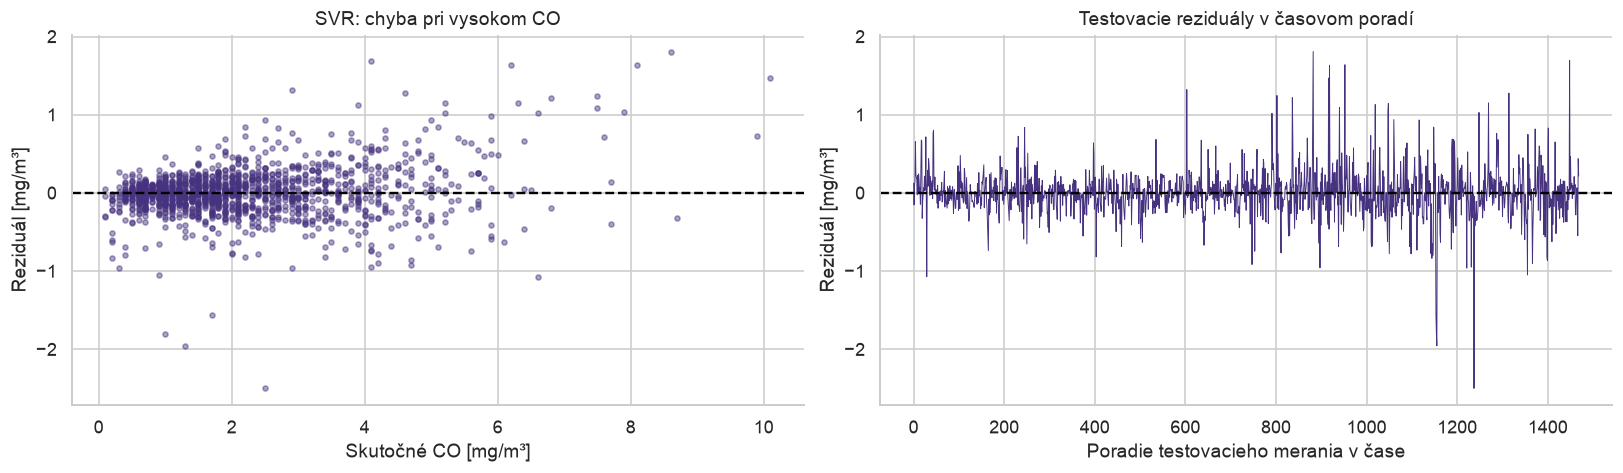

In [132]:
# Dodatočne kontrolujem skreslenie pri vysokom skutočnom CO a časové usporiadanie testu.
best_test_pred = best_model.predict(X_test)
best_test_residual = np.asarray(y_test)-best_test_pred
high_threshold = float(y_train.quantile(.90))
high = y_test.to_numpy() >= high_threshold
order = np.argsort(pd.to_datetime(test_data.date).to_numpy()+pd.to_timedelta(test_data.hour,unit="h").to_numpy())
fig,axes=plt.subplots(1,2,figsize=(14,4),constrained_layout=True)
axes[0].scatter(y_test,best_test_residual,s=10,alpha=.45)
axes[0].axhline(0,color="black",linestyle="--")
axes[0].set(title=f"{BEST_NAME}: chyba pri vysokom CO",xlabel="Skutočné CO [mg/m³]",ylabel="Reziduál [mg/m³]")
axes[1].plot(np.arange(len(order)),best_test_residual[order],linewidth=.6)
axes[1].axhline(0,color="black",linestyle="--")
axes[1].set(title="Testovacie reziduály v časovom poradí",xlabel="Poradie testovacieho merania v čase",ylabel="Reziduál [mg/m³]")
plt.show()


Pri skutočnom CO aspoň **4.00 $\mathrm{mg}/\mathrm{m}^3$** (hranica z tréningu) je priemerný reziduál 0.137 $\mathrm{mg}/\mathrm{m}^3$ na 182 testovacích bodoch. Tým priamo kontrolujem podhodnocovanie vysokých koncentrácií. Časový graf ukazuje poradie vybraných testovacích hodín. Vzdialenosť bodov na osi nie je rovnaký časový odstup. Nulový priemer reziduálov sám nezaručuje, že sú chyby nezávislé alebo normálne rozdelené.

# Redukcia dimenzie

PCA vytvára nové osi ako lineárne kombinácie vstupov. PC1 zachytáva najväčší rozptyl, ďalšie kolmé osi zachytávajú zostávajúcu variabilitu. PCA nepozná cieľ CO; maximalizuje rozptyl vstupov, nie kvalitu regresie. Pred jej učením vstupy štandardizujem, pretože samotná PCA ich iba centruje.

Nasledujúce dve podsekcie zodpovedajú dvom podúlohám zadania. Slovo `count` v PDF je pri tomto datasete potrebné čítať ako **`co`**. Prvé zobrazenie používa tri pôvodné senzory bez škálovania, druhé redukuje **všetkých 17 kódovaných a štandardizovaných vstupov** na tri nové osi. CO slúži iba na farbenie.

## Vykreslenie príznakov – vyčítanie závislostí

Vyberám `sensor_co`, `sensor_nmhc` a `sensor_nox`. Použijem rovnakú podvzorku najviac 2 500 tréningových inlierov a rovnakú farebnú škálu ako v nasledujúcej PCA projekcii. Boxploty používajú všetky tréningové inliery.

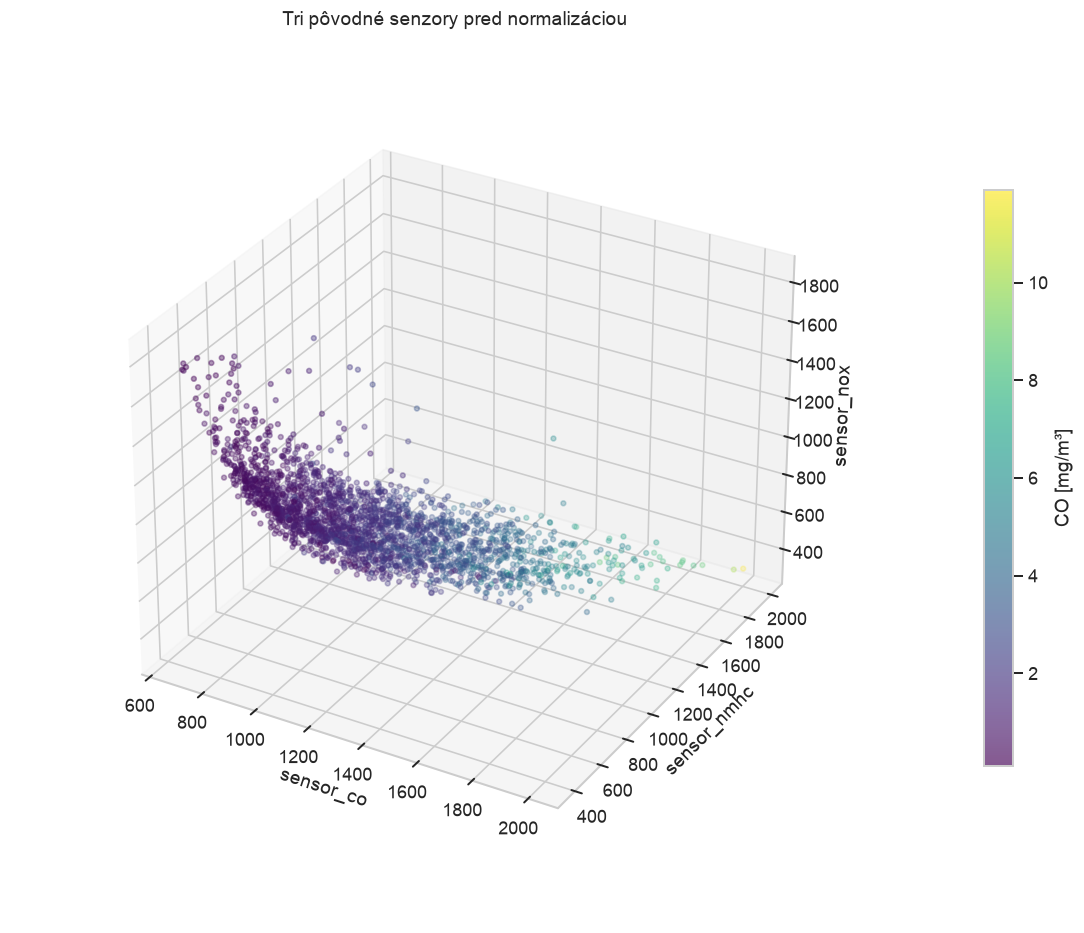

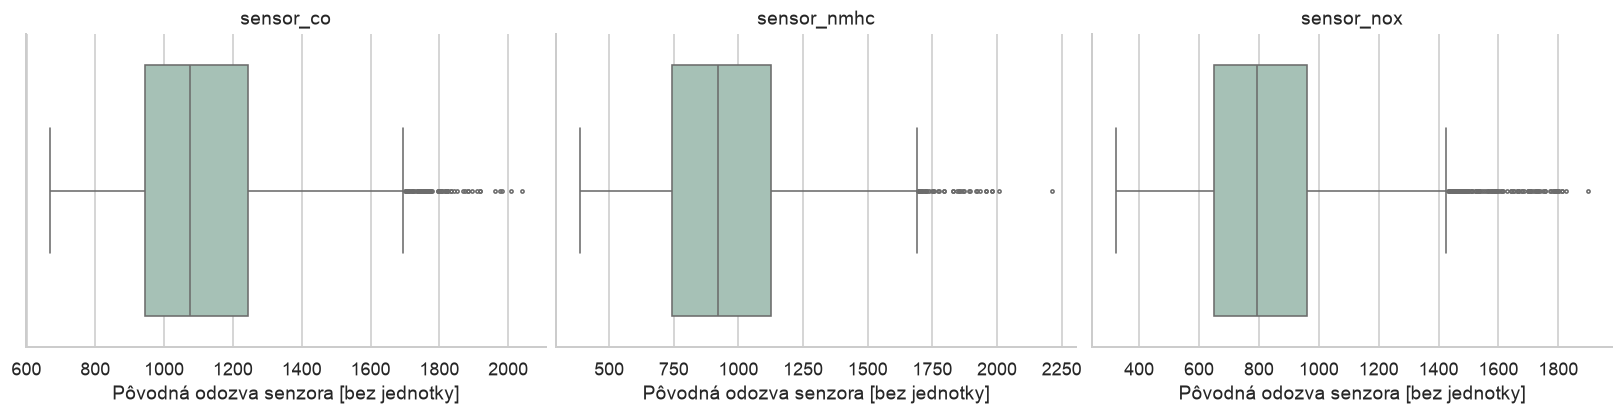

,mean,median,var,std,min,max,Q1,Q3,IQR
sensor_co,1110.731,1076.0,47817.785,218.673,667.0,2040.0,945.0,1245.0,300.0
sensor_nmhc,947.448,920.5,70179.451,264.914,387.0,2214.0,744.0,1124.0,380.0
sensor_nox,823.791,795.0,59793.983,244.528,322.0,1900.0,650.0,961.0,311.0


In [133]:
raw_features = ['sensor_co', 'sensor_nmhc', 'sensor_nox']
rng = np.random.default_rng(SEED)
show_idx = np.sort(rng.choice(len(X_train_in), size=min(2500, len(X_train_in)), replace=False))
shown_co = y_train_in.iloc[show_idx].to_numpy()
norm = plt.Normalize(float(y_train_in.min()), float(y_train_in.max()))
fig = plt.figure(figsize=(11, 8), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(*X_train_in.iloc[show_idx][raw_features].to_numpy().T,
                c=shown_co, cmap='viridis', norm=norm, s=9, alpha=.65)
ax.set(xlabel='sensor_co', ylabel='sensor_nmhc', zlabel='sensor_nox', title='Tri pôvodné senzory pred normalizáciou')
ax.set_box_aspect((1, 1, .8), zoom=.85)
fig.colorbar(sc, ax=ax, label='CO [mg/m³]', shrink=.65, pad=.08)
plt.show()
raw_box_stats = X_train_in[raw_features].agg(['mean', 'median', 'var', 'std', 'min', 'max']).T
raw_box_stats['Q1'] = X_train_in[raw_features].quantile(.25)
raw_box_stats['Q3'] = X_train_in[raw_features].quantile(.75)
raw_box_stats['IQR'] = raw_box_stats.Q3-raw_box_stats.Q1
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
for ax, feature in zip(axes, raw_features):
    sns.boxplot(x=X_train_in[feature], ax=ax, color='#a1c6b7', fliersize=2)
    ax.set(title=feature, xlabel='Pôvodná odozva senzora [bez jednotky]')
plt.show()
display(raw_box_stats.round(3))
raw_co_correlations = X_train_in[raw_features].corrwith(y_train_in)

Pearsonove korelácie pôvodných osí s CO na tréningových inlieroch sú **sensor_co: 0.880**, **sensor_nmhc: 0.915**, **sensor_nox: -0.723**. Farebný prechod umožňuje čítať spoločnú závislosť troch senzorov od CO. Boxploty a tabuľka odlišujú typické hodnoty od chvostov; rozdielna číselná mierka senzorov sama neznamená rozdielnu predikčnú dôležitosť.

## Minimalizácia na 3 dimenzie

Kódovanie, štandardizáciu a PCA učím iba na tréningových inlieroch. Transformácia prevádza 17 vstupných stĺpcov na PC1, PC2 a PC3. Rovnaké parametre následne transformujú test; cieľ sa do PCA nedostane.

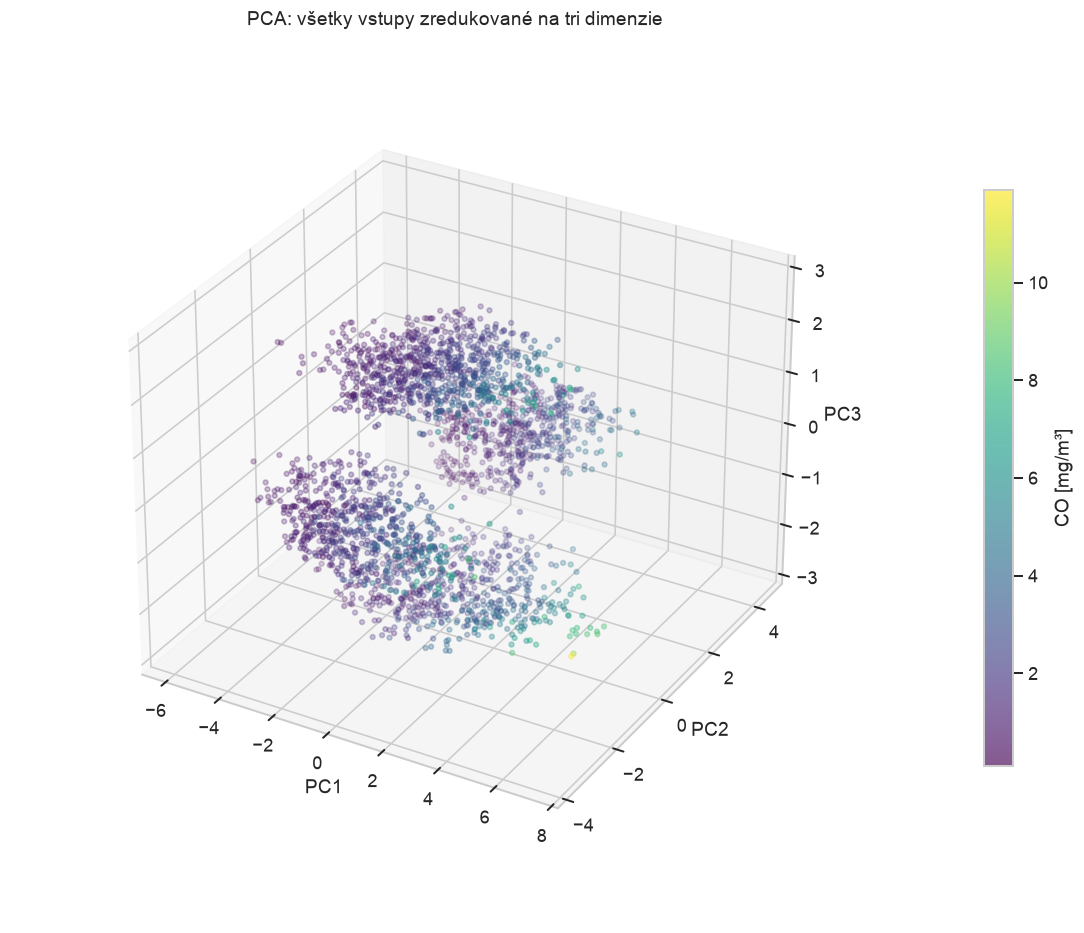

,PC1,PC2,PC3
sensor_nmhc,0.456,0.073,0.034
sensor_co,0.416,0.193,0.133
sensor_o3,0.405,0.214,0.032
sensor_no2,0.401,0.170,0.047
sensor_nox,0.396,0.153,0.031
temperature,0.184,0.455,0.069
hour_sin,0.179,0.044,0.075
weekday_cos,0.137,0.043,0.050


In [134]:
projection_pipeline = Pipeline([
    ('calendar', CalendarEncoder()), ('preprocessing', clone(preprocessor)), ('scale', StandardScaler())])
Z_train = projection_pipeline.fit_transform(X_train_in)
Z_test = projection_pipeline.transform(X_test)
pca3 = PCA(n_components=3, svd_solver='full').fit(Z_train)
coords3 = pca3.transform(Z_train)
fig = plt.figure(figsize=(11, 8), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(*coords3[show_idx].T, c=shown_co, cmap='viridis', norm=norm, s=9, alpha=.65)
ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3', title='PCA: všetky vstupy zredukované na tri dimenzie')
ax.set_box_aspect((1, 1, .8), zoom=.85)
fig.colorbar(sc, ax=ax, label='CO [mg/m³]', shrink=.65, pad=.08)
plt.show()
loadings = pd.DataFrame(pca3.components_.T, index=encoded_names, columns=['PC1', 'PC2', 'PC3'])
display(loadings.abs().sort_values('PC1', ascending=False).head(8).round(3))
pc_co_corr = [np.corrcoef(coords3[:, i], y_train_in)[0, 1] for i in range(3)]

Tri komponenty zachovávajú **60.2% vstupnej variability** (jednotlivo 26.0%, 20.4%, 13.8%). Korelácie PC1, PC2 a PC3 s CO sú 0.848, -0.310, 0.068. V pôvodnom grafe sú vyššie koncentrácie sústredené pri vyšších odozvách sensor_co a sensor_nmhc a pri nižších odozvách sensor_nox. Farebný prechod teda odhaľuje súvislosť viacerých senzorov s CO. V PCA sa hlavný farebný gradient orientuje najmä pozdĺž PC1, čo podporuje aj jeho korelácia s CO. Dva výškové pásy v projekcii nie sú dvoma cieľovými triedami: v oboch sa vyskytujú rôzne koncentrácie. PCA mieša senzory aj časové premenné, preto jej osi nemajú priamu fyzikálnu jednotku. Farebný prechod je indíciou súvislosti s CO, nie dôkazom dokonalej predikovateľnosti. PCA maximalizuje variabilitu vstupov, nie vzťah s cieľom. Znamienko komponentu je ľubovoľné a môže sa otočiť bez zmeny jeho významu.

### Rozloženie hodnôt pred PCA a po PCA

Boxplot zobrazuje medián, kvartily a odľahlé hodnoty, nie priamo číselný rozptyl. Preto pridávam aj tabuľku výberového rozptylu, štandardnej odchýlky a IQR. Surové senzory a komponenty majú odlišné mierky; ich šírky nemožno priamo porovnávať. Komponenty dodatočne neškálujem, aby rozdiel ich rozptylov zostal viditeľný.

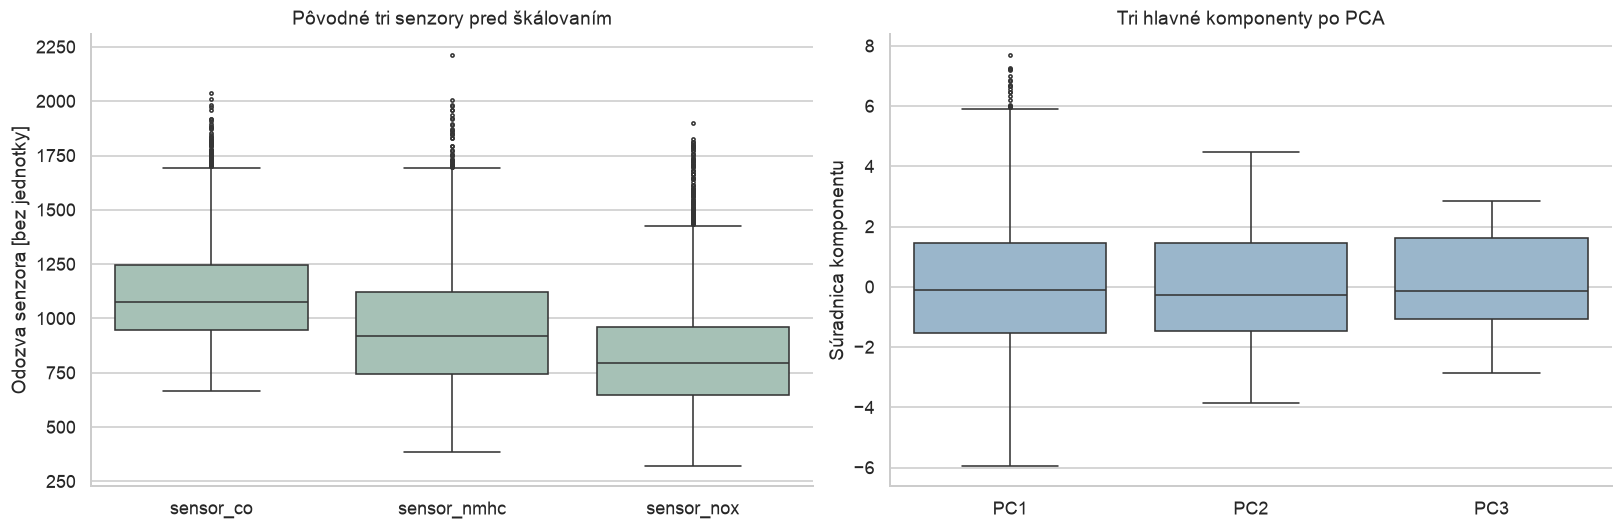

,mean,median,var,std,min,max,Q1,Q3,IQR
PC1,0.0,-0.0904,4.4218,2.1028,-5.9379,7.7072,-1.5381,1.4511,2.9892
PC2,-0.0,-0.2603,3.4725,1.8635,-3.8580,4.4762,-1.4541,1.4693,2.9234
PC3,0.0,-0.1472,2.3449,1.5313,-2.8489,2.8580,-1.0541,1.6397,2.6938


In [135]:
pc_frame = pd.DataFrame(coords3, columns=['PC1', 'PC2', 'PC3'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
sns.boxplot(data=X_train_in[raw_features], ax=axes[0], color='#a1c6b7', fliersize=2)
axes[0].set(title='Pôvodné tri senzory pred škálovaním', ylabel='Odozva senzora [bez jednotky]')
sns.boxplot(data=pc_frame, ax=axes[1], color='#92b7d3', fliersize=2)
axes[1].set(title='Tri hlavné komponenty po PCA', ylabel='Súradnica komponentu')
plt.show()
pca_box_stats = pc_frame.agg(['mean', 'median', 'var', 'std', 'min', 'max']).T
pca_box_stats['Q1'], pca_box_stats['Q3'] = pc_frame.quantile(.25), pc_frame.quantile(.75)
pca_box_stats['IQR'] = pca_box_stats.Q3-pca_box_stats.Q1
display(pca_box_stats.round(4))
assert np.allclose(pca_box_stats['var'], pca3.explained_variance_)

Výberové rozptyly PC1, PC2 a PC3 sú **4.4218**, **3.4725**, **2.3449**. Ich IQR sú **2.9892**, **2.9234**, **2.6938**. Klesajúci rozptyl zodpovedá poradiu hlavných komponentov; šírka boxu závisí od kvartilov a nemusí kopírovať rozptyl pri chvostoch či viacerých skupinách. Rozptyly sa numericky zhodujú s explained_variance_ PCA. So surovými senzormi ich nemožno porovnávať v rovnakej mierke.

### Čo je rozptyl a koľko ho PCA zachová

Rozptyl vyjadruje, ako ďaleko sa hodnoty nachádzajú od svojho priemeru. Pri viacerých vstupoch sledujem súčet ich rozptylov, teda celkovú variabilitu dátového oblaku. Po štandardizácii má každý vstup približne jednotkový rozptyl: senzor s veľkými číslami preto neovládne PCA len kvôli svojej mierke. Korelácie však štandardizácia neodstráni.

PCA vytvára nové osi ako lineárne kombinácie vstupov. PC1 má najväčší možný rozptyl, PC2 je na ňu kolmá a zachytáva najviac zo zostávajúcej variability. Ďalšie komponenty pokračujú rovnakým spôsobom. Pri ponechaní všetkých komponentov ide iba o otočenie súradníc, ktoré celkový rozptyl zachová. Strata vzniká až zahodením niektorých smerov. Intuíciu projekcie rozvíja [mlcourse.ai: PCA a zhlukovanie](https://mlcourse.ai/book/topic07/topic7_pca_clustering.html).

#### Vysvetlený a kumulatívny rozptyl

Vlastné číslo $\lambda_j$ kovariančnej matice je rozptyl súradníc v smere komponentu. Jeho pomer k súčtu všetkých vlastných čísel dáva `explained_variance_ratio_`. Kumulatívny súčet určí počet komponentov pre zvolenú hranicu:

$$
\begin{aligned}
\operatorname{Var}(x) &= \frac{\sum_i (x_i - \bar{x})^2}{n - 1} \\
\text{Celkový rozptyl} &= \sum_j \operatorname{Var}(z_j) = \sum_j \lambda_j \\
\mathrm{EVR}_j &= \frac{\lambda_j}{\sum_l \lambda_l} \\
C_m &= \sum_{j=1}^{m} \mathrm{EVR}_j \\
\text{Stratený podiel rozptylu} &= 1 - C_m
\end{aligned}
$$

`explained_variance_` obsahuje samotné rozptyly, `explained_variance_ratio_` ich podiely. PCA údaje centruje, ale automaticky neštandardizuje. Škálovanie preto predchádza PCA v našej pipeline. Percentá sú podielom variability **17 vstupných stĺpcov po kódovaní a škálovaní**, nie rozptylu CO. [Dokumentácia parametrov a atribútov PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

Ľavý graf nižšie ukazuje, koľko variability nesie každý komponent samostatne. Pravý ukazuje, ako sa podiely sčítavajú. Tri komponenty sú kompromis pre kreslenie v 3D. Nemusia zachytiť dostatok informácie na predikciu. Prahy 90 %, 95 % a 99 % naopak nechávajú počet komponentov vyplynúť z dát.

#### Rekonštrukcia: čo sa zahodením smerov stratí

Zo zredukovaných súradníc viem dáta premietnuť späť do pôvodného štandardizovaného priestoru. Chýbajúce smery tým neobnovím: body sa rekonštruujú v ponechanej podrovine. Pri ortogonálnej PCA bez whitening na tréningových dátach platí:

$$
\begin{aligned}
\mathrm{TSS} &= \sum_i \lVert z_i - \bar{z} \rVert^2 \\
\mathrm{SSE}_{\text{rekonštrukcie}} &= \sum_i \lVert z_i - \hat{z}_i \rVert^2 \\
\frac{\mathrm{SSE}_{\text{rekonštrukcie}}}{\mathrm{TSS}} &= 1 - C_m
\end{aligned}
$$

Túto rovnosť overím numericky. Rekonštrukčná RMSE má jednotku štandardizovaných vstupov. Nie je to regresná RMSE v $\mathrm{mg}/\mathrm{m}^3$. Nízka strata vstupnej variability nezaručuje malú chybu CO: aj málo variabilný smer môže niesť informáciu dôležitú pre cieľ.

,Komponent,Rozptyl λ,Podiel [%],Kumulatívne [%]
0,1,4.42182,26.00624,26.00624
1,2,3.47253,20.42318,46.42942
2,3,2.34488,13.79107,60.22049
3,4,1.47780,8.69143,68.91192
4,5,1.21682,7.15655,76.06846
5,6,1.02057,6.00231,82.07078
6,7,1.00572,5.91497,87.98575
7,8,0.88004,5.17584,93.16159
8,9,0.36569,2.15075,95.31234
9,10,0.27791,1.63446,96.94680


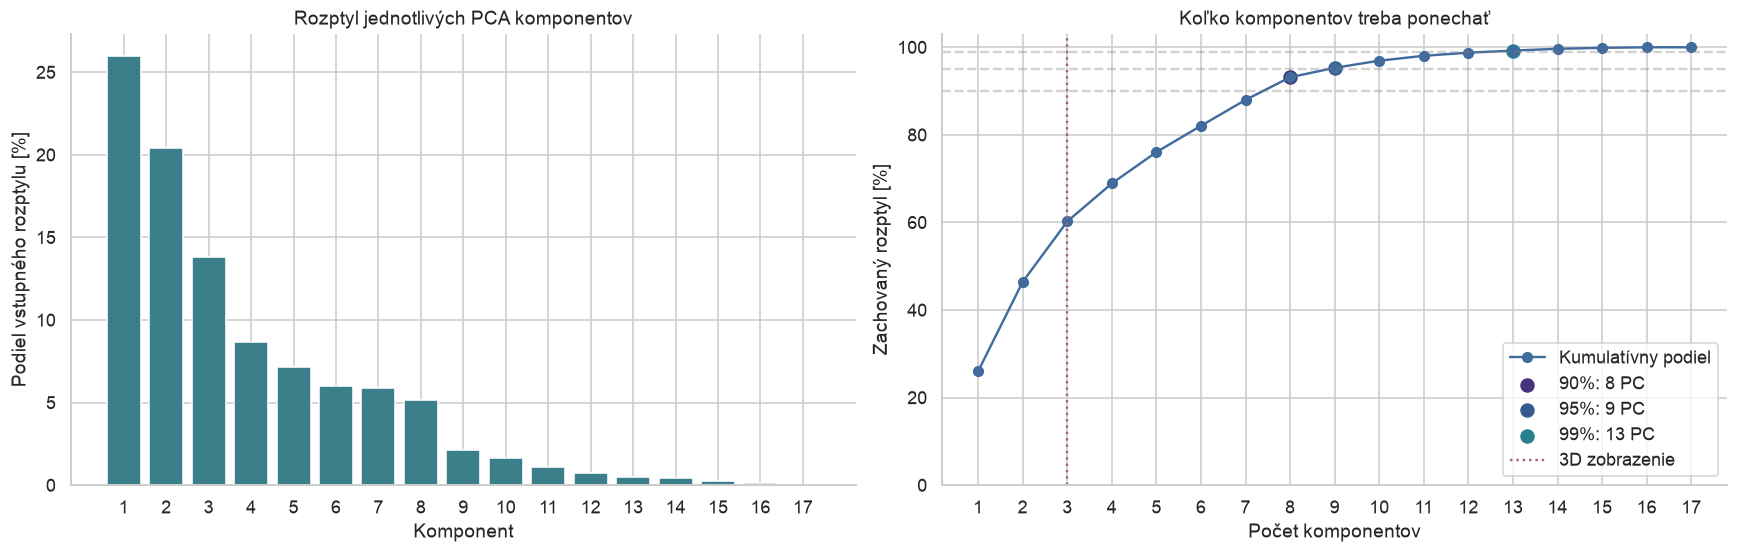

,Počet PC,Zachované [%],Stratené [%],SSE rekonštrukcie / TSS,Rekonštrukčná RMSE (z)
Voľba,,,,,
3D vizualizácia,3,60.22049,39.77951,0.39780,0.63071
Prah 90%,8,93.16159,6.83841,0.06838,0.26150
Prah 95%,9,95.31234,4.68766,0.04688,0.21651
Prah 99%,13,99.24939,0.75061,0.00751,0.08664


In [136]:
pca_full = PCA(svd_solver="full").fit(Z_train)
full_scores = pca_full.transform(Z_train)
pca_evr = pca_full.explained_variance_ratio_
pca_cumulative = np.cumsum(pca_evr)
components_axis = np.arange(1, len(pca_evr)+1)
pca_spectrum = pd.DataFrame({"Komponent":components_axis,
    "Rozptyl λ":pca_full.explained_variance_,
    "Podiel [%]":100*pca_evr,"Kumulatívne [%]":100*pca_cumulative})
display(pca_spectrum.round(5))
pca_threshold_counts = {threshold:int(np.searchsorted(pca_cumulative,threshold,side="right")+1)
                        for threshold in [.90,.95,.99]}
fig,axes=plt.subplots(1,2,figsize=(15,4.7),constrained_layout=True)
axes[0].bar(components_axis,100*pca_evr,color="#3b7f8a")
axes[0].set(title="Rozptyl jednotlivých PCA komponentov",xlabel="Komponent",ylabel="Podiel vstupného rozptylu [%]",xticks=components_axis)
axes[1].plot(components_axis,100*pca_cumulative,marker="o",color="#416b9d",label="Kumulatívny podiel")
for threshold,count in pca_threshold_counts.items():
    axes[1].axhline(100*threshold,color="gray",alpha=.35,linestyle="--")
    axes[1].scatter([count],[100*pca_cumulative[count-1]],s=65,label=f"{threshold:.0%}: {count} PC")
axes[1].axvline(3,color="#a36271",linestyle=":",label="3D zobrazenie")
axes[1].set(title="Koľko komponentov treba ponechať",xlabel="Počet komponentov",ylabel="Zachovaný rozptyl [%]",xticks=components_axis,ylim=(0,103))
axes[1].legend(loc="lower right")
plt.show()

pca_total_ss=float(np.square(Z_train-Z_train.mean(axis=0)).sum())
variance_rows=[]
for label,count in [("3D vizualizácia",3),*[(f"Prah {t:.0%}",m) for t,m in pca_threshold_counts.items()]]:
    restored=full_scores[:,:count]@pca_full.components_[:count]+pca_full.mean_
    reconstruction_ss=float(np.square(Z_train-restored).sum())
    retained=float(pca_cumulative[count-1])
    assert np.isclose(reconstruction_ss/pca_total_ss,1-retained,atol=1e-12)
    variance_rows.append({"Voľba":label,"Počet PC":count,"Zachované [%]":100*retained,
                         "Stratené [%]":100*(1-retained),
                         "SSE rekonštrukcie / TSS":reconstruction_ss/pca_total_ss,
                         "Rekonštrukčná RMSE (z)":float(np.sqrt(np.mean(np.square(Z_train-restored))))})
pca_variance_budget=pd.DataFrame(variance_rows).set_index("Voľba")
display(pca_variance_budget.round(5))
assert np.isclose(pca_full.explained_variance_.sum(),Z_train.var(axis=0,ddof=1).sum())


**3D vizualizácia:** 3 komponentov ponechá **60.22 %** a zahodí **39.78 %** vstupnej variability. Rekonštrukčná RMSE je 0.6307 v z jednotkách. Pri pohľade na 3D zhluky teda ostáva významná časť ich geometrie mimo zobrazenia.

**Prah 90%:** 8 komponentov ponechá **93.16 %** a zahodí **6.84 %** vstupnej variability. Rekonštrukčná RMSE je 0.2615 v z jednotkách. Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.

**Prah 95%:** 9 komponentov ponechá **95.31 %** a zahodí **4.69 %** vstupnej variability. Rekonštrukčná RMSE je 0.2165 v z jednotkách. Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.

**Prah 99%:** 13 komponentov ponechá **99.25 %** a zahodí **0.75 %** vstupnej variability. Rekonštrukčná RMSE je 0.0866 v z jednotkách. Percento je skutočne dosiahnutý podiel: pre diskrétny počet komponentov môže presiahnuť zadaný prah.

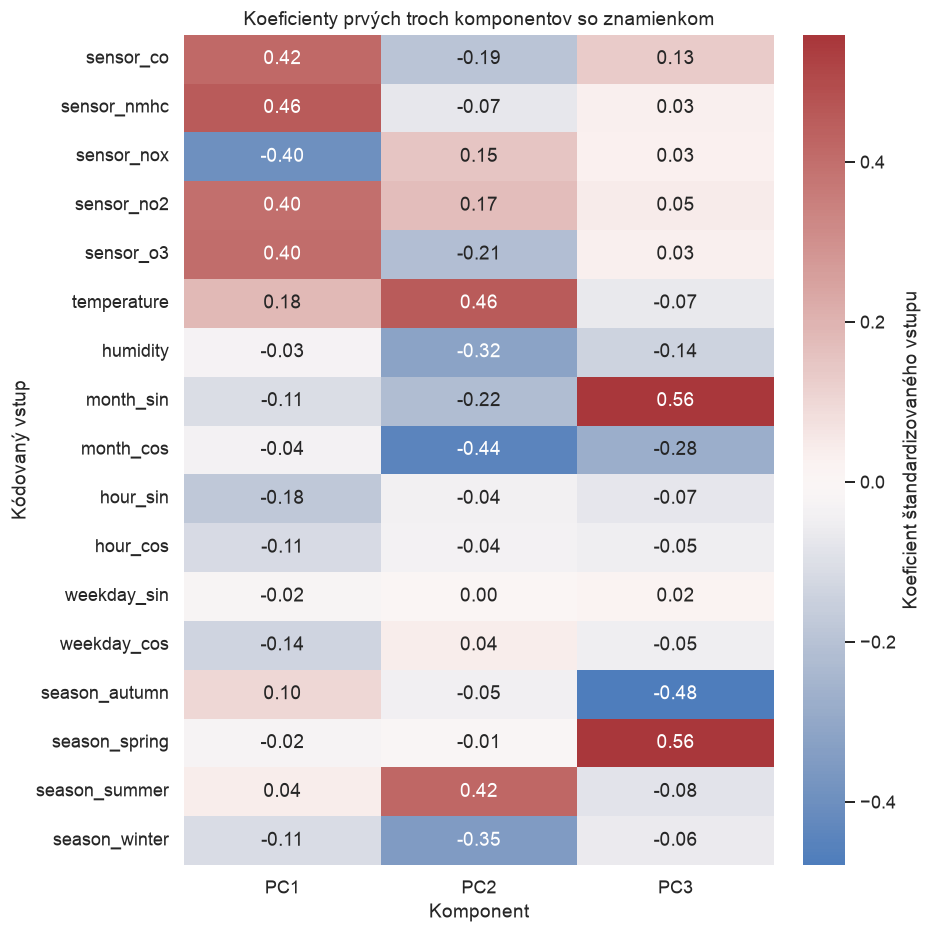

In [137]:
fig,ax=plt.subplots(figsize=(8,8),constrained_layout=True)
sns.heatmap(loadings,cmap="vlag",center=0,annot=True,fmt=".2f",ax=ax,cbar_kws={"label":"Koeficient štandardizovaného vstupu"})
ax.set(title="Koeficienty prvých troch komponentov so znamienkom",xlabel="Komponent",ylabel="Kódovaný vstup")
plt.show()


**Čítanie koeficientov:** červené a modré bunky ukazujú opačné znamienka príspevkov do komponentu. Napríklad rovnaké znamienko viacerých senzorov zachytáva ich spoločný pohyb. Opačné znamienko iného senzora kontrast medzi nimi. Väčšia absolútna hodnota znamená väčší koeficient pri rovnako škálovaných vstupoch. Ide o definíciu osi, nie o feature importance pre predikciu CO. Znamienko celého stĺpca možno otočiť bez zmeny zachovaného rozptylu. Posledný komponent má rozptyl $2.81 \times 10^{-31}$. One-hot sezóny sú lineárne závislé (ich súčet je 1), takže počet stĺpcov nie je totožný s počtom nezávislých smerov variability.

### Priame porovnanie 3D grafov

Oba grafy nižšie používajú tie isté merania a rovnakú farebnú škálu CO. Mení sa iba reprezentácia vstupov.

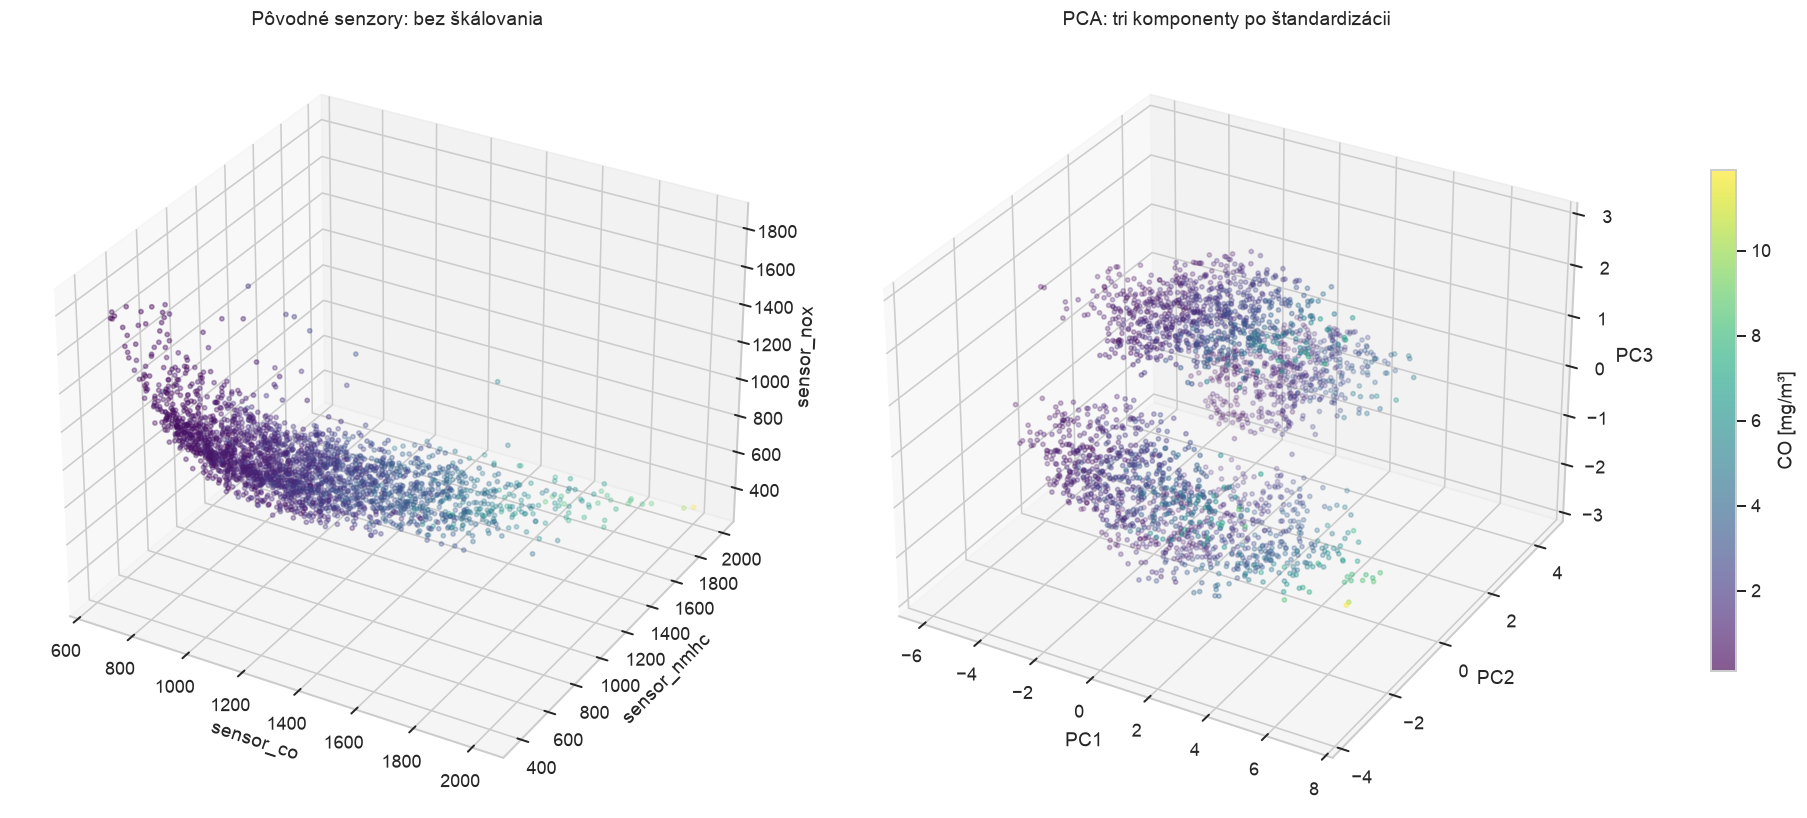

In [138]:
fig=plt.figure(figsize=(16,7),constrained_layout=True)
a1=fig.add_subplot(121,projection="3d")
a2=fig.add_subplot(122,projection="3d")
a1.scatter(*X_train_in.iloc[show_idx][["sensor_co","sensor_nmhc","sensor_nox"]].to_numpy().T,
           c=shown_co,cmap="viridis",norm=norm,s=7,alpha=.65)
a1.set(xlabel="sensor_co",ylabel="sensor_nmhc",zlabel="sensor_nox",title="Pôvodné senzory: bez škálovania")
sc=a2.scatter(*coords3[show_idx].T,c=shown_co,cmap="viridis",norm=norm,s=7,alpha=.65)
a2.set(xlabel="PC1",ylabel="PC2",zlabel="PC3",title="PCA: tri komponenty po štandardizácii")
fig.colorbar(sc,ax=[a1,a2],label="CO [mg/m³]",shrink=.65,pad=.06)
plt.show()

V pôvodnom priestore sú osi priamo odozvy konkrétnych senzorov. V PCA priestore sú kombináciami všetkých vstupov vrátane kalendára a počasia; farebný gradient sa sústreďuje najmä pozdĺž PC1. Tri PC zachovávajú približne **60,22 %** vstupného rozptylu, zvyšných **39,78 %** tento obrázok nezobrazuje. Viditeľné pásy nie sú triedy CO. Ani čitateľnejší obraz sám nepreukazuje lepšiu regresiu.

# Trénovanie modelu na zmenšenej množine

Používam rovnaký typ a hyperparametre modelu vybraného v prvej časti podľa CV. Počet ponechaných príznakov alebo prah PCA vyberám vo vnútri tréningovej CV. Každý selector sa učí iba na tréningovej časti daného foldu. Test zostáva spoločný pre všetky stratégie.

In [139]:
class CorrelationSelector(TransformerMixin,BaseEstimator):
    def __init__(self,k=8,max_correlation=.95):
        self.k=k
        self.max_correlation=max_correlation
    def fit(self,X,y):
        values=np.asarray(X,dtype=float)
        self.n_features_in_=values.shape[1]
        matrix=pd.DataFrame(values).assign(target=np.asarray(y)).corr().fillna(0)
        relevance=matrix.target.drop("target").abs().to_numpy()
        chosen=[]
        for i in np.argsort(-relevance,kind="stable"):
            if all(abs(matrix.iloc[i,j])<self.max_correlation for j in chosen):
                chosen.append(int(i))
            if len(chosen)>=self.k:break
        self.indices_=np.array(chosen,dtype=int)
        return self
    def transform(self,X):return np.asarray(X)[:,self.indices_]

class ForestSelector(TransformerMixin,BaseEstimator):
    def __init__(self,k=8,random_state=SEED):
        self.k=k
        self.random_state=random_state
    def fit(self,X,y):
        self.n_features_in_=np.asarray(X).shape[1]
        self.forest_=RandomForestRegressor(n_estimators=120,max_features=.8,n_jobs=1,random_state=self.random_state)
        self.forest_.fit(X,y)
        self.indices_=np.argsort(-self.forest_.feature_importances_,kind="stable")[:self.k]
        return self
    def transform(self,X):return np.asarray(X)[:,self.indices_]

In [140]:
reduced_models={"Všetky príznaky":best_model}
selection_rows=[{"Stratégia":"Všetky príznaky","Počet vstupov":len(encoded_names),
                 "CV MSE":float(cv_results.loc[BEST_NAME,"CV MSE"]),
                 **{"Test "+k:v for k,v in regression_metrics(y_test,best_model.predict(X_test)).items()}}]
selection_details={}

def fit_reduced_model(name, selector, grid):
    search=GridSearchCV(make_pipeline(best_base_estimator,selector),grid,
                        scoring=SCORING,refit="mse",cv=cv,n_jobs=N_JOBS,return_train_score=True,error_score="raise")
    with parallel_backend("threading"),threadpool_limits(limits=1):search.fit(X_train,y_train)
    model=search.best_estimator_
    reduced_models[name]=model
    fitted_selector=model.estimator_.named_steps["selection"]
    count=fitted_selector.n_components_ if isinstance(fitted_selector,PCA) else len(fitted_selector.indices_)
    if isinstance(fitted_selector,PCA):
        selected_info=f"Variancia {search.best_params_['estimator__selection__n_components']}; skutočne zachované {fitted_selector.explained_variance_ratio_.sum():.4f}"
    else:
        selected_info=", ".join(encoded_names[fitted_selector.indices_])
    selection_details[name]=selected_info
    print(name,"|",search.best_params_,"|",selected_info)
    row={"Stratégia":name,"Počet vstupov":int(count),"CV MSE":-search.best_score_}
    for label,X,y in [("Train",X_train,y_train),("Test",X_test,y_test)]:
        row.update({label+" "+k:v for k,v in regression_metrics(y,model.predict(X)).items()})
    selection_rows.append(row)
    return model, search

## Korelačná matica

Zoradím vstupy podľa absolútnej Pearsonovej korelácie s CO a vynechám príznaky s absolútnou koreláciou aspoň 0,95 s už vybraným vstupom. CV vyberá najviac 4 alebo 8 príznakov. Heatmapa nižšie je opis finálneho tréningového výberu, nie podklad na výber podľa testu.

Korelácia | {'estimator__selection__k': 8} | sensor_nmhc, sensor_co, sensor_o3, sensor_nox, sensor_no2, hour_sin, weekday_cos, month_cos


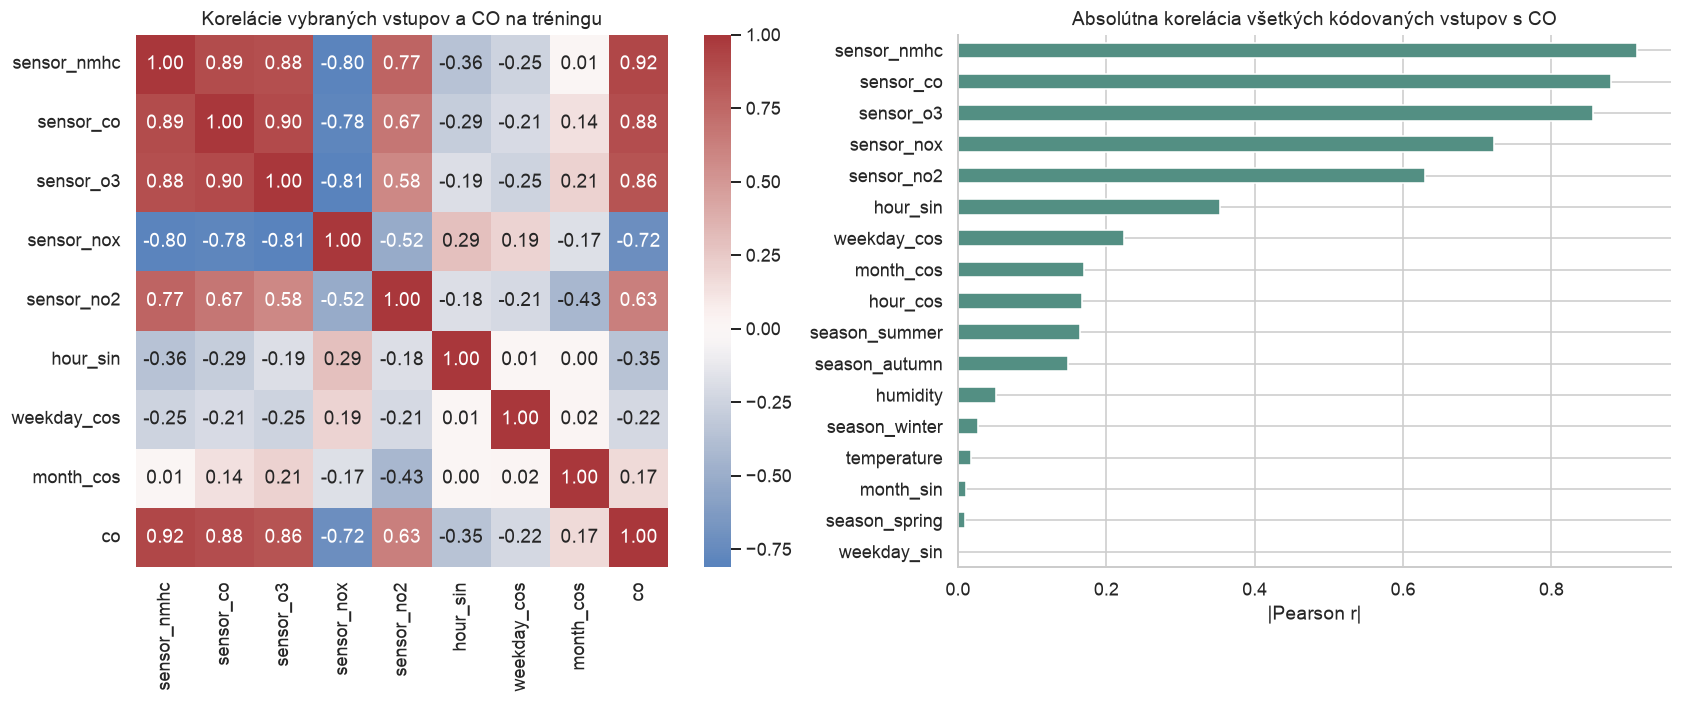

,Vybraný príznak
0,sensor_nmhc
1,sensor_co
2,sensor_o3
3,sensor_nox
4,sensor_no2
5,hour_sin
6,weekday_cos
7,month_cos


In [141]:
correlation_model, correlation_search = fit_reduced_model('Korelácia', CorrelationSelector(), {'estimator__selection__k': [4, 8]})
correlation_pipeline = correlation_model.estimator_
correlation_values = correlation_pipeline.named_steps['scale'].transform(
    correlation_pipeline.named_steps['preprocessing'].transform(
        correlation_pipeline.named_steps['calendar'].transform(X_train_in)))
selected_correlation = encoded_names[correlation_pipeline.named_steps['selection'].indices_]
correlation_matrix = pd.DataFrame(correlation_values, columns=encoded_names).assign(co=y_train_in.to_numpy()).corr()
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
sns.heatmap(correlation_matrix.loc[[*selected_correlation, TARGET], [*selected_correlation, TARGET]], annot=True, fmt='.2f', cmap='vlag', center=0, square=True, ax=axes[0])
axes[0].set_title('Korelácie vybraných vstupov a CO na tréningu')
correlation_matrix[TARGET].drop(TARGET).abs().sort_values().plot.barh(ax=axes[1], color='#538f83')
axes[1].set(title='Absolútna korelácia všetkých kódovaných vstupov s CO', xlabel='|Pearson r|')
plt.show()
display(pd.DataFrame({'Vybraný príznak': selected_correlation}))

**Korelácia:** 8 vstupov, testovacie $R^2$ **0.9248**, RMSE **0.3946 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0869 $\mathrm{mg}/\mathrm{m}^3$. Zmenšenie tu neprinieslo nižšiu chybu. Úspora rozmerov môže stáť predikčnú informáciu.

## Dôležitosť príznakov z ensemble

Pomocný Random Forest sa učí v každom CV folde od začiatku. CV vyberá 4 alebo 8 vstupov podľa jeho natívnych dôležitostí. Finálny graf ukazuje tréningový rebríček; farebne odlišuje ponechané a vynechané vstupy.

RF dôležitosť | {'estimator__selection__k': 8} | sensor_nmhc, sensor_co, sensor_o3, temperature, sensor_nox, sensor_no2, hour_sin, humidity


,Dôležitosť,Vybraný
sensor_nmhc,0.70083,True
sensor_co,0.12986,True
sensor_o3,0.07970,True
temperature,0.02528,True
sensor_nox,0.01289,True
sensor_no2,0.00993,True
hour_sin,0.00971,True
humidity,0.00859,True
hour_cos,0.00664,False
month_cos,0.00495,False


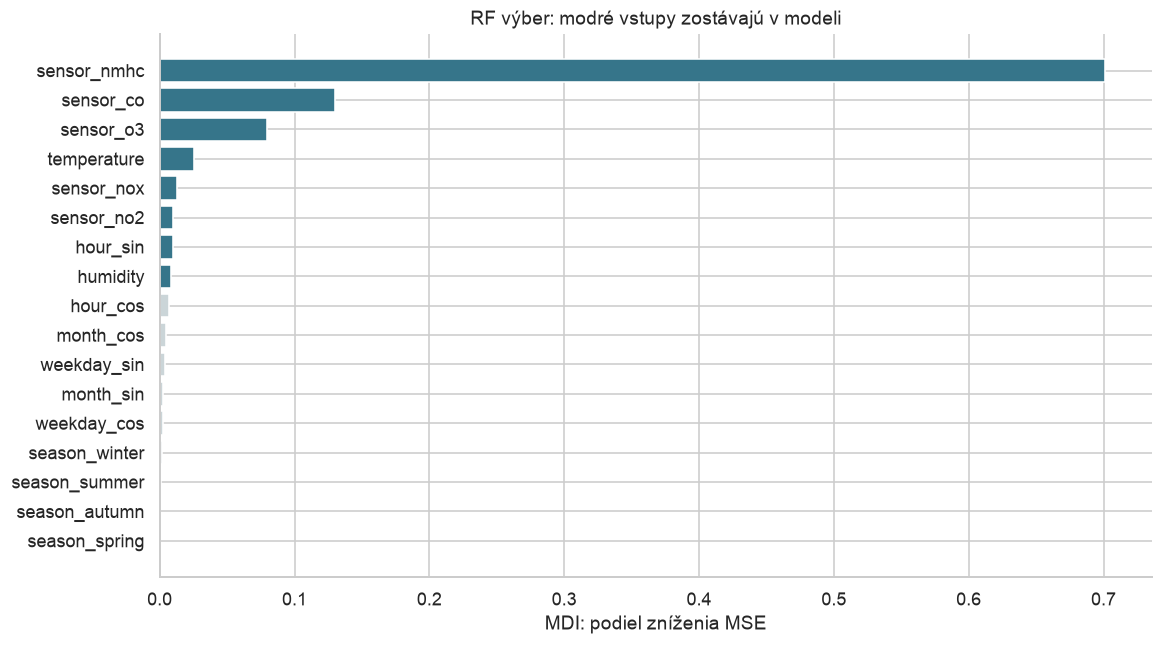

In [142]:
forest_selection_model, forest_selection_search = fit_reduced_model('RF dôležitosť', ForestSelector(), {'estimator__selection__k': [4, 8]})
fitted_forest_selector = forest_selection_model.estimator_.named_steps['selection']
selection_importance = pd.DataFrame({'Dôležitosť': fitted_forest_selector.forest_.feature_importances_,
    'Vybraný': np.isin(np.arange(len(encoded_names)), fitted_forest_selector.indices_)}, index=encoded_names).sort_values('Dôležitosť', ascending=False)
display(selection_importance.round(5))
shown = selection_importance.sort_values('Dôležitosť')
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
ax.barh(shown.index, shown['Dôležitosť'], color=np.where(shown.Vybraný, '#36758a', '#cbd5d8'))
ax.set(title='RF výber: modré vstupy zostávajú v modeli', xlabel='MDI: podiel zníženia MSE')
plt.show()

**RF dôležitosť:** 8 vstupov, testovacie $R^2$ **0.9314**, RMSE **0.3770 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0693 $\mathrm{mg}/\mathrm{m}^3$. Zmenšenie tu neprinieslo nižšiu chybu. Úspora rozmerov môže stáť predikčnú informáciu.

## Podľa variancie

PCA skúša hranice vysvetlenej variability 90 %, 95 % a 99 %; počet komponentov vyplynie z dát. Ide o inú úlohu než pevné tri komponenty pre 3D zobrazenie. Zachovanie 99 % rozptylu vstupov neznamená zachovanie 99 % informácie o CO.

PCA variancia | {'estimator__selection__n_components': 0.99} | Variancia 0.99; skutočne zachované 0.9925


,Prah,CV RMSE,CV R²
0,0.90,0.40020,0.92211
1,0.95,0.37631,0.93110
2,0.99,0.33488,0.94552


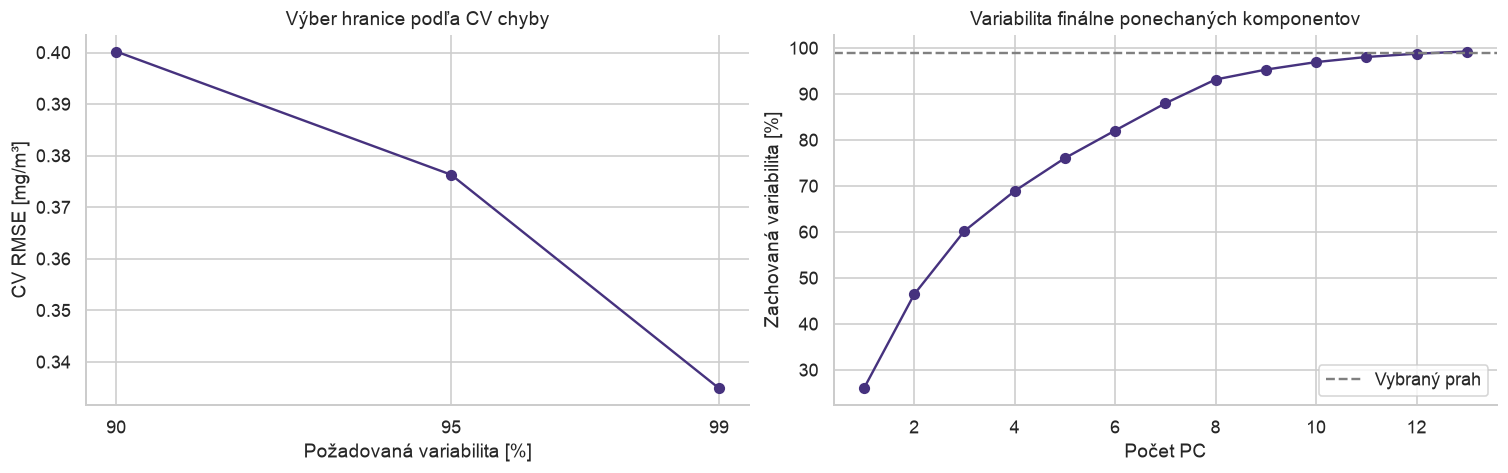

In [143]:
pca_selection_model, pca_selection_search = fit_reduced_model('PCA variancia', PCA(svd_solver='full'), {'estimator__selection__n_components': [.90, .95, .99]})
selected_pca = pca_selection_model.estimator_.named_steps['selection']
pca_cv_table = pd.DataFrame(pca_selection_search.cv_results_)
pca_candidate_rows = []
for _, row in pca_cv_table.iterrows():
    pca_candidate_rows.append({'Prah': row['param_estimator__selection__n_components'],
        'CV RMSE': np.sqrt(-row['mean_test_mse']), 'CV R²': row['mean_test_r2']})
pca_candidate_table = pd.DataFrame(pca_candidate_rows).sort_values('Prah')
display(pca_candidate_table.round(5))
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].plot(pca_candidate_table.Prah*100, pca_candidate_table['CV RMSE'], marker='o')
axes[0].set(title='Výber hranice podľa CV chyby', xlabel='Požadovaná variabilita [%]', ylabel='CV RMSE [mg/m³]', xticks=[90, 95, 99])
axes[1].plot(np.arange(1, selected_pca.n_components_+1), 100*np.cumsum(selected_pca.explained_variance_ratio_), marker='o')
axes[1].axhline(100*pca_selection_search.best_params_['estimator__selection__n_components'], color='gray', linestyle='--', label='Vybraný prah')
axes[1].set(title='Variabilita finálne ponechaných komponentov', xlabel='Počet PC', ylabel='Zachovaná variabilita [%]')
axes[1].legend()
plt.show()

**PCA variancia:** 13 vstupov, testovacie $R^2$ **0.9478**, RMSE **0.3289 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0213 $\mathrm{mg}/\mathrm{m}^3$. Zmenšenie tu neprinieslo nižšiu chybu. Úspora rozmerov môže stáť predikčnú informáciu.

### Prepojenie zachovaného rozptylu s regresnými výsledkami

Pri výbere podľa korelácie alebo RF dôležitosti ponechávam pôvodné kódované osi. Tieto metódy nemajú predpísanú záruku zachovania určitého podielu celkovej variability. Sledujú súvislosť s cieľom alebo využívanie vstupov modelom. PCA namiesto toho vytvára nové osi a má explicitný limit straty rozptylu.

V tomto experimente PCA s hranicou 99 % ponechalo 13 komponentov a skutočne zachovalo približne 99,25 % vstupnej variability. Aj tak testovacia RMSE SVR vzrástla približne z 0,3077 na 0,3289 $\mathrm{mg}/\mathrm{m}^3$. Strata len 0,75 % vstupného rozptylu teda **neznamená** rovnakú relatívnu zmenu regresnej chyby. PCA nepozná CO a nemôže zaručiť, že zahodí iba nepotrebnú informáciu. Naproti tomu tri komponenty pre obrázok zachovávajú len približne 60,2 %, preto ich nepovažujem za rovnocennú náhradu zvolenej 13D regresnej reprezentácie.

## Porovnanie

Porovnám pôvodný model a všetky tri stratégie na totožných testovacích meraniach. Okrem výsledných chýb sledujem aj počet vstupov a reziduály.

,Počet vstupov,CV MSE,Test MSE,Test RMSE,Test MAE,Test R²,Train MSE,Train RMSE,Train MAE,Train R²
Stratégia,,,,,,,,,,
Všetky príznaky,17,0.1046,0.0947,0.3077,0.1994,0.9543,0.0350,0.1870,0.1199,0.9830
Korelácia,8,0.1533,0.1557,0.3946,0.2478,0.9248,0.1032,0.3212,0.1928,0.9499
RF dôležitosť,8,0.1506,0.1421,0.3770,0.2324,0.9314,0.1018,0.3191,0.1889,0.9506
PCA variancia,13,0.1121,0.1082,0.3289,0.2093,0.9478,0.0470,0.2168,0.1342,0.9772


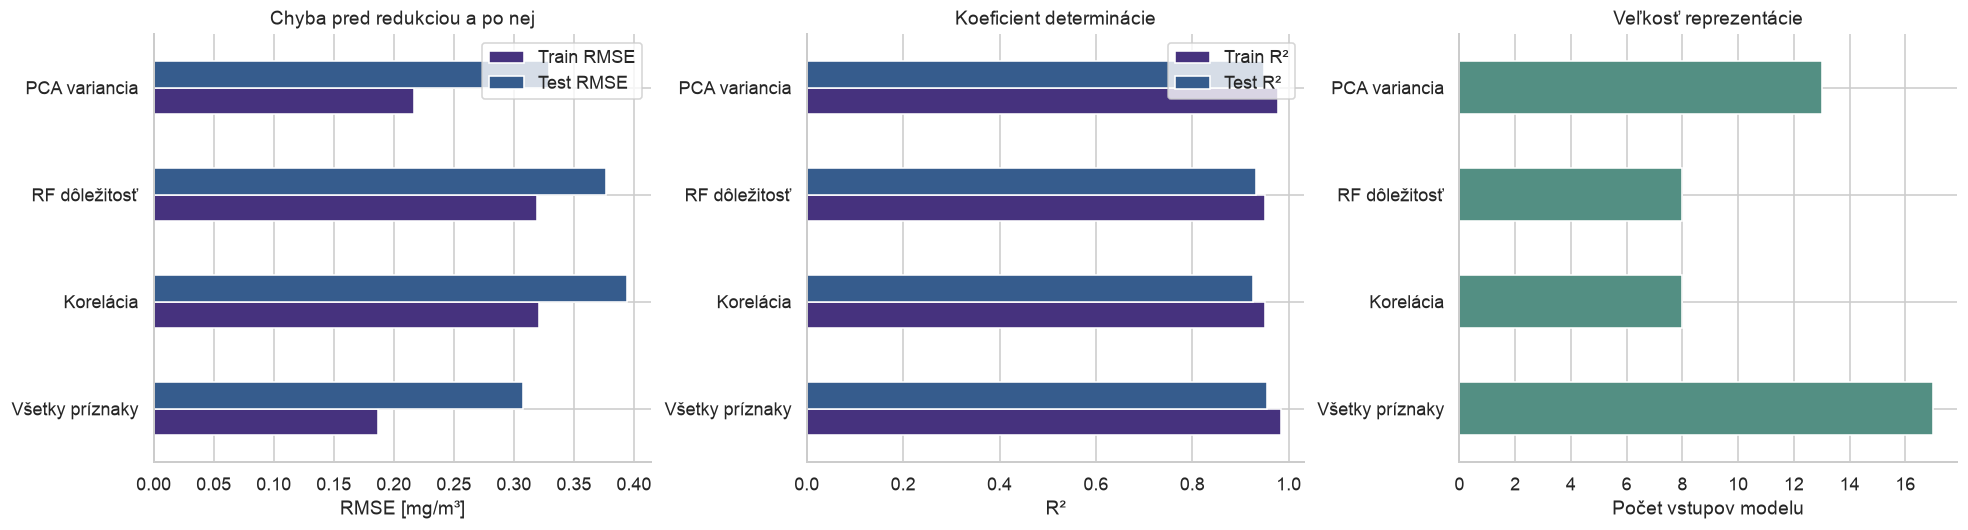

In [144]:
# Doplním tréningové metriky referenčného modelu.
selection_rows[0].update({"Train "+k:v for k,v in regression_metrics(y_train,best_model.predict(X_train)).items()})
selection_results=pd.DataFrame(selection_rows).set_index("Stratégia")
display(selection_results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
selection_results[['Train RMSE', 'Test RMSE']].plot.barh(ax=axes[0])
axes[0].set(title='Chyba pred redukciou a po nej', xlabel='RMSE [mg/m³]', ylabel='')
selection_results[['Train R²', 'Test R²']].plot.barh(ax=axes[1])
axes[1].set(title='Koeficient determinácie', xlabel='R²', ylabel='')
selection_results['Počet vstupov'].plot.barh(ax=axes[2], color='#538f83')
axes[2].set(title='Veľkosť reprezentácie', xlabel='Počet vstupov modelu', ylabel='')
plt.show()

**Všetky príznaky:** 17 vstupov, testovacie $R^2$ **0.9543**, RMSE **0.3077 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0000 $\mathrm{mg}/\mathrm{m}^3$. Toto je referencia pre ostatné stratégie.

**Korelácia:** 8 vstupov, testovacie $R^2$ **0.9248**, RMSE **0.3946 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0869 $\mathrm{mg}/\mathrm{m}^3$. Zmenšenie tu neprinieslo nižšiu chybu. Úspora rozmerov môže stáť predikčnú informáciu.

**RF dôležitosť:** 8 vstupov, testovacie $R^2$ **0.9314**, RMSE **0.3770 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0693 $\mathrm{mg}/\mathrm{m}^3$. Zmenšenie tu neprinieslo nižšiu chybu. Úspora rozmerov môže stáť predikčnú informáciu.

**PCA variancia:** 13 vstupov, testovacie $R^2$ **0.9478**, RMSE **0.3289 $\mathrm{mg}/\mathrm{m}^3$**, rozdiel RMSE oproti plnému modelu +0.0213 $\mathrm{mg}/\mathrm{m}^3$. Zmenšenie tu neprinieslo nižšiu chybu. Úspora rozmerov môže stáť predikčnú informáciu.

### Reziduály po redukcii

Rovnaké testovacie riadky a spoločné osi umožňujú porovnať, či redukcia zväčšuje rozptyl alebo podhodnotenie pri vysokom CO. Korelačný výber zachytáva lineárny vzťah s cieľom, ensemble aj nelinearity, PCA predovšetkým veľké smery variability. Preto ich poradie podľa zachovanej variability nemusí súhlasiť s poradím predikčnej chyby.

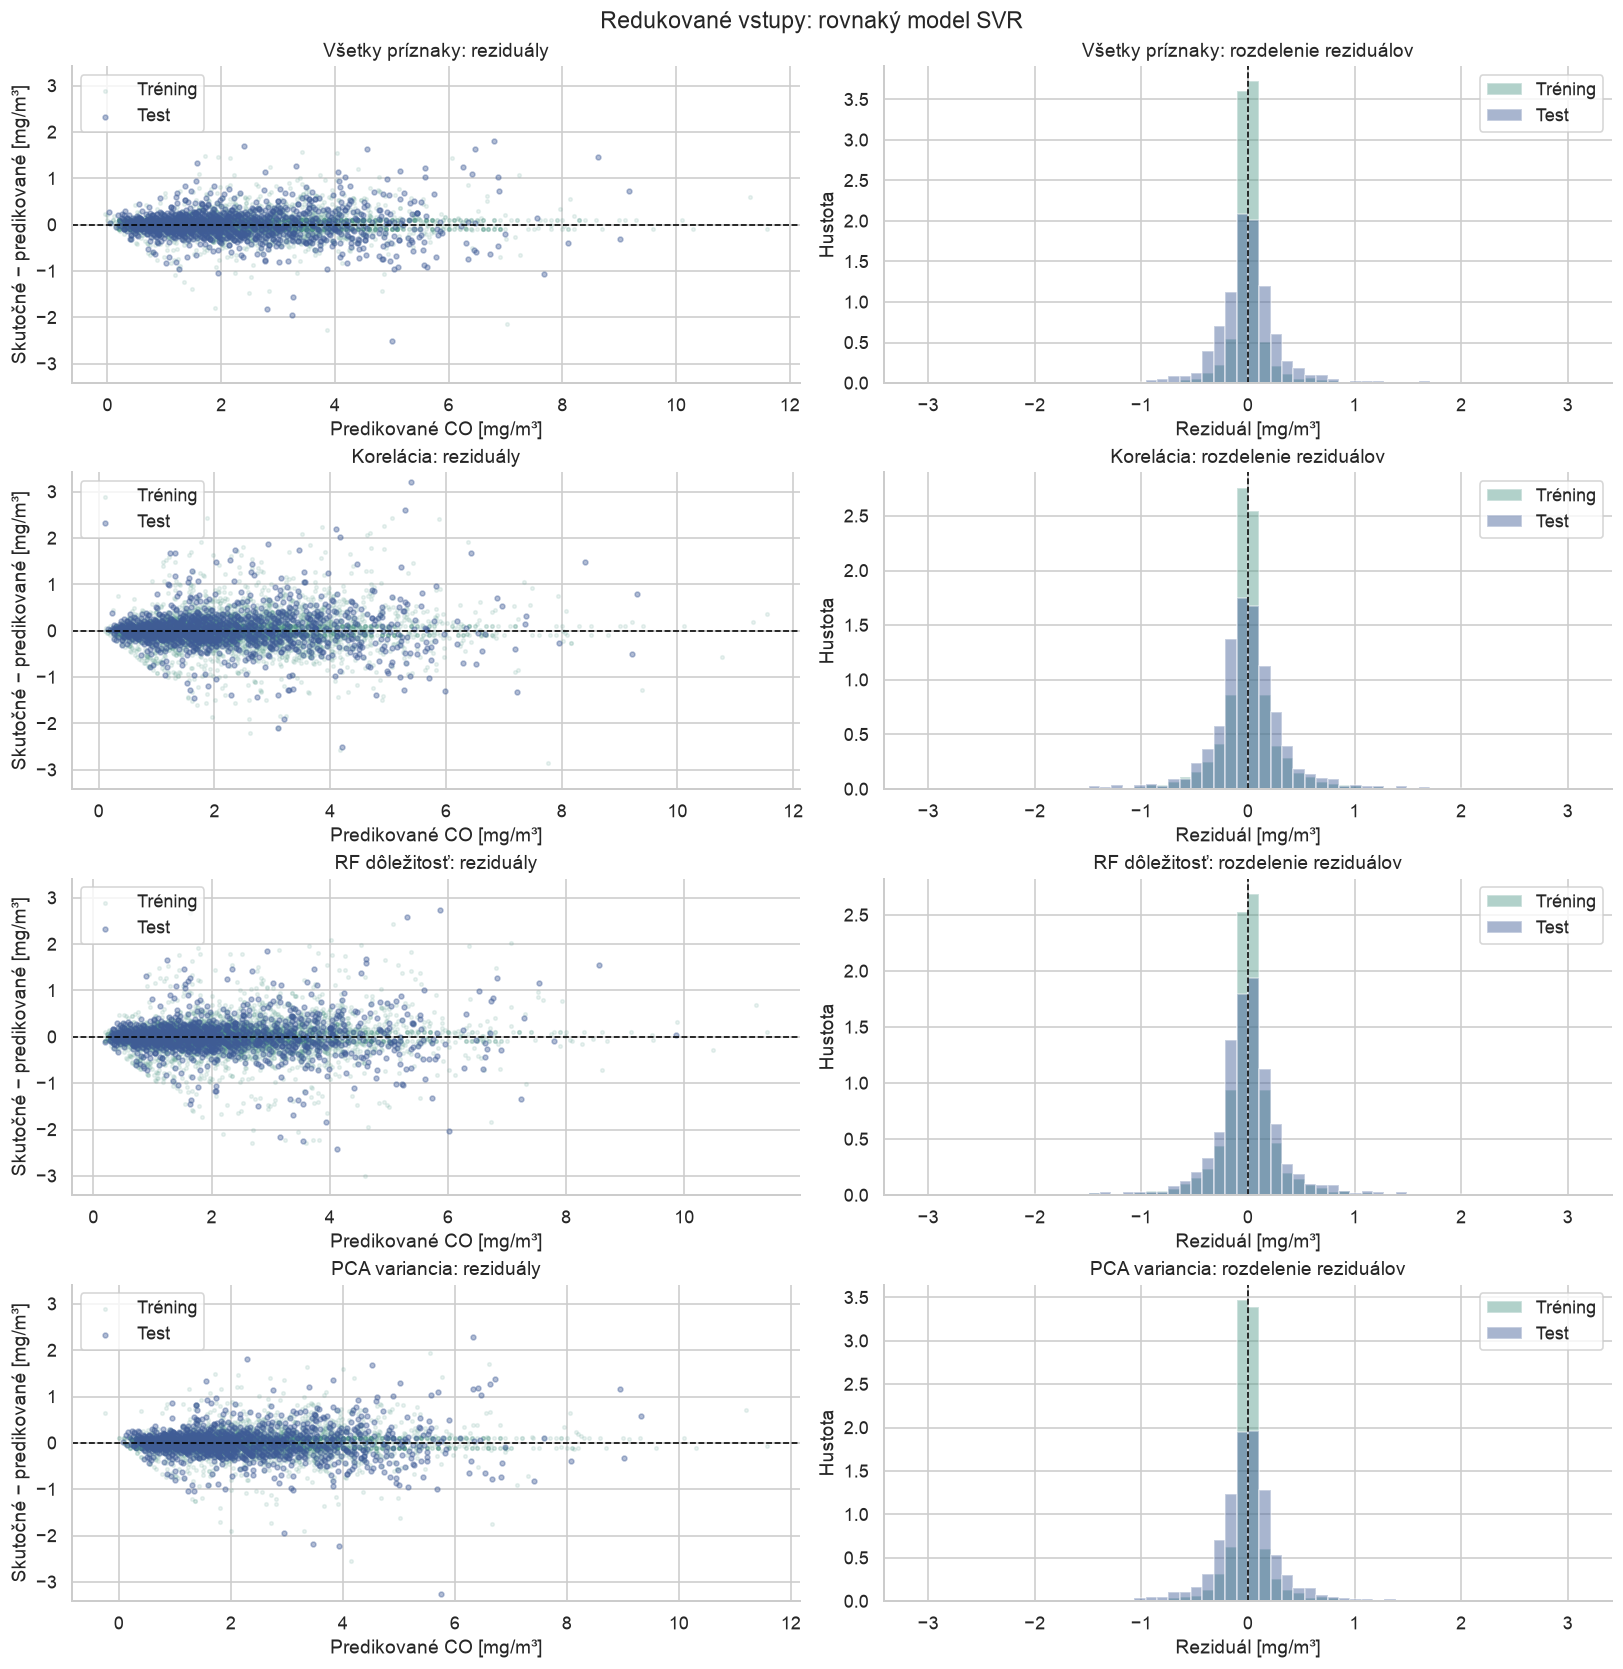

,Priemer reziduála,Medián reziduála,95. percentil |e|,Korelácia |e| a predikcie
Model,,,,
Všetky príznaky,0.0019,-0.0040,0.6502,0.4270
Korelácia,0.0149,-0.0027,0.7978,0.3659
RF dôležitosť,0.0030,-0.0006,0.7707,0.3580
PCA variancia,0.0001,-0.0023,0.6800,0.3972


In [145]:
selection_residuals=plot_residuals(reduced_models,f"Redukované vstupy: rovnaký model {BEST_NAME}")


**Všetky príznaky:** priemerný testovací reziduál 0.0019 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.650 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.427. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**Korelácia:** priemerný testovací reziduál 0.0149 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.798 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.366. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**RF dôležitosť:** priemerný testovací reziduál 0.0030 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.771 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.358. Chyby majú tendenciu rásť s predikovanou koncentráciou.

**PCA variancia:** priemerný testovací reziduál 0.0001 $\mathrm{mg}/\mathrm{m}^3$ znamená podhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.680 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.397. Chyby majú tendenciu rásť s predikovanou koncentráciou.

# Zhlukovanie – bonus
## Vizualizácia
### Výber počtu zhlukov a zobrazenie

K-means naučím na **všetkých 17 štandardizovaných vstupoch**, bez CO a iba z tréningových inlierov. Porovnám 3, 4 a 5 zhlukov pomocou silhouette skóre na rovnakej tréningovej podvzorke. Vyberiem najvyššie skóre, nie najlepšiu regresiu na teste. Každý bod na 3D grafe má farbu zhluku. Osi sú iba tri PCA súradnice, takže zhlukovanie využíva viac príznakov než vizualizácia. Prekryv v projekcii nemusí znamenať prekryv v plnom priestore.

### Čo pri zhlukovaní znamená rozptyl

PCA vyberá smery zachovávajúce čo najviac vstupnej variability. K-means má inú úlohu: prideľuje body k centroidom tak, aby boli **vnútri skupiny čo najbližšie**. Strieda priradenie bodov k najbližšiemu centroidu a presun centroidu na priemer priradených bodov. Používam 20 inicializácií, pretože výsledok môže závisieť od počiatočných centroidov. [Intuícia zhlukovania v mlcourse.ai](https://mlcourse.ai/book/topic07/topic7_pca_clustering.html), [kritérium inertia v scikit-learn](https://scikit-learn.org/stable/modules/clustering.html#k-means).

Samotným pridelením štítka zhluku sa žiadny vstup ani jeho rozptyl nestráca: lokálne regresné modely stále dostanú všetky vstupy. **Až keby som každý bod nahradil centroidom**, zmizla by jeho odchýlka od priemeru skupiny. Túto hypotetickú stratu kvantifikujem rozkladom súčtu štvorcov vzdialeností:

$$
\begin{aligned}
\mathrm{TSS} &= \sum_i \lVert z_i - \bar{z} \rVert^2 && \text{celkový rozptyl dátového oblaku} \\
\mathrm{WSS} &= \sum_k \sum_{i \in C_k} \lVert z_i - \mu_k \rVert^2 && \text{rozptyl vnútri zhlukov} \\
\mathrm{BSS} &= \sum_k n_k \lVert \mu_k - \bar{z} \rVert^2 && \text{rozptyl medzi centroidmi} \\
\mathrm{TSS} &= \mathrm{WSS} + \mathrm{BSS} \\
\text{Podiel rozlíšený centroidmi} &= \frac{\mathrm{BSS}}{\mathrm{TSS}} \\
\text{Podiel stratený nahradením bodov centroidmi} &= \frac{\mathrm{WSS}}{\mathrm{TSS}}
\end{aligned}
$$

$\mu_k$ je priemer bodov skupiny a $n_k$ ich počet. TSS, WSS a BSS sú súčty štvorcov. Po vydelení spoločným $n - 1$ ide o zodpovedajúce príspevky k celkovému súčtu výberových rozptylov. Ich pomery sa nemenia. Tieto percentá opisujú **geometriu vstupov**, nie rozptyl či regresné $R^2$ koncentrácie CO.

K-means minimalizuje WSS, v knižnici označené `inertia_` pre naučené centroidy. Pre presný rozklad nižšie použijem empirické priemery konečných skupín: kvôli tolerancii zastavenia môžu mať voči uloženým centroidom malý rozdiel. Väčší počet skupín môže znižovať WSS aj bez praktického prínosu. Samotný vysoký $\mathrm{BSS}/\mathrm{TSS}$ preto nie je dôvodom vybrať viac zhlukov. Počet skupín naďalej volím podľa vopred určeného silhouette skóre.

### Koľko rozptylu zhlukov naozaj vidíme v 3D

Zhluky vznikajú v 17D priestore, ale graf ukazuje tri **globálne** PCA komponenty. Vypočítam zvlášť, aký podiel variability medzi centroidmi a vnútri skupín zostal v tejto projekcii. Tiež uvediem zachovaný vnútorný rozptyl každej skupiny. Rovnaká 3D projekcia nemusí zachovať rovnaké percento pre všetky zhluky. PCA tu znova netrénujem po jednotlivých skupinách, preto ich súradnice zostávajú porovnateľné. Oddelenie alebo prekryv na obrázku je preto potrebné čítať spolu s týmito číslami.


,Silhouette,Inertia
k,,
3,0.1870,69255.8934
4,0.2520,59772.9587
5,0.2333,53217.3583


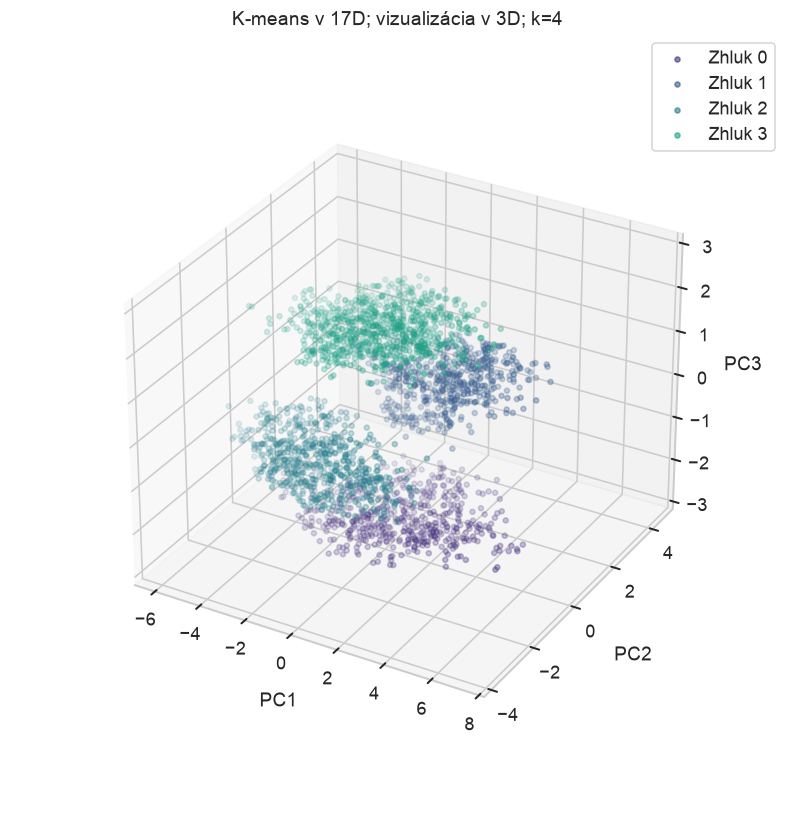

,sensor_co,sensor_nmhc,sensor_nox,sensor_no2,sensor_o3,temperature,humidity
Zhluk,,,,,,,
0,1109.5,998.5,726.0,1481.5,1101.5,19.6,57.3
1,1012.0,912.0,822.0,1632.0,858.0,27.3,37.9
2,1069.0,866.0,763.0,1122.0,1032.0,8.6,55.8
3,1126.0,917.0,842.0,1455.0,984.5,16.1,47.8


In [146]:
cluster_candidates={}
cluster_rows=[]
for k in [3,4,5]:
    with threadpool_limits(limits=1):
        km=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(Z_train)
        sil=silhouette_score(Z_train,km.labels_,sample_size=min(2000,len(Z_train)),random_state=SEED)
    cluster_candidates[k]=km
    cluster_rows.append({"k":k,"Silhouette":sil,"Inertia":km.inertia_})
cluster_quality=pd.DataFrame(cluster_rows).set_index("k")
K=int(cluster_quality.Silhouette.idxmax())
kmeans=cluster_candidates[K]
train_cluster=kmeans.predict(projection_pipeline.transform(X_train))
test_cluster=kmeans.predict(Z_test)
display(cluster_quality.round(4))
fig=plt.figure(figsize=(10,7),constrained_layout=True)
ax=fig.add_subplot(111,projection="3d")
for group in range(K):
    mask=kmeans.labels_[show_idx]==group
    xyz=coords3[show_idx][mask]
    ax.scatter(*xyz.T,s=10,alpha=.6,label=f"Zhluk {group}")
ax.set(xlabel="PC1",ylabel="PC2",zlabel="PC3",title=f"K-means v {Z_train.shape[1]}D; vizualizácia v 3D; k={K}")
ax.set_box_aspect((1, 1, .8), zoom=.82)
ax.set_xlabel("PC1", labelpad=12)
ax.set_ylabel("PC2", labelpad=16)
ax.set_zlabel("PC3", labelpad=10)
ax.legend()
plt.show()
profiles=X_train_in[CONTINUOUS].assign(Zhluk=kmeans.labels_).groupby("Zhluk").median()
display(profiles.round(2))


Vybral som **4 zhluky** so silhouette **0.252**. Hodnota blízko nule by znamenala slabé oddelenie, blízko jednej kompaktné oddelené skupiny. Profily ukazujú mediány pôvodných senzorov a počasia. Čísla zhlukov sú ľubovoľné označenia, nie triedy zdravotnej bezpečnosti a ani intervaly CO. Cieľ sa pri ich vytváraní nepoužil.

,TSS,WSS,BSS,Inertia modelu,BSS/TSS [%],WSS/TSS [%],Silhouette
k,,,,,,,
3,99484.0,69255.84416,30228.15584,69255.89344,30.38494,69.61506,0.18696
4,99484.0,59772.95867,39711.04133,59772.95867,39.91701,60.08299,0.25197
5,99484.0,53217.28622,46266.71378,53217.35831,46.50669,53.49331,0.23333


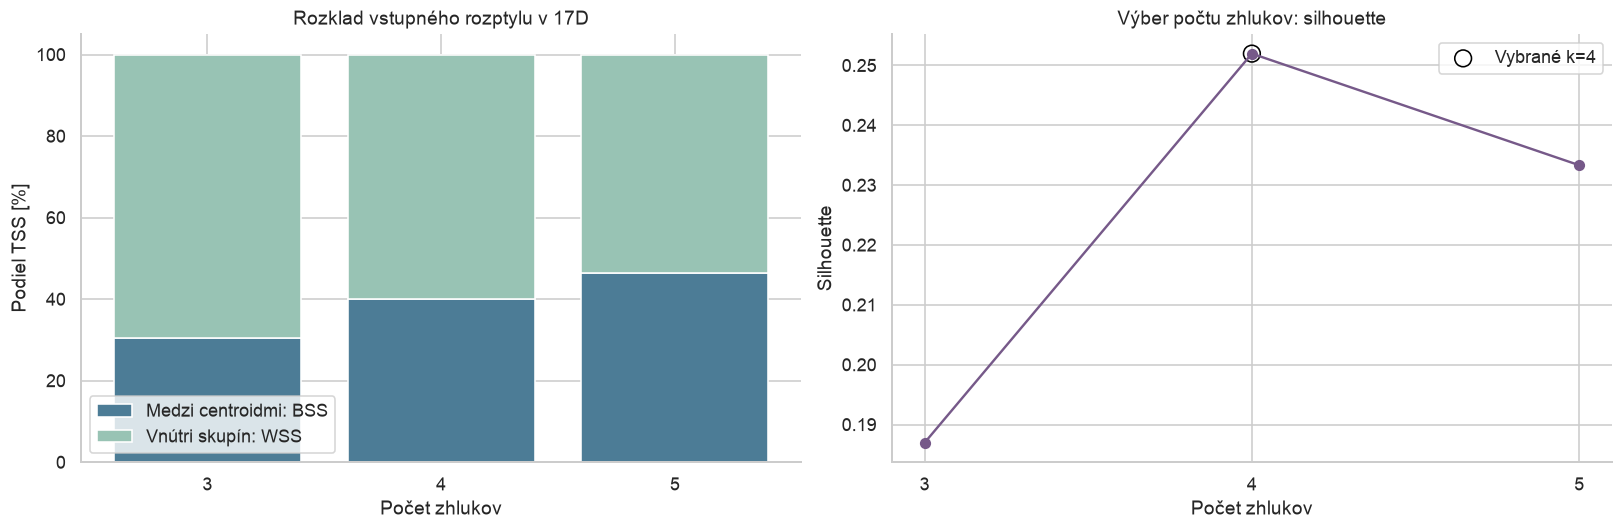

,Zachované v 3D [%]
Veličina,
Celkový rozptyl,60.2205
Rozptyl vnútri zhlukov,47.7296
Rozptyl medzi centroidmi,79.0218


,n,Rozptyl v 17D,Rozptyl v 3D,Zachovaný vnútorný rozptyl [%],Stratený vnútorný rozptyl [%]
Zhluk,,,,,
0,1292,11.5041,6.2947,54.7173,45.2827
1,1297,8.2554,3.2711,39.6243,60.3757
2,1389,10.2220,4.8409,47.3576,52.6424
3,1874,10.6962,5.0423,47.1413,52.8587


In [147]:
def scatter_decomposition(values, labels):
    values=np.asarray(values,dtype=float)
    center=values.mean(axis=0)
    total=float(np.square(values-center).sum())
    within,between=0.,0.
    group_rows=[]
    for group in np.unique(labels):
        members=values[labels==group]
        centroid=members.mean(axis=0)
        group_ss=float(np.square(members-centroid).sum())
        within+=group_ss
        between+=len(members)*float(np.square(centroid-center).sum())
        group_rows.append({"Zhluk":int(group),"n":len(members),"Vnútorný SS":group_ss,
                           "Súčet vnútorných rozptylov":group_ss/(len(members)-1)})
    assert np.isclose(total,within+between,rtol=1e-12,atol=1e-8)
    return {"TSS":total,"WSS":within,"BSS":between},pd.DataFrame(group_rows).set_index("Zhluk")

cluster_variance_rows=[]
for count,candidate in cluster_candidates.items():
    split,_=scatter_decomposition(Z_train,candidate.labels_)
    cluster_variance_rows.append({"k":count,**split,
        "Inertia modelu":float(candidate.inertia_),
        "BSS/TSS [%]":100*split["BSS"]/split["TSS"],
        "WSS/TSS [%]":100*split["WSS"]/split["TSS"],
        "Silhouette":float(cluster_quality.loc[count,"Silhouette"])})
cluster_variance=pd.DataFrame(cluster_variance_rows).set_index("k")
display(cluster_variance.round(5))
fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
positions=np.arange(len(cluster_variance))
axes[0].bar(positions,cluster_variance["BSS/TSS [%]"],label="Medzi centroidmi: BSS",color="#4c7c96")
axes[0].bar(positions,cluster_variance["WSS/TSS [%]"],bottom=cluster_variance["BSS/TSS [%]"],
            label="Vnútri skupín: WSS",color="#98c3b4")
axes[0].set(title="Rozklad vstupného rozptylu v 17D",ylabel="Podiel TSS [%]",xlabel="Počet zhlukov",xticks=positions,xticklabels=cluster_variance.index,ylim=(0,105))
axes[0].legend(loc="lower left")
axes[1].plot(cluster_variance.index,cluster_variance.Silhouette,marker="o",color="#765989")
axes[1].scatter([K],[cluster_variance.loc[K,"Silhouette"]],s=110,facecolors="none",edgecolors="black",label=f"Vybrané k={K}")
axes[1].set(title="Výber počtu zhlukov: silhouette",xlabel="Počet zhlukov",ylabel="Silhouette",xticks=cluster_variance.index)
axes[1].legend()
plt.show()

scatter17,groups17=scatter_decomposition(Z_train,kmeans.labels_)
scatter3,groups3=scatter_decomposition(coords3,kmeans.labels_)
cluster_projection=groups17[["n","Súčet vnútorných rozptylov"]].rename(columns={"Súčet vnútorných rozptylov":"Rozptyl v 17D"})
cluster_projection["Rozptyl v 3D"]=groups3["Súčet vnútorných rozptylov"]
cluster_projection["Zachovaný vnútorný rozptyl [%]"]=100*groups3["Vnútorný SS"]/groups17["Vnútorný SS"]
cluster_projection["Stratený vnútorný rozptyl [%]"]=100-cluster_projection["Zachovaný vnútorný rozptyl [%]"]
projection_budget=pd.DataFrame({
    "Veličina":["Celkový rozptyl", "Rozptyl vnútri zhlukov", "Rozptyl medzi centroidmi"],
    "Zachované v 3D [%]":[100*scatter3[key]/scatter17[key] for key in ["TSS","WSS","BSS"]],
}).set_index("Veličina")
display(projection_budget.round(4))
display(cluster_projection.round(4))
assert np.isclose(scatter3["TSS"]/scatter17["TSS"],pca3.explained_variance_ratio_.sum())
assert cluster_projection["Zachovaný vnútorný rozptyl [%]"].between(0,100+1e-8).all()
selected_scatter=cluster_variance.loc[K]
centroid_gap=selected_scatter["Inertia modelu"]-selected_scatter["WSS"]


**Pri $k=4$** rozdiely polôh centroidov opisujú **39.92 %** celkového vstupného rozptylu, **60.08 %** zostáva vnútri skupín. Ak by sme merania nahradili iba centroidmi, práve vnútornú časť by sme stratili. V tomto notebooku ich centroidmi nenahrádzam, preto zhlukovanie samotné nespôsobilo takúto stratu. Rozdiel inertia zo zastaveného modelu a WSS podľa presných priemerov skupín je 0.000000. Tak odlišujem toleranciu algoritmu od matematickej identity $\mathrm{TSS} = \mathrm{WSS} + \mathrm{BSS}$.

**Globálna projekcia do 3D** ukazuje 60.22 % celkového rozptylu, ale osobitne **79.02 %** rozptylu medzi centroidmi a **47.73 %** rozptylu vnútri zhlukov. Graf tak nemusí rovnakou mierou zobraziť oddelenie skupín aj ich vnútornú šírku. K-means však rozhodoval podľa vzdialeností v plnom 17D priestore.

**Zhluk 0** (1292 tréningových inlierov): tri globálne komponenty zachovajú **54.72 %** jeho vnútorného rozptylu a nezobrazia 45.28 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Zhluk 1** (1297 tréningových inlierov): tri globálne komponenty zachovajú **39.62 %** jeho vnútorného rozptylu a nezobrazia 60.38 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Zhluk 2** (1389 tréningových inlierov): tri globálne komponenty zachovajú **47.36 %** jeho vnútorného rozptylu a nezobrazia 52.64 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

**Zhluk 3** (1874 tréningových inlierov): tri globálne komponenty zachovajú **47.14 %** jeho vnútorného rozptylu a nezobrazia 52.86 %. Ide o rozptyl štandardizovaných vstupov v tejto skupine, nie o rozptyl cieľového CO.

In [148]:
relative_between_17=scatter17["BSS"]/scatter17["TSS"]
relative_between_3=scatter3["BSS"]/scatter3["TSS"]


**Dôsledok pre obrázok:** medzi centroidmi leží v plnom priestore 39.92 % celkového rozptylu, ale v zobrazenej 3D projekcii je to **52.38 %**. Projekcia v tomto experimente zachovala väčšiu časť medziskupinových rozdielov než vnútornej šírky skupín. Zhluky preto môžu na obrázku pôsobiť kompaktnejšie a výraznejšie oddelené, než naznačuje geometria všetkých 17 vstupov. Silhouette je vypočítané v 17D a pomáha túto optickú interpretáciu korigovať. Vyššie $\mathrm{BSS}/\mathrm{TSS}$ navyše nezaručuje nižšiu chybu CO: päť zhlukov vysvetlí viac vstupnej variability ako štyri, ale má tu nižšie silhouette. Preto automaticky nemením počet skupín ani regresný model.

## Trénovanie
### Globálny model oproti lokálnym expertom

Pre každý zhluk natrénujem model **rovnakého typu a s rovnakými hyperparametrami** ako CV víťaz prvej časti. Predspracovanie a pravidlo outlierov sa znovu učia len z tréningových bodov daného zhluku. Testovací bod priradí do zhluku tréningový škálovač a K-means. Potom dostane predikciu príslušného lokálneho modelu. Na porovnanie vypočítam aj chybu pôvodného globálneho modelu na presne tých istých bodoch každého zhluku. $R^2$ v podskupine môže klesnúť aj pre menší rozsah CO. Rozhodujúce je tiež spoločné MSE všetkých bodov.

,Zhluk,Hodnotenie,n,MSE,RMSE,MAE,R²
0,0,Lokálny tréning,1298,0.0165,0.1284,0.0971,0.9945
1,0,Lokálny test,328,0.1217,0.3488,0.2185,0.9564
2,0,Globálny test,328,0.0973,0.3119,0.2005,0.9652
3,1,Lokálny tréning,1298,0.0119,0.1089,0.0825,0.9889
4,1,Lokálny test,295,0.0518,0.2275,0.1527,0.9570
5,1,Globálny test,295,0.0408,0.2019,0.1405,0.9661
6,2,Lokálny tréning,1401,0.0238,0.1541,0.1087,0.9886
7,2,Lokálny test,364,0.1840,0.4289,0.2911,0.9195
8,2,Globálny test,364,0.1618,0.4022,0.2648,0.9292
9,3,Lokálny tréning,1878,0.0148,0.1216,0.0943,0.9919


,Model,Množina,MSE,RMSE,MAE,R²
0,Globálny,Tréning,0.0350,0.1870,0.1199,0.9830
1,Lokálni experti,Tréning,0.0167,0.1291,0.0957,0.9919
2,Globálny,Test,0.0947,0.3077,0.1994,0.9543
3,Lokálni experti,Test,0.1095,0.3309,0.2141,0.9472


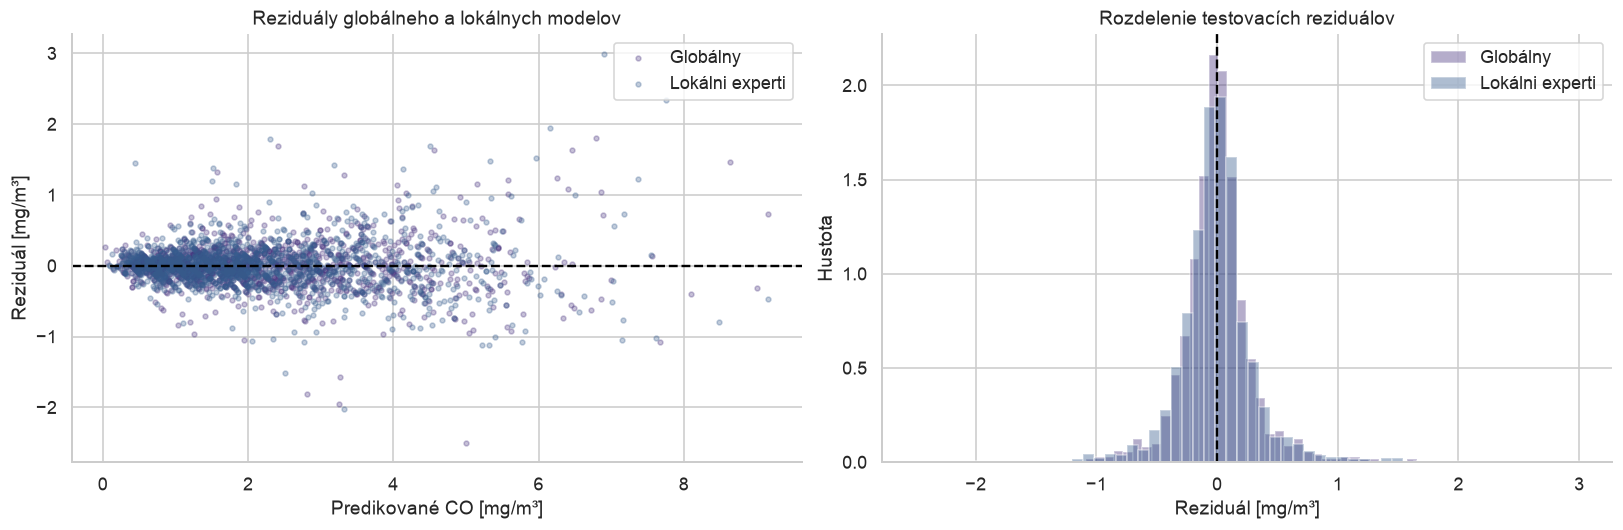

In [149]:
local_models={}
local_train_prediction=np.empty(len(X_train))
local_test_prediction=np.empty(len(X_test))
cluster_eval=[]
for group in range(K):
    tr=np.flatnonzero(train_cluster==group)
    te=np.flatnonzero(test_cluster==group)
    assert len(tr)>30 and len(te)>1
    local=make_pipeline(best_base_estimator)
    with threadpool_limits(limits=1):local.fit(X_train.iloc[tr],y_train.iloc[tr])
    local_models[group]=local
    local_train_prediction[tr]=local.predict(X_train.iloc[tr])
    local_test_prediction[te]=local.predict(X_test.iloc[te])
    for label,y,p in [
        ("Lokálny tréning",y_train.iloc[tr],local_train_prediction[tr]),
        ("Lokálny test",y_test.iloc[te],local_test_prediction[te]),
        ("Globálny test",y_test.iloc[te],best_model.predict(X_test.iloc[te]))]:
        cluster_eval.append({"Zhluk":group,"Hodnotenie":label,"n":len(y),**regression_metrics(y,p)})
cluster_metrics=pd.DataFrame(cluster_eval)
display(cluster_metrics.round(4))
cluster_aggregate=pd.DataFrame([
    {"Model":"Globálny","Množina":"Tréning",**regression_metrics(y_train,best_model.predict(X_train))},
    {"Model":"Lokálni experti","Množina":"Tréning",**regression_metrics(y_train,local_train_prediction)},
    {"Model":"Globálny","Množina":"Test",**regression_metrics(y_test,best_model.predict(X_test))},
    {"Model":"Lokálni experti","Množina":"Test",**regression_metrics(y_test,local_test_prediction)},
])
display(cluster_aggregate.round(4))
fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
for name,p in [("Globálny",best_test_pred),("Lokálni experti",local_test_prediction)]:
    e=np.asarray(y_test)-p
    axes[0].scatter(p,e,s=9,alpha=.3,label=name)
    axes[1].hist(e,bins=55,density=True,alpha=.4,label=name)
axes[0].axhline(0,color="black",linestyle="--")
axes[1].axvline(0,color="black",linestyle="--")
axes[0].set(title="Reziduály globálneho a lokálnych modelov",xlabel="Predikované CO [mg/m³]",ylabel="Reziduál [mg/m³]")
axes[1].set(title="Rozdelenie testovacích reziduálov",xlabel="Reziduál [mg/m³]",ylabel="Hustota")
for ax in axes:ax.legend()
plt.show()
local_m=regression_metrics(y_test,local_test_prediction)
global_m=regression_metrics(y_test,best_test_pred)
for group in range(K):
    group_result=cluster_metrics[(cluster_metrics.Zhluk==group)&cluster_metrics.Hodnotenie.eq("Lokálny test")].iloc[0]
    global_result=cluster_metrics[(cluster_metrics.Zhluk==group)&cluster_metrics.Hodnotenie.eq("Globálny test")].iloc[0]


**Zhluk 0:** 328 testovacích meraní, lokálna RMSE 0.3488 oproti globálnej 0.3119 $\mathrm{mg}/\mathrm{m}^3$. Rozdelenie nepomohlo chybe v tejto skupine.

**Zhluk 1:** 295 testovacích meraní, lokálna RMSE 0.2275 oproti globálnej 0.2019 $\mathrm{mg}/\mathrm{m}^3$. Rozdelenie nepomohlo chybe v tejto skupine.

**Zhluk 2:** 364 testovacích meraní, lokálna RMSE 0.4289 oproti globálnej 0.4022 $\mathrm{mg}/\mathrm{m}^3$. Rozdelenie nepomohlo chybe v tejto skupine.

**Zhluk 3:** 482 testovacích meraní, lokálna RMSE 0.2832 oproti globálnej 0.2742 $\mathrm{mg}/\mathrm{m}^3$. Rozdelenie nepomohlo chybe v tejto skupine.

Všetci lokálni experti spolu dosahujú **$R^2 = 0.9472$**, $\mathrm{RMSE} = \boldsymbol{0.3309\,\mathrm{mg}/\mathrm{m}^3}$, oproti globálnym 0.3077 $\mathrm{mg}/\mathrm{m}^3$. Zmena RMSE je +0.0232 $\mathrm{mg}/\mathrm{m}^3$. Spoločné metriky sú počítané zo všetkých spojených predikcií, nie priemerovaním $R^2$ zhlukov. Lokálne modely majú menej dát a nevidia susedné režimy. Segmentácia preto nemusí pomôcť ani pri viditeľných zhlukoch. Priemerný reziduál lokálnych predikcií je 0.0055 $\mathrm{mg}/\mathrm{m}^3$.

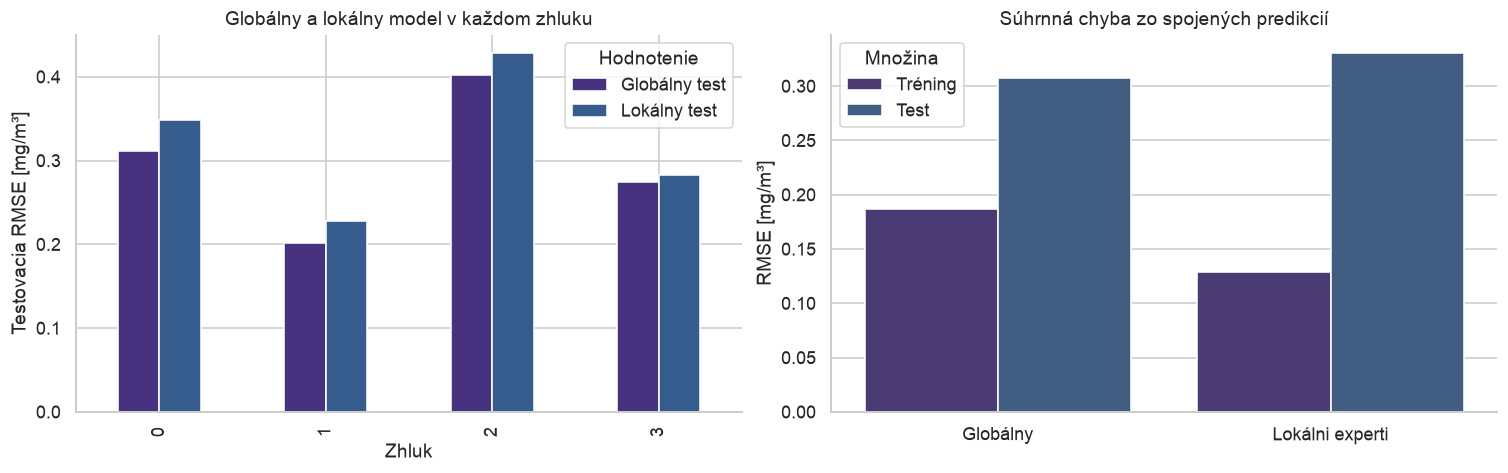

In [150]:
local_test_comparison = cluster_metrics[cluster_metrics.Hodnotenie.isin(['Lokálny test', 'Globálny test'])].pivot(index='Zhluk', columns='Hodnotenie', values='RMSE')
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
local_test_comparison.plot.bar(ax=axes[0])
axes[0].set(title='Globálny a lokálny model v každom zhluku', ylabel='Testovacia RMSE [mg/m³]', xlabel='Zhluk')
sns.barplot(data=cluster_aggregate, x='Model', y='RMSE', hue='Množina', ax=axes[1])
axes[1].set(title='Súhrnná chyba zo spojených predikcií', ylabel='RMSE [mg/m³]', xlabel='')
plt.show()

Lokálne modely majú nižšiu tréningovú chybu, ale v každom zo štyroch zhlukov vyššiu testovaciu RMSE než globálny model. Rozdelenie vstupov na zhluky preto v tomto experimente nezlepšilo predikciu CO. Súhrnná RMSE je vypočítaná zo všetkých spojených predikcií, nie priemerom zhlukových RMSE.

# Neurónová sieť – bonus
## Architektúra a vyhľadávanie
### Výstup, aktivácie a optimalizácia

Sieť má jeden **lineárny výstup koncentrácie**, bez sigmoidy a bez tried. Minimalizuje MSE v pôvodných jednotkách CO pomocou AdamW. ReLU vracia `max(0, x)`, Tanh hodnoty medzi −1 a 1 a GELU hladko váži vstup podľa normálneho rozdelenia. Zápornú predikciu po tréningu neorezávam, aby sa metrika nemenila dodatočným pravidlom.

`GridSearchCV` porovná štyri architektúry **64 → 32**, **256 → 128**, **1028 → 256 → 128** a **512 → 512 → 256 → 128**, tri aktivácie **ReLU, GELU, Tanh** a learning rate **0,001 / 0,003**. Ide o **24 konfigurácií**. Z dôvodu výpočtovej náročnosti neurónová časť používa 2-fold CV a CPU s jedným vláknom. Klasické modely používali 3-fold CV, preto ich CV skóre nie sú úplne rovnocenné. Test je spoločný.

### Early stopping a finálny tréning

Každý `fit` oddelí 15 % svojich tréningových dát len na určenie počtu epoch. Vlastný vnútorný škálovač sa učí iba zo zvyšných 85 %. Po najviac 100 epochách, alebo po 10 epochách bez zlepšenia aspoň 0,0001, sa vyberie epocha najnižšej validačnej MSE. Potom vytvorím novú sieť s rovnakým seedom a trénujem ju na **všetkých dátach daného fitu** presne tento počet epoch. Tým sa early-stopping podmnožina vracia do finálneho učenia. Žiadna časť vonkajšieho testu sa na to nepoužíva.

Vo výstupe zobrazím **iba víťaznú konfiguráciu neurónovej siete**, jej krivky, metriky a reziduály. Jednotlivé experimenty zostanú dostupné v objekte `nn_search.cv_results_` v pamäti. Krivky patria fáze určovania počtu epoch, finálne metriky následnému tréningu na celom tréningu.

In [151]:
class TorchRegressor(RegressorMixin,BaseEstimator):
    def __init__(self,hidden=(64,32),activation="relu",lr=.001,batch_size=256,
                 max_epochs=100,patience=10,min_delta=1e-4,weight_decay=1e-4,random_state=SEED):
        self.hidden=hidden
        self.activation=activation
        self.lr=lr
        self.batch_size=batch_size
        self.max_epochs=max_epochs
        self.patience=patience
        self.min_delta=min_delta
        self.weight_decay=weight_decay
        self.random_state=random_state

    def _network(self,inputs):
        activations={"relu":nn.ReLU,"gelu":nn.GELU,"tanh":nn.Tanh}
        layers=[]
        previous=inputs
        for width in self.hidden:
            layers.extend([nn.Linear(previous,width),activations[self.activation]()])
            previous=width
        layers.append(nn.Linear(previous,1))
        return nn.Sequential(*layers)

    def _fresh(self,inputs):
        torch.manual_seed(self.random_state)
        model=self._network(inputs)
        optimizer=torch.optim.AdamW(model.parameters(),lr=self.lr,weight_decay=self.weight_decay)
        return model,optimizer

    def _epoch(self,model,optimizer,x,y,generator):
        model.train()
        order=torch.randperm(len(x),generator=generator)
        for ids in order.split(self.batch_size):
            optimizer.zero_grad(set_to_none=True)
            loss=nn.functional.mse_loss(model(x[ids]).squeeze(1),y[ids])
            if not torch.isfinite(loss):raise RuntimeError("Neplatná strata neurónovej siete")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),10.)
            optimizer.step()

    def fit(self,X,y):
        values=np.asarray(X,dtype=np.float32)
        labels=np.asarray(y,dtype=np.float32).reshape(-1)
        self.n_features_in_=values.shape[1]
        fit_ids,stop_ids=train_test_split(np.arange(len(values)),test_size=.15,random_state=self.random_state)
        stop_scaler=StandardScaler().fit(values[fit_ids])
        fit_x=torch.tensor(stop_scaler.transform(values[fit_ids]),dtype=torch.float32)
        fit_y=torch.tensor(labels[fit_ids])
        stop_x=torch.tensor(stop_scaler.transform(values[stop_ids]),dtype=torch.float32)
        stop_y=torch.tensor(labels[stop_ids])
        model,optimizer=self._fresh(values.shape[1])
        generator=torch.Generator().manual_seed(self.random_state)
        best_loss,reference=float("inf"),float("inf")
        wait=0
        history=[]
        for epoch in range(1,self.max_epochs+1):
            self._epoch(model,optimizer,fit_x,fit_y,generator)
            model.eval()
            with torch.no_grad():
                train_loss=nn.functional.mse_loss(model(fit_x).squeeze(1),fit_y).item()
                stop_loss=nn.functional.mse_loss(model(stop_x).squeeze(1),stop_y).item()
            history.append({"Epocha":epoch,"Tréning MSE":train_loss,"Validácia MSE":stop_loss})
            if stop_loss<best_loss:
                best_loss=stop_loss
                self.selected_epoch_=epoch
            if stop_loss<reference-self.min_delta:
                reference=stop_loss
                wait=0
            else:wait+=1
            if wait>=self.patience:break
        self.history_=pd.DataFrame(history)
        self.scaler_=StandardScaler().fit(values)
        full_x=torch.tensor(self.scaler_.transform(values),dtype=torch.float32)
        full_y=torch.tensor(labels)
        self.model_,optimizer=self._fresh(values.shape[1])
        generator=torch.Generator().manual_seed(self.random_state)
        for _ in range(self.selected_epoch_):
            self._epoch(self.model_,optimizer,full_x,full_y,generator)
        self.model_.eval()
        return self

    def predict(self,X):
        self.model_.eval()
        x=torch.tensor(self.scaler_.transform(np.asarray(X,dtype=np.float32)),dtype=torch.float32)
        with torch.no_grad():return self.model_(x).squeeze(1).numpy()

nn_grid={
    "estimator__model__hidden":[(64,32),(256,128),(1028,256,128),(512,512,256,128)],
    "estimator__model__activation":["relu","gelu","tanh"],
    "estimator__model__lr":[.001,.003],
}
nn_cv=KFold(n_splits=2,shuffle=True,random_state=SEED)
nn_search=GridSearchCV(make_pipeline(TorchRegressor()),nn_grid,
    scoring=SCORING,refit="mse",cv=nn_cv,n_jobs=1,return_train_score=True,error_score="raise",verbose=0)
nn_started=time.perf_counter()
print(f"Spúšťam neurónovú mriežku: {len(ParameterGrid(nn_grid))} konfigurácií, 48 CV tréningov a finálny refit.",flush=True)
with threadpool_limits(limits=1):nn_search.fit(X_train,y_train)
nn_seconds=time.perf_counter()-nn_started
nn_best=nn_search.best_estimator_
nn_model=nn_best.estimator_.named_steps["model"]
nn_parameters={key.replace("estimator__model__",""):value for key,value in nn_search.best_params_.items()}
print("Najlepšia konfigurácia:",nn_parameters)
print("Pevné nastavenia:",{"optimizer":"AdamW","batch_size":nn_model.batch_size,"max_epochs":nn_model.max_epochs,
                           "patience":nn_model.patience,"weight_decay":nn_model.weight_decay,"seed":SEED})
print("Vybraná epocha:",nn_model.selected_epoch_,"| Počet parametrov:",sum(p.numel() for p in nn_model.model_.parameters()))
print("Čas mriežky [s]:",round(nn_seconds,1))
nn_metrics=pd.DataFrame(evaluate_model("Neurónová sieť",nn_best)).set_index("Množina")
display(nn_metrics.drop(columns="Model").round(4))


Spúšťam neurónovú mriežku: 24 konfigurácií, 48 CV tréningov a finálny refit.
Najlepšia konfigurácia: {'activation': 'relu', 'hidden': (1028, 256, 128), 'lr': 0.001}
Pevné nastavenia: {'optimizer': 'AdamW', 'batch_size': 256, 'max_epochs': 100, 'patience': 10, 'weight_decay': 0.0001, 'seed': 2026}
Vybraná epocha: 92 | Počet parametrov: 314953
Čas mriežky [s]: 76.9


,MSE,RMSE,MAE,R²
Množina,,,,
Tréning,0.0284,0.1684,0.1248,0.9862
Test,0.0944,0.3072,0.2113,0.9544


Víťazná sieť má skryté vrstvy **1028 → 256 → 128**, aktiváciu **RELU** a learning rate **0.001**. CV RMSE je **0.3430 $\mathrm{mg}/\mathrm{m}^3$**, finálne testovacie $R^2$ **0.9544** a RMSE **0.3072 $\mathrm{mg}/\mathrm{m}^3$**. Tréningové $R^2$ je 0.9862. Výsledok vychádza z CV výberu, nie z výberu najlepšej siete podľa testu. Väčšia architektúra automaticky neznamená lepšiu generalizáciu, najmä na niekoľkých tisícoch meraní.

In [152]:
nn_index = nn_search.best_index_
nn_cv_summary = pd.DataFrame([
    {'Hodnotenie': 'CV tréning – priemer', 'R²': nn_search.cv_results_['mean_train_r2'][nn_index],
     'SD R²': nn_search.cv_results_['std_train_r2'][nn_index], 'MSE': -nn_search.cv_results_['mean_train_mse'][nn_index]},
    {'Hodnotenie': 'CV validácia – priemer', 'R²': nn_search.cv_results_['mean_test_r2'][nn_index],
     'SD R²': nn_search.cv_results_['std_test_r2'][nn_index], 'MSE': -nn_search.cv_results_['mean_test_mse'][nn_index]},
]).set_index('Hodnotenie')
nn_cv_summary['RMSE'] = np.sqrt(nn_cv_summary.MSE)
display(nn_cv_summary.round(4))

,R²,SD R²,MSE,RMSE
Hodnotenie,,,,
CV tréning – priemer,0.9688,0.0035,0.0642,0.2534
CV validácia – priemer,0.9429,0.0060,0.1177,0.3430


Neurónová sieť používa **dva CV foldy**, klasické modely tri. Hodnoty v tabuľke patria vonkajším CV foldom neurónovej mriežky; validačná krivka nižšie patrí samostatnej vnútornej early-stopping množine. Ide o dve rozdielne úrovne validácie.

## Diagnostika najlepšej siete
### Učenie, reziduály a porovnanie s klasickými modelmi

Krivky MSE a RMSE zobrazujú tú istú chybu v rôznych mierkach. Prerušovaná čiara označuje zvolený počet epoch. Rast validačnej chyby pri pokračujúcom poklese tréningovej je signál preučenia. Reziduály finálneho refitu následne porovnám s rovnakou definíciou ako pri ostatných regresoroch.

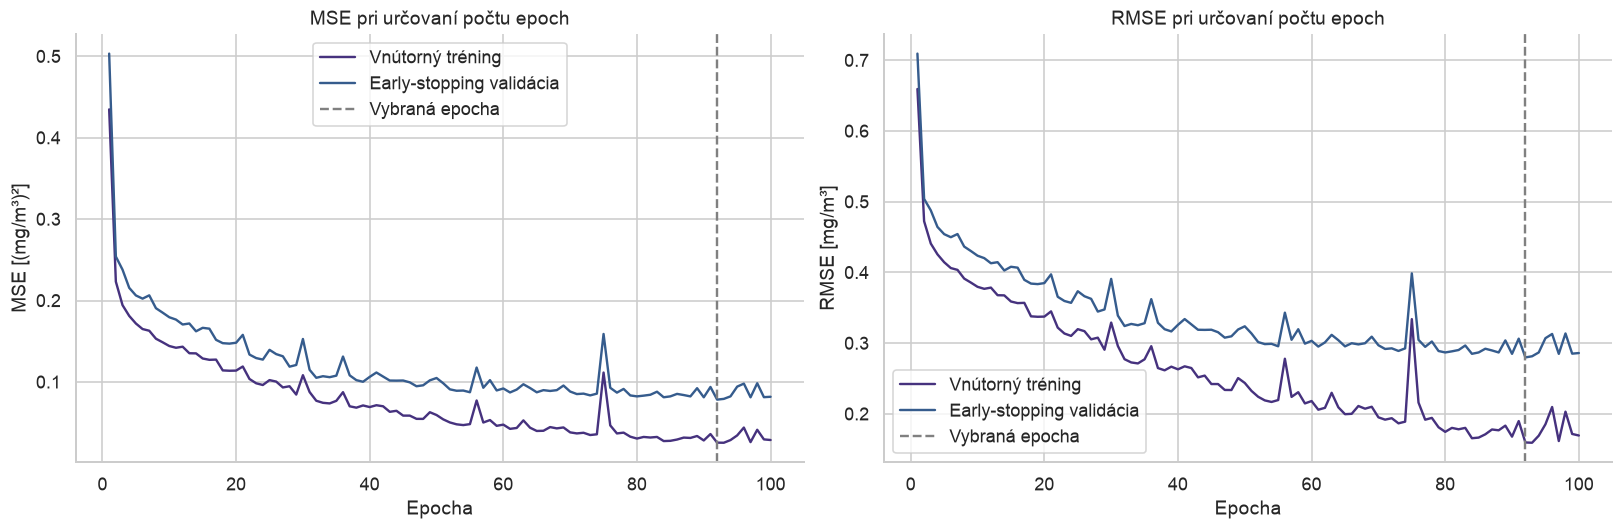

In [153]:
history=nn_model.history_
fig,axes=plt.subplots(1,2,figsize=(14,4.5),constrained_layout=True)
for column,label in [("Tréning MSE","Vnútorný tréning"),("Validácia MSE","Early-stopping validácia")]:
    axes[0].plot(history.Epocha,history[column],label=label)
    axes[1].plot(history.Epocha,np.sqrt(history[column]),label=label)
for ax in axes:
    ax.axvline(nn_model.selected_epoch_,color="gray",linestyle="--",label="Vybraná epocha")
    ax.set_xlabel("Epocha")
    ax.legend()
axes[0].set(title="MSE pri určovaní počtu epoch",ylabel="MSE [(mg/m³)²]")
axes[1].set(title="RMSE pri určovaní počtu epoch",ylabel="RMSE [mg/m³]")
plt.show()
selected_history=history.loc[history.Epocha.eq(nn_model.selected_epoch_)].iloc[0]


Early stopping vybral **92. epochu** z 100 vykonaných. V nej bola vnútorná tréningová MSE 0.0255 a validačná MSE 0.0783. Finálna sieť sa potom učila od začiatku na všetkých tréningových inlieroch. Jej testovacie metriky preto nemusia zodpovedať minimu tejto vnútornej krivky.

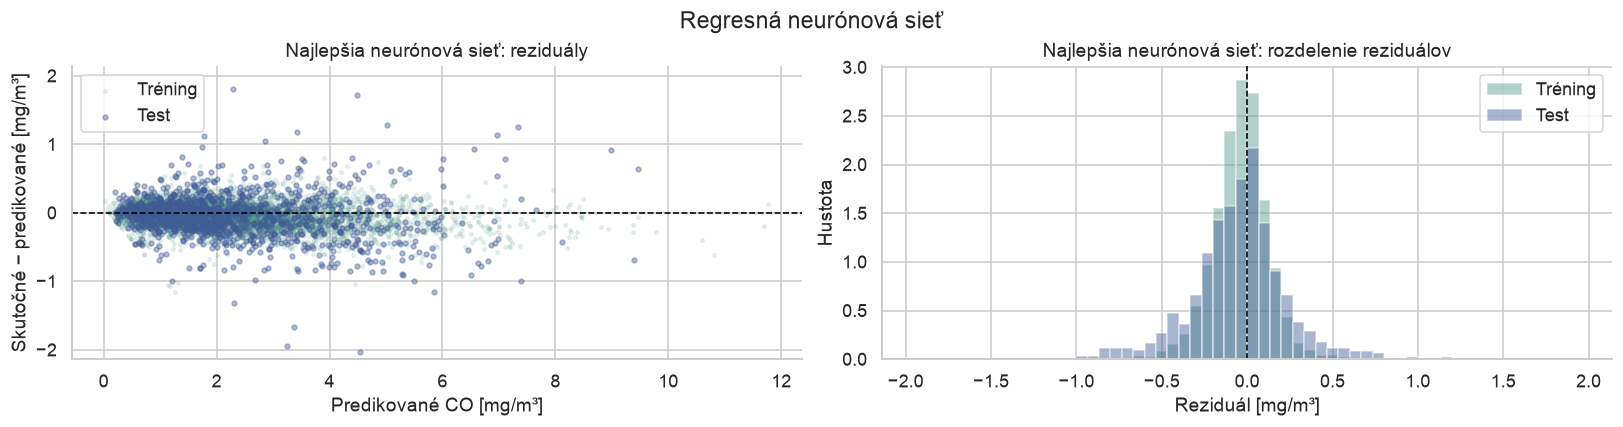

,Priemer reziduála,Medián reziduála,95. percentil |e|,Korelácia |e| a predikcie
Model,,,,
Najlepšia neurónová sieť,-0.0473,-0.0311,0.6438,0.4249


In [154]:
nn_residuals=plot_residuals({"Najlepšia neurónová sieť":nn_best},"Regresná neurónová sieť")


**Najlepšia neurónová sieť:** priemerný testovací reziduál -0.0473 $\mathrm{mg}/\mathrm{m}^3$ znamená nadhodnotenie v priemere. 95 % absolútnych chýb neprekračuje **0.644 $\mathrm{mg}/\mathrm{m}^3$**. Korelácia veľkosti chyby s predikciou je 0.425. Chyby majú tendenciu rásť s predikovanou koncentráciou.

In [155]:
negative_predictions=int((nn_best.predict(X_test)<0).sum())


Lineárny výstup vytvoril **0 záporných testovacích predikcií**. CO je fyzikálne nezáporné. Záporné odhady by boli obmedzením nekontrolovaného regresného výstupu. Dodatočne ich neorezávam ani podľa nich nemením architektúru.

### Permutačná dôležitosť neurónovej siete

Rovnakým spôsobom ako pri klasických modeloch zmeriam pokles testovacieho R² po premiešaní pôvodného vstupu. Sieť ani hyperparametre podľa týchto výsledkov nemením.

,Pokles R²,SD
sensor_nmhc,0.85174,0.01665
month,0.49292,0.01960
season,0.29746,0.02127
temperature,0.29013,0.00819
sensor_no2,0.16264,0.00596
sensor_co,0.13508,0.00427
hour,0.07966,0.00394
humidity,0.07428,0.00253
sensor_o3,0.05428,0.00091
weekday,0.04097,0.00324


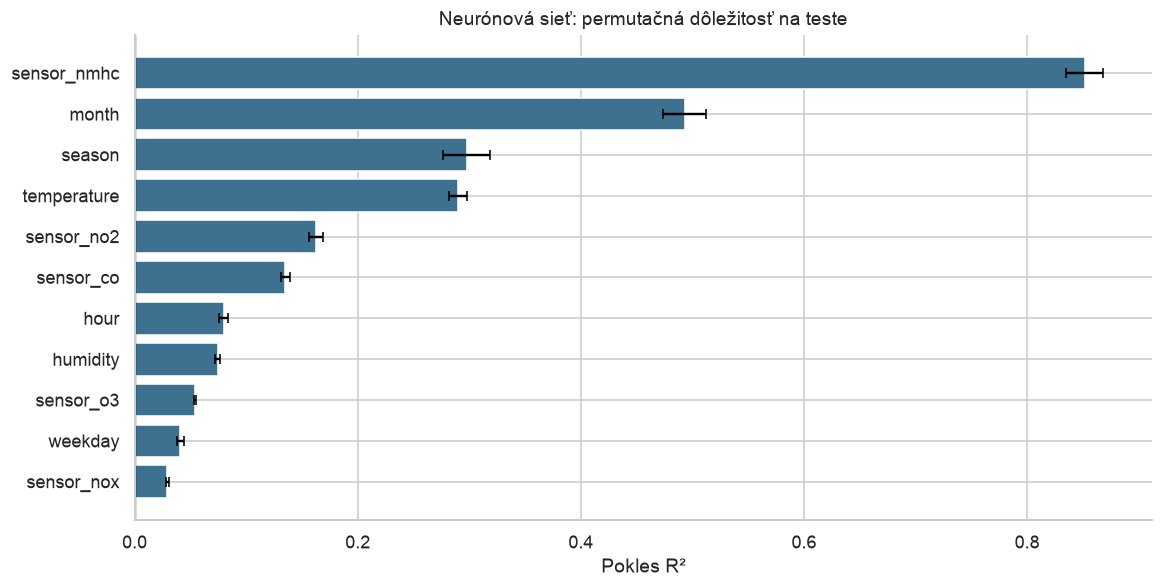

In [156]:
with threadpool_limits(limits=1):
    nn_permutation = permutation_importance(nn_best, X_test, y_test, scoring='r2', n_repeats=5, random_state=SEED, n_jobs=1)
nn_importance = pd.DataFrame({'Pokles R²': nn_permutation.importances_mean, 'SD': nn_permutation.importances_std}, index=X_test.columns).sort_values('Pokles R²', ascending=False)
display(nn_importance.round(5))
nn_shown = nn_importance.sort_values('Pokles R²')
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.barh(nn_shown.index, nn_shown['Pokles R²'], xerr=nn_shown.SD, color='#3e718f', capsize=3)
ax.axvline(0, color='black', linewidth=.8)
ax.set(title='Neurónová sieť: permutačná dôležitosť na teste', xlabel='Pokles R²')
plt.show()


Pri neurónovej sieti má najväčší permutačný význam **sensor_nmhc**: pokles testovacieho R² **0.8517 ± 0.0166**. Poradie opisuje závislosť konkrétnej siete od vstupov na tomto teste. Nejde o veľkosť váh neurónov ani príčinný účinok; päť opakovaní vyjadruje len variabilitu premiešania.

## Celkové zhodnotenie
### Výsledky a hranice interpretácie

Nasledujúca tabuľka porovnáva vopred zvolené klasické modely a jedinú CV víťaznú neurónovú sieť na spoločnom teste. Závery o zhlukovaní a redukcii vychádzajú zo samostatných porovnaní vyššie. Výsledok je odhad chyby na tomto rozdelení, nie záruka rovnakého výkonu na inom senzore, lokalite či budúcom období.

In [157]:
final_test=pd.concat([test_metrics[["MSE","RMSE","MAE","R²"]],
                      nn_metrics.loc[["Test"],["MSE","RMSE","MAE","R²"]].rename(index={"Test":"Neurónová sieť"})])
display(final_test.sort_values("MSE").round(4))
best_reduced=selection_results["Test MSE"].idxmin()
comparison_word="nižšiu" if nn_metrics.loc["Test","RMSE"]<test_metrics.loc[BEST_NAME,"RMSE"] else "vyššiu"


,MSE,RMSE,MAE,R²
Neurónová sieť,0.0944,0.3072,0.2113,0.9544
SVR,0.0947,0.3077,0.1994,0.9543
XGBoost,0.1204,0.3470,0.2241,0.9419
HistGradientBoosting,0.1210,0.3478,0.2283,0.9416
ExtraTrees,0.1216,0.3486,0.2221,0.9413
RandomForest,0.1402,0.3744,0.2354,0.9323
DecisionTree,0.2007,0.4480,0.3004,0.9031


**Hlavný model vybraný podľa CV je SVR**, s testovacím $R^2$ **0.9543** a RMSE **0.3077 $\mathrm{mg}/\mathrm{m}^3$**. Najlepšia neurónová sieť má nižšiu RMSE (0.3072 $\mathrm{mg}/\mathrm{m}^3$). Z porovnania redukcií má opisne najnižšiu testovaciu MSE stratégia **Všetky príznaky**. Nie je to ďalšie ladenie hlavného modelu. Lokálni experti zmenili RMSE oproti globálnemu modelu o +0.0232 $\mathrm{mg}/\mathrm{m}^3$.

**Čo výsledky znamenajú:** senzory obsahujú silnú informáciu o CO, ale vysoké koncentrácie a odľahlé merania ostávajú náročnejšie. Hodnotenie zachováva všetky platné testovacie extrémy. Čistenie odstránilo neúplné merania, a tým mohlo zmeniť zastúpenie prevádzkových podmienok. Náhodná CV mieša susedné hodiny. Pred nasadením na budúce obdobie by bolo potrebné chronologické delenie s časovou medzerou a samostatné overenie driftu senzorov. Rozdiely malých hodnôt RMSE bez opakovaných časových experimentov nemožno považovať za stabilné poradie.

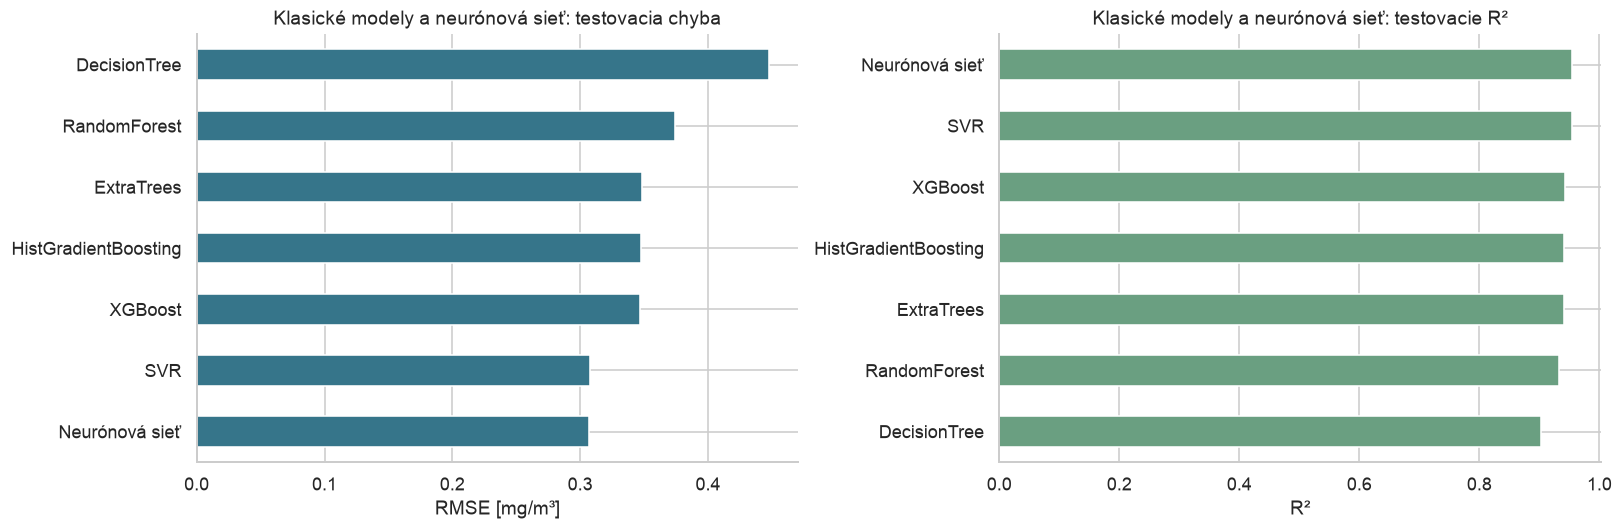

In [158]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
final_test.sort_values('RMSE').RMSE.plot.barh(ax=axes[0], color='#36758a')
axes[0].set(title='Klasické modely a neurónová sieť: testovacia chyba', xlabel='RMSE [mg/m³]', ylabel='')
final_test.sort_values('R²')['R²'].plot.barh(ax=axes[1], color='#6a9f81')
axes[1].set(title='Klasické modely a neurónová sieť: testovacie R²', xlabel='R²', ylabel='')
plt.show()

Neurónová sieť a SVR majú na tomto teste veľmi blízku RMSE. Rozdiel jedného rozdelenia nemožno považovať za stabilné poradie bez ďalších nezávislých experimentov. Hlavný klasický model zostáva vybraný podľa tréningovej CV, nie podľa testu.